# Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from catboost import CatBoostRegressor, Pool, cv
import xgboost
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, root_mean_squared_error

import shap
from sklearn.inspection import PartialDependenceDisplay

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

# Load Data

In [3]:
train = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv", index_col="Id")
test = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv", index_col="Id")

MSSubClass_map = {
    20:	"1-STORY 1946 & NEWER ALL STYLES",
    30:	"1-STORY 1945 & OLDER",
    40:	"1-STORY W/FINISHED ATTIC ALL AGES",
    45:	"1-1/2 STORY - UNFINISHED ALL AGES",
    50:	"1-1/2 STORY FINISHED ALL AGES",
    60:	"2-STORY 1946 & NEWER",
    70:	"2-STORY 1945 & OLDER",
    75:	"2-1/2 STORY ALL AGES",
    80:	"SPLIT OR MULTI-LEVEL",
    85:	"SPLIT FOYER",
    90:	"DUPLEX - ALL STYLES AND AGES",
    120: "1-STORY PUD (Planned Unit Development) - 1946 & NEWER",
    150: "1-1/2 STORY PUD - ALL AGES",
    160: "2-STORY PUD - 1946 & NEWER",
    180: "PUD - MULTILEVEL - INCL SPLIT LEV/FOYER",
    190: "2 FAMILY CONVERSION - ALL STYLES AND AGES"
}

train["MSSubClass"] = train["MSSubClass"].map(MSSubClass_map)
test["MSSubClass"] = test["MSSubClass"].map(MSSubClass_map)

# First Glance

In [4]:
train.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,2-STORY 1946 & NEWER,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,1-STORY 1946 & NEWER ALL STYLES,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,2-STORY 1946 & NEWER,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,2-STORY 1945 & OLDER,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,2-STORY 1946 & NEWER,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
train.shape

(1460, 80)

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1460 entries, 1 to 1460
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   object 
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt    

In [7]:
train.describe(include="number")

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1379.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,567.240411,1057.429452,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,6.517808,0.613014,1978.506164,1.767123,472.980137,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,441.866955,438.705324,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,1.625393,0.644666,24.689725,0.747315,213.804841,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,0.000000,0.000000,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1900.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,223.000000,795.750000,882.000000,0.000000,0.000000,1129.500000,0.000000,0.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,1961.000000,1.000000,334.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,477.500000,991.500000,1087.000000,0.000000,0.000000,1464.000000,0.000000,0.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,1980.000000,2.000000,480.000000,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,808.000000,1298.250000,1391.250000,728.000000,0.000000,1776.750000,1.000000,0.000000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,2002.000000,2.000000,576.000000,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,2336.000000,6110.000000,4692.000000,2065.000000,572.000000,5642.000000,3.000000,2.000000,3.000000,2.000000,8.000000,3.000000,14.000000,3.000000,2010.000000,4.000000,1418.000000,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [8]:
display((train.isnull().sum()[train.isnull().sum() !=0] / len(train)).sort_values(ascending=False))

PoolQC          0.995205
MiscFeature     0.963014
Alley           0.937671
Fence           0.807534
MasVnrType      0.597260
FireplaceQu     0.472603
LotFrontage     0.177397
GarageType      0.055479
GarageYrBlt     0.055479
GarageFinish    0.055479
GarageQual      0.055479
GarageCond      0.055479
BsmtExposure    0.026027
BsmtFinType2    0.026027
BsmtQual        0.025342
BsmtCond        0.025342
BsmtFinType1    0.025342
MasVnrArea      0.005479
Electrical      0.000685
dtype: float64

As we can see, there are many columns with Null values in them. If we look through the data_description.txt file we are informed that some columns have Null values as a category for absence of, so we'll handle them later on

# Logical Null Values Encoding

If we read the data_description.txt file, we are told that there are Null Values corresponding to the absence of. We will enconde them to having them in our study

In [9]:
display(train["PoolQC"].value_counts(dropna=False).rename("Value Counts of PoolQC"))
print()
display(train["PoolArea"].value_counts().rename("Value Counts of PoolArea"))
print()
display(train[train["PoolQC"].isna()]["PoolArea"].value_counts().rename("Value Counts of PoolArea when PoolQC is Null"))
print()
display(train[train["PoolArea"] == 0]["PoolQC"].value_counts(dropna=False).rename("Value Counts of PoolQc when PoolArea is 0"))

PoolQC
NaN    1453
Gd        3
Ex        2
Fa        2
Name: Value Counts of PoolQC, dtype: int64

PoolArea
0      1453
512       1
648       1
576       1
555       1
480       1
519       1
738       1
Name: Value Counts of PoolArea, dtype: int64

PoolArea
0    1453
Name: Value Counts of PoolArea when PoolQC is Null, dtype: int64

PoolQC
NaN    1453
Name: Value Counts of PoolQc when PoolArea is 0, dtype: int64

We have the same number of Nulls in PoolQC as in PoolArea; also, those 0s in PoolArea correspond to Nulls in PoolQC and vicecersa, so we can convert those Nulls into No Pool

In [10]:
display(train["MiscFeature"].value_counts(dropna=False).rename("Value Counts of PoolQC"))
print()
display(train["MiscVal"].value_counts().rename("Value Counts of PoolArea"))
print()
display(train[train["MiscFeature"].isna()]["MiscVal"].value_counts().rename("Value Counts of MiscVal when MiscFeature is Null"))
print()
display(train[train["MiscVal"] == 0]["MiscFeature"].value_counts(dropna=False).rename("Value Counts of MiscFeature when MiscVal is 0"))

MiscFeature
NaN     1406
Shed      49
Gar2       2
Othr       2
TenC       1
Name: Value Counts of PoolQC, dtype: int64

MiscVal
0        1408
400        11
500         8
700         5
450         4
600         4
2000        4
1200        2
480         2
350         1
15500       1
800         1
3500        1
1300        1
54          1
620         1
560         1
1400        1
8300        1
1150        1
2500        1
Name: Value Counts of PoolArea, dtype: int64

MiscVal
0    1406
Name: Value Counts of MiscVal when MiscFeature is Null, dtype: int64

MiscFeature
NaN     1406
Othr       1
Shed       1
Name: Value Counts of MiscFeature when MiscVal is 0, dtype: int64

We see some discrepancies in the Null values, but we can attribute those unmatching ones to miscellaneous feature that have no value, so we can convert those Nulls into No Miscellaneous

In [11]:
display(train["Fireplaces"].value_counts().rename("Value Counts of Fireplaces"))
print()
display(train["FireplaceQu"].value_counts(dropna=False).rename("Value Counts of FireplaceQu"))
print()
display(train[train["FireplaceQu"].isna()]["Fireplaces"].value_counts().rename("Value Counts of Fireplaces when FireplaceQu is Null"))
print()
display(train[train["Fireplaces"] == 0]["FireplaceQu"].value_counts(dropna=False).rename("Value Counts of FireplaceQu when Fireplaces is 0"))

Fireplaces
0    690
1    650
2    115
3      5
Name: Value Counts of Fireplaces, dtype: int64

FireplaceQu
NaN    690
Gd     380
TA     313
Fa      33
Ex      24
Po      20
Name: Value Counts of FireplaceQu, dtype: int64

Fireplaces
0    690
Name: Value Counts of Fireplaces when FireplaceQu is Null, dtype: int64

FireplaceQu
NaN    690
Name: Value Counts of FireplaceQu when Fireplaces is 0, dtype: int64

Same thing with FireplaceQu

In [12]:
train["PoolQC"] = train["PoolQC"].replace(np.nan, "No Pool")
train["MiscFeature"] = train["MiscFeature"].replace(np.nan, "All Covered")
train["Alley"] = train["Alley"].replace(np.nan, "No Alley Access")
train["Fence"] = train["Fence"].replace(np.nan, "No Fence")
train["FireplaceQu"] = train["FireplaceQu"].replace(np.nan, "No Fireplace")
train["GarageType"] = train["GarageType"].replace(np.nan, "No Garage")
train["GarageYrBlt"] = train["GarageYrBlt"].replace(np.nan, -1)
train["GarageFinish"] = train["GarageFinish"].replace(np.nan, "No Garage")
train["GarageQual"] = train["GarageQual"].replace(np.nan, "No Garage")
train["GarageCond"] = train["GarageCond"].replace(np.nan, "No Garage")

In [13]:
display((train.isnull().sum()[train.isnull().sum() !=0] / len(train)).sort_values(ascending=False))

MasVnrType      0.597260
LotFrontage     0.177397
BsmtExposure    0.026027
BsmtFinType2    0.026027
BsmtQual        0.025342
BsmtFinType1    0.025342
BsmtCond        0.025342
MasVnrArea      0.005479
Electrical      0.000685
dtype: float64

Those columns with Null values present interesting things: MasVnrType has a category for the absence of (None), but it still has Null values. Moreover, if we look at the Nulls in MasVnrArea, we expect to be the same as those Nones in MasVnrType but the numbers don't match. Same thing with Bsmt cols: their null values count don't match. The only ilogical null values are in Electrical column

## MasVnr Columns

In [14]:
display(train["MasVnrType"].value_counts(dropna=False).rename("MasVnrType Count"))
print()
print("0s in MasVnrArea:", train["MasVnrArea"].value_counts().get(0))
print()
display(train[train["MasVnrArea"] < 5]["MasVnrType"].value_counts(dropna=False).rename("MasVnrType Count when MasVnrArea is < 5"))
print()
print("Unique Values of MasVnrArea when MasVnrType is Null:", train[train["MasVnrType"].isna()]["MasVnrArea"].unique())
print("Unique Values of MasVnrType when MasVnrArea is Null", train[train["MasVnrArea"].isna()]["MasVnrType"].unique())

MasVnrType
NaN        872
BrkFace    445
Stone      128
BrkCmn      15
Name: MasVnrType Count, dtype: int64


0s in MasVnrArea: 861



MasVnrType
NaN        861
BrkFace      1
Stone        1
Name: MasVnrType Count when MasVnrArea is < 5, dtype: int64


Unique Values of MasVnrArea when MasVnrType is Null: [  0.  nan 288.   1. 344. 312.]
Unique Values of MasVnrType when MasVnrArea is Null [nan]


We can see some inconsistencies. Null MasVnrType Vales are 872 but Null MasVnrType are 861 and when MasVnrArea is 0 we see not all MasVnrType values are Null. Moreover, when MasVnrType is Null (that is, according to the data_description.txt file, No Masonry) we have MasVnrArea of [0,nan,288,1,344,312]. When MasVnrArea is Null their correspoding MasVnrType values are all Null, which goes along the line of No Masonry

In [15]:
# Logical Values
train.loc[train["MasVnrArea"] < 5, "MasVnrArea"] = 0 # We account for typos in the Area
train["MasVnrArea"] = train["MasVnrArea"].fillna(0) # When MasVnrArea is Null, MasVnrType is also Null so we can assume absence
train["MasVnrType"] = train["MasVnrType"].fillna("No Masonry")

# Ilogical Values
mask = (train["MasVnrArea"] > 15) & (train["MasVnrType"] == "No Masonry")
train.loc[mask, "MasVnrType"] = np.nan

mask = (train["MasVnrArea"] == 0) & (train["MasVnrType"] != "No Masonry")
train.loc[mask, "MasVnrType"] = "No Masonry"

In [16]:
train.groupby(train["MasVnrArea"] > 15)["MasVnrType"].value_counts()

MasVnrArea  MasVnrType
False       No Masonry    871
            BrkFace         2
True        BrkFace       442
            Stone         127
            BrkCmn         15
Name: count, dtype: int64

In [17]:
display(train["MasVnrType"].value_counts(dropna=False).rename("MasVnrType Count"))
print()
print("0s in MasVnrArea:", train["MasVnrArea"].value_counts().get(0))
print()
display(train[train["MasVnrArea"] < 5]["MasVnrType"].value_counts(dropna=False).rename("MasVnrType Count when MasVnrArea is < 5"))
print()
print("Unique Values of MasVnrArea when MasVnrType is Null:", train[train["MasVnrType"].isna()]["MasVnrArea"].unique())
print("Unique Values of MasVnrType when MasVnrArea is Null", train[train["MasVnrArea"].isna()]["MasVnrType"].unique())

MasVnrType
No Masonry    871
BrkFace       444
Stone         127
BrkCmn         15
NaN             3
Name: MasVnrType Count, dtype: int64


0s in MasVnrArea: 871



MasVnrType
No Masonry    871
Name: MasVnrType Count when MasVnrArea is < 5, dtype: int64


Unique Values of MasVnrArea when MasVnrType is Null: [288. 344. 312.]
Unique Values of MasVnrType when MasVnrArea is Null []


## Bsmt Columns

In [18]:
display((train.isnull().sum()[train.isnull().sum() !=0]).sort_values(ascending=False))

LotFrontage     259
BsmtExposure     38
BsmtFinType2     38
BsmtQual         37
BsmtFinType1     37
BsmtCond         37
MasVnrType        3
Electrical        1
dtype: int64

In [19]:
train.loc[train["BsmtFinType1"].isna() & train["BsmtFinType2"].isna() & train["BsmtExposure"].isna() & train["BsmtCond"].isna() & train["BsmtQual"].isna(), ["BsmtFinType1", "BsmtFinType2", "BsmtExposure", "BsmtCond", "BsmtQual"]] = "No Basement"

In [20]:
display((train.isnull().sum()[train.isnull().sum() !=0]).sort_values(ascending=False))

LotFrontage     259
MasVnrType        3
BsmtExposure      1
BsmtFinType2      1
Electrical        1
dtype: int64

# Univariate Analysis 

In [21]:
cat_vars = train.select_dtypes("object").columns
ordinal_cat_vars = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
                    "HeatingQC", "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC", "Fence"]
nominal_cat_vars = cat_vars.difference(ordinal_cat_vars)

num_vars = train.select_dtypes("number").columns
discrete_num_vars = ["OverallQual", "OverallCond", "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath", "BedroomAbvGr", 
                     "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageCars", "MoSold", "YrSold"]
continous_num_vars = num_vars.difference(discrete_num_vars)


print("Categorical Features:", len(cat_vars))
print("Ordinal Categorical Features:", len(ordinal_cat_vars))
print("Nominal Categorical Features", len(nominal_cat_vars))
print("="*30)
print("Numerical Features:", len(num_vars))
print("Discrete Numerical Features:", len(discrete_num_vars))
print("Continous Numerical Features:", len(continous_num_vars))

Categorical Features: 44
Ordinal Categorical Features: 14
Nominal Categorical Features 30
Numerical Features: 36
Discrete Numerical Features: 13
Continous Numerical Features: 23


## Categorical Features

### Ordinal Features

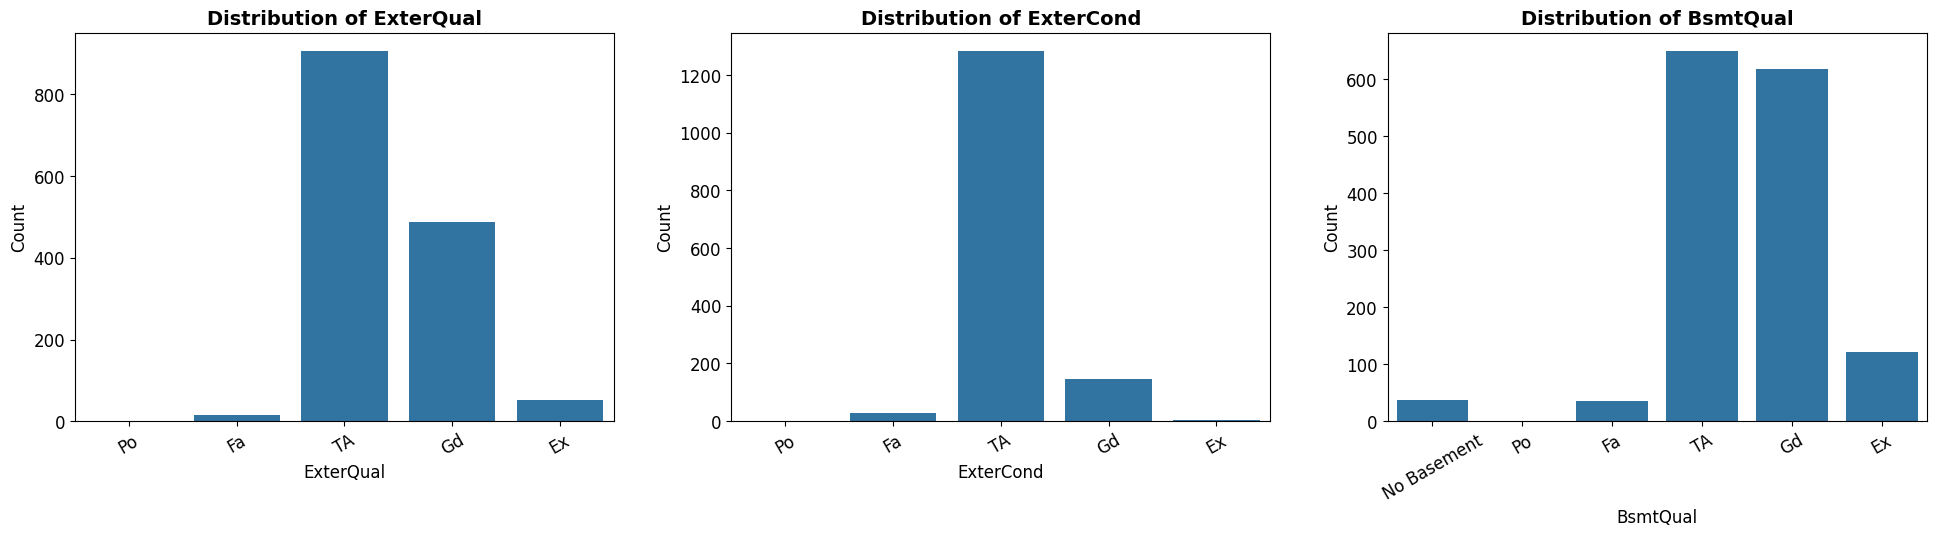

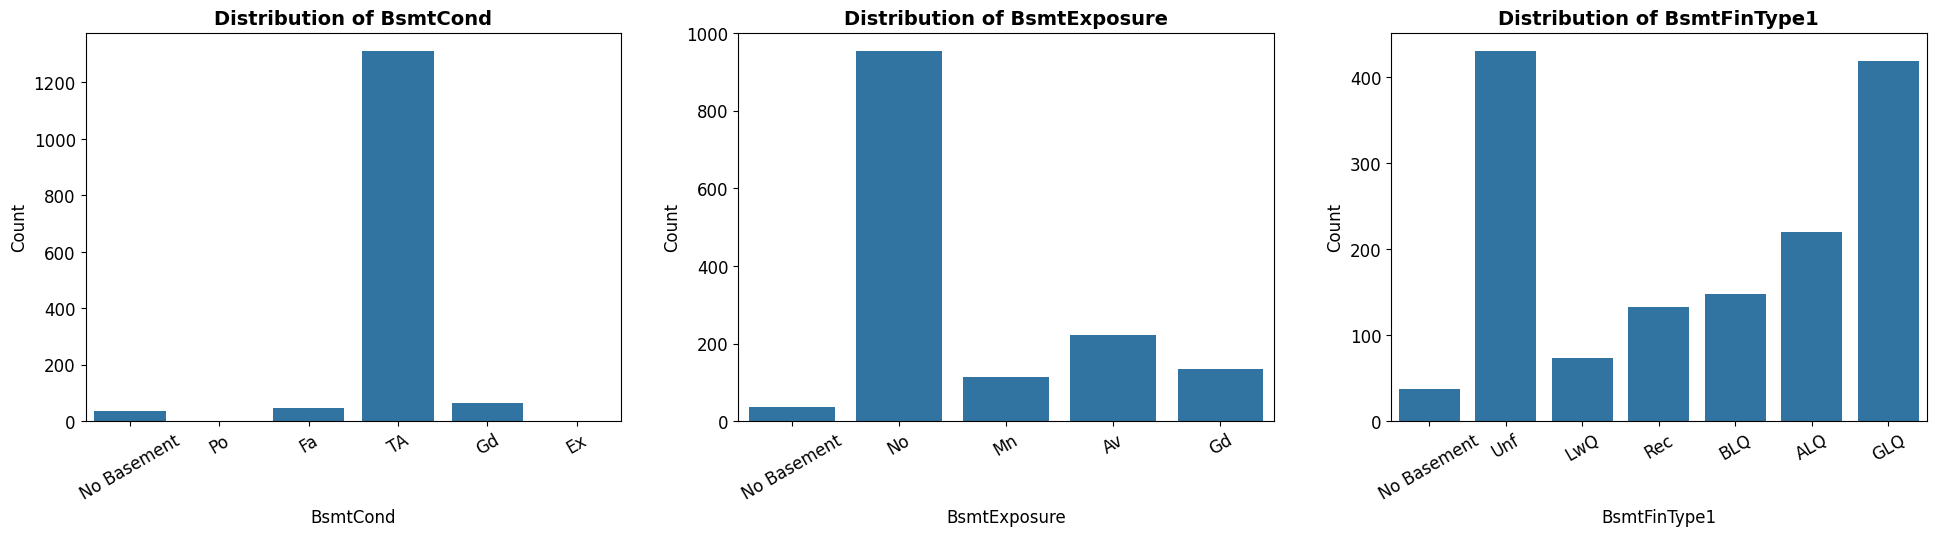

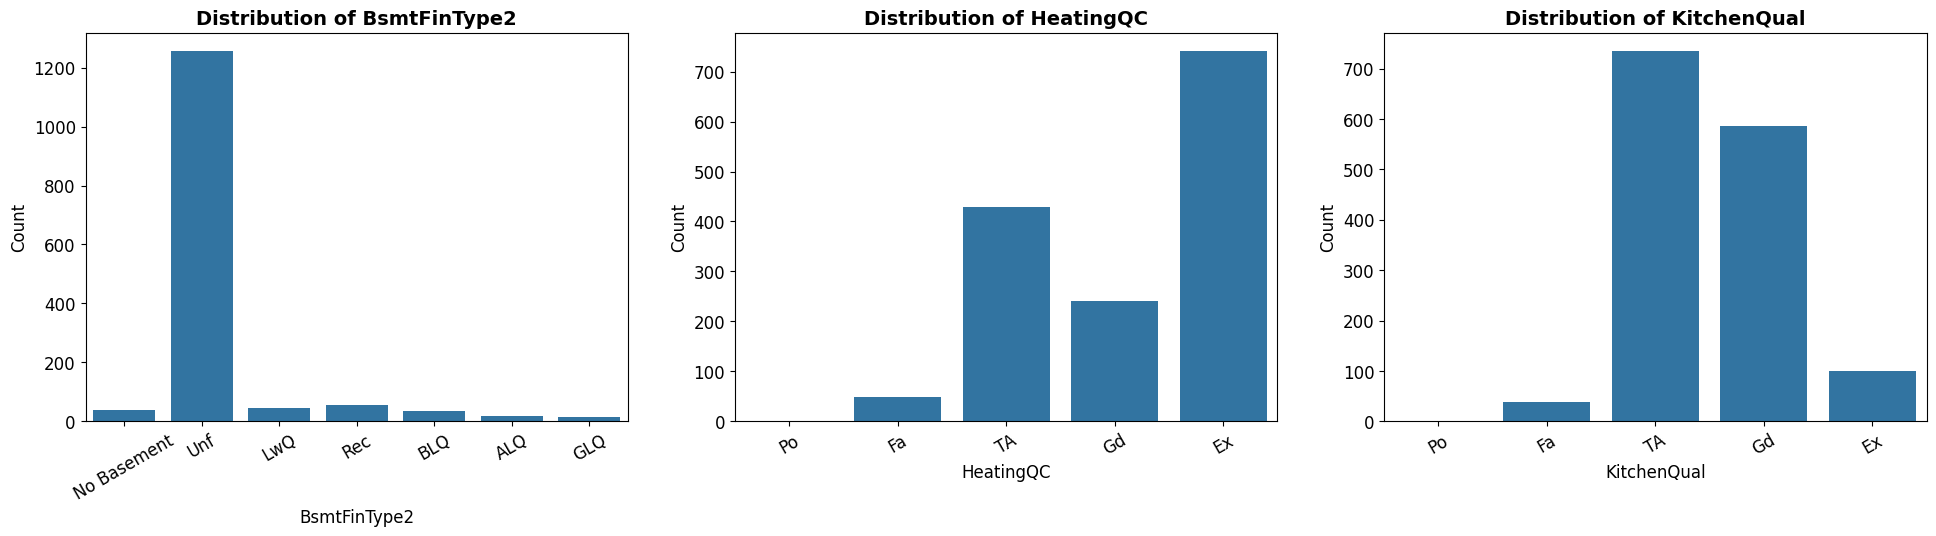

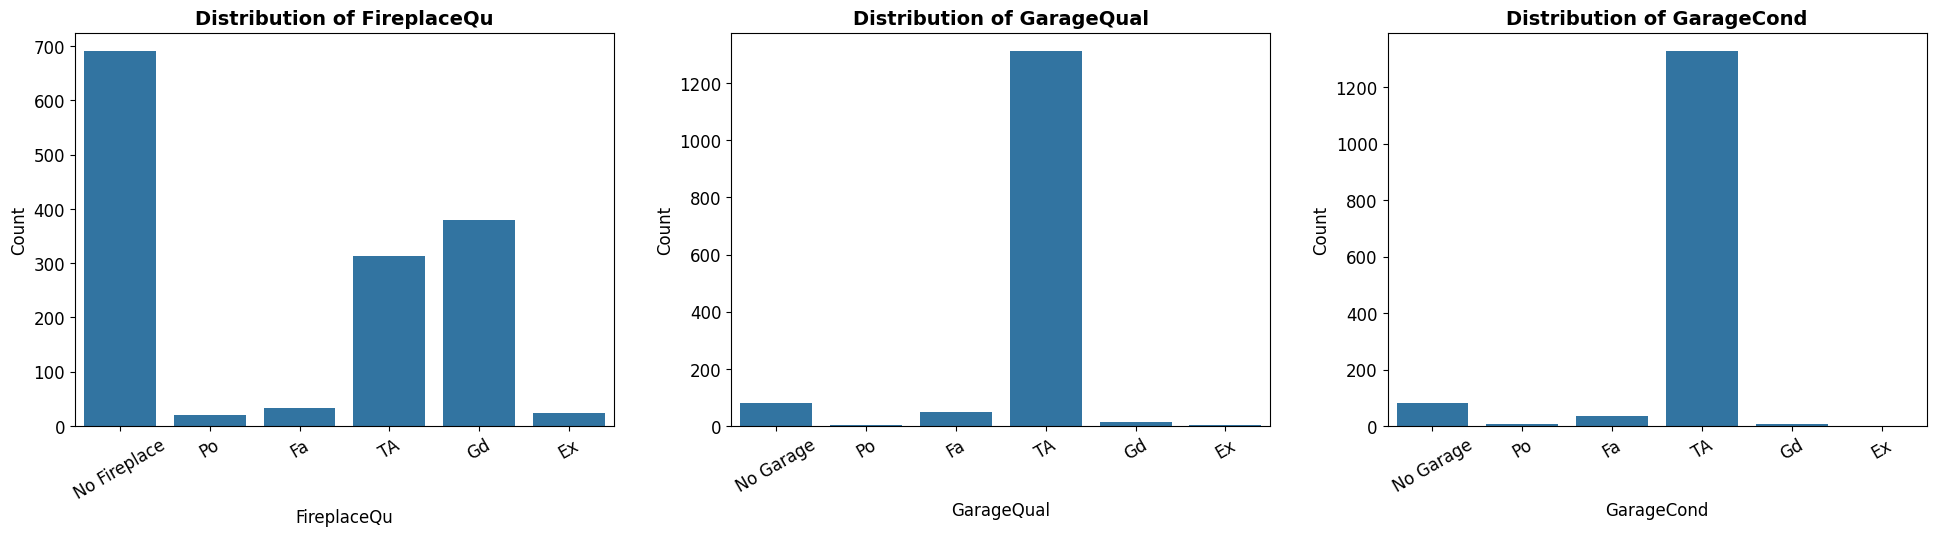

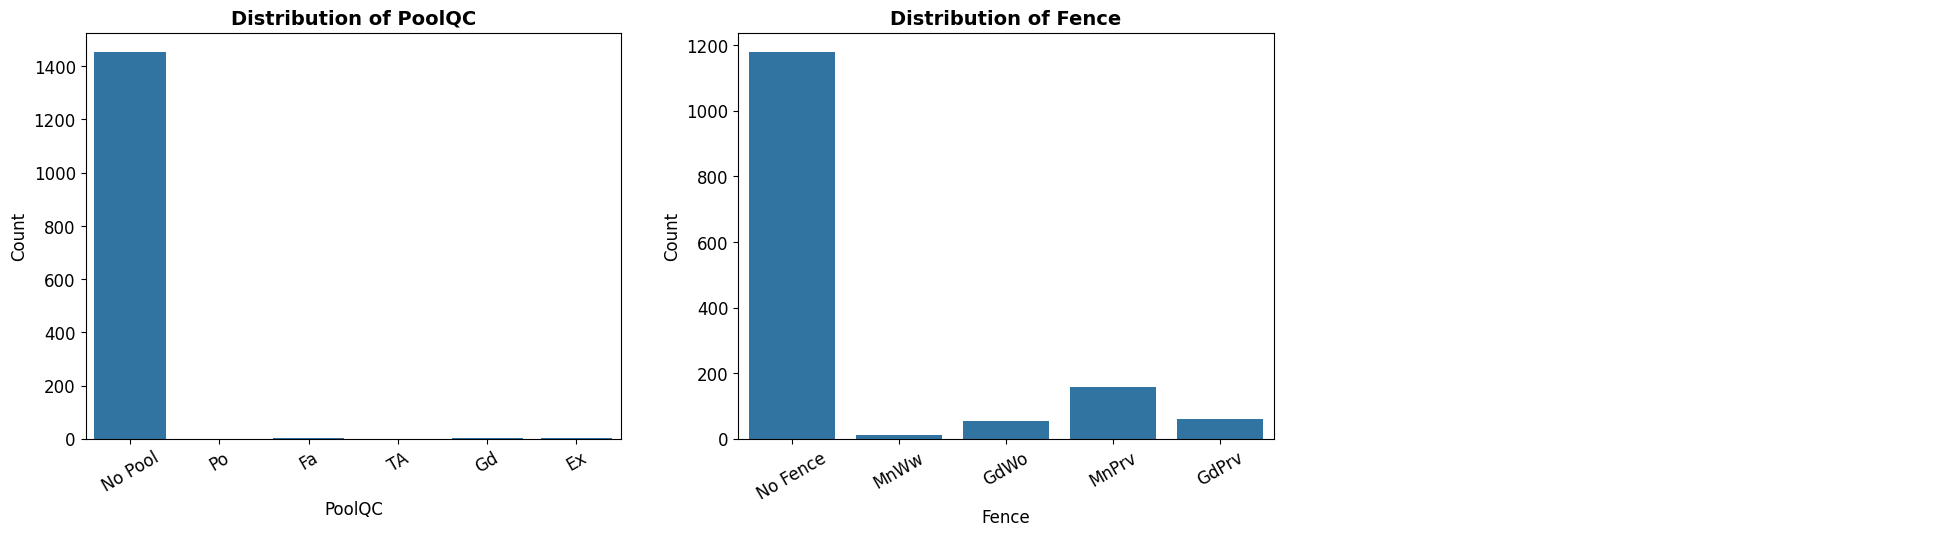

In [22]:
ncols = 3
nrows = 1

order_mapping = {
    "order": ["Po", "Fa", "TA", "Gd", "Ex"],
    "order_BsmtQual_Cond": ["No Basement", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_BsmtExposure": ["No Basement", "No", "Mn", "Av", "Gd"],
    "order_BsmtFinType": ["No Basement", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "order_Fireplace": ["No Fireplace", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Garage": ["No Garage", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Pool": ["No Pool", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Fence": ["No Fence", "MnWw", "GdWo", "MnPrv","GdPrv"]
}

for i in range(0, len(ordinal_cat_vars), ncols):
    chunk_vars = ordinal_cat_vars[i:i + ncols]
    
    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        if var in ("BsmtQual", "BsmtCond"):
            order = order_mapping.get("order_BsmtQual_Cond")
        elif var == "BsmtExposure":
            order = order_mapping.get("order_BsmtExposure")
        elif var in ("BsmtFinType1", "BsmtFinType2"):
            order = order_mapping.get("order_BsmtFinType")
        elif var == "FireplaceQu":
            order = order_mapping.get("order_Fireplace")
        elif var in ("GarageQual", "GarageCond"):
            order = order_mapping.get("order_Garage")
        elif var == "PoolQC":
            order = order_mapping.get("order_Pool")
        elif var == "Fence":
            order = order_mapping.get("order_Fence")
        else:
            order = order_mapping.get("order")
        sns.countplot(data=train, x=var, ax=axs[j], order=order)
        axs[j].set_title(f"Distribution of {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel(var, fontsize=12)
        axs[j].set_ylabel("Count", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

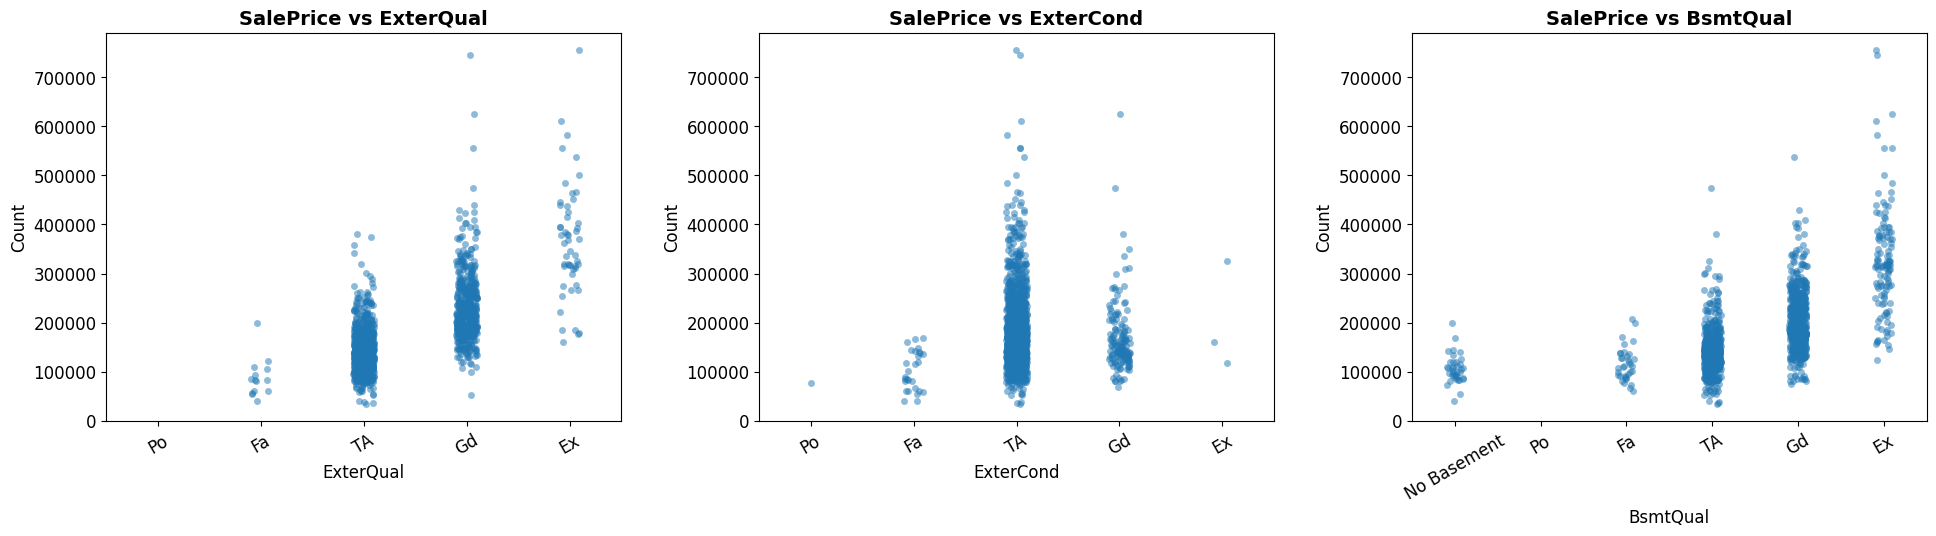

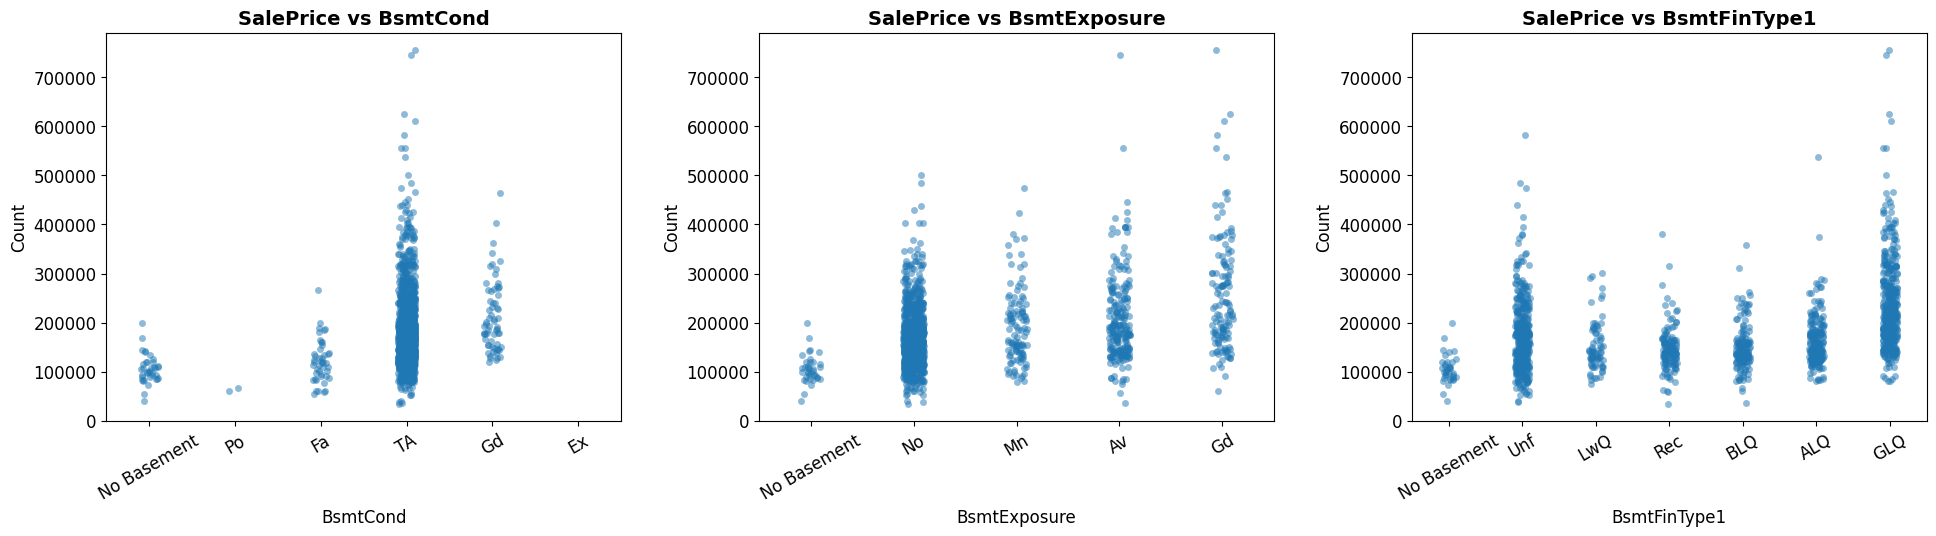

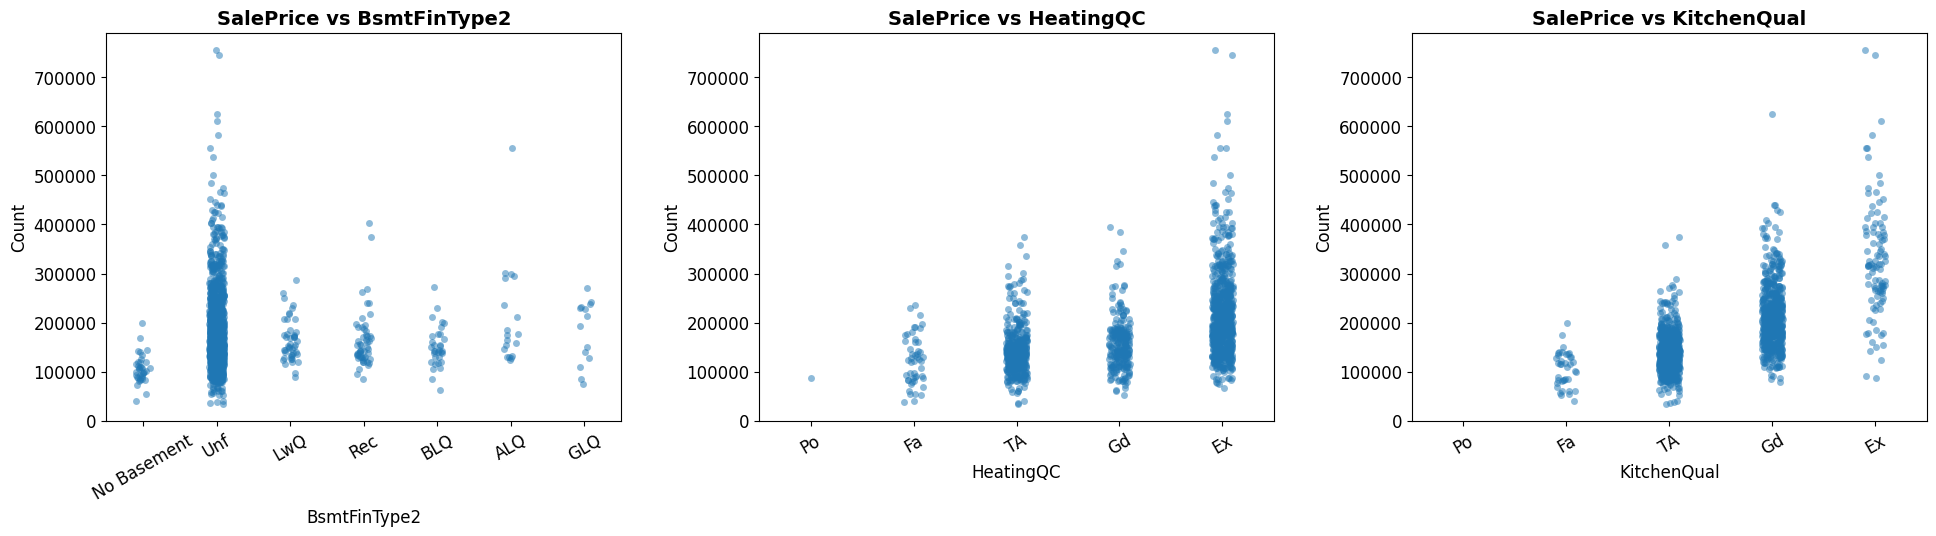

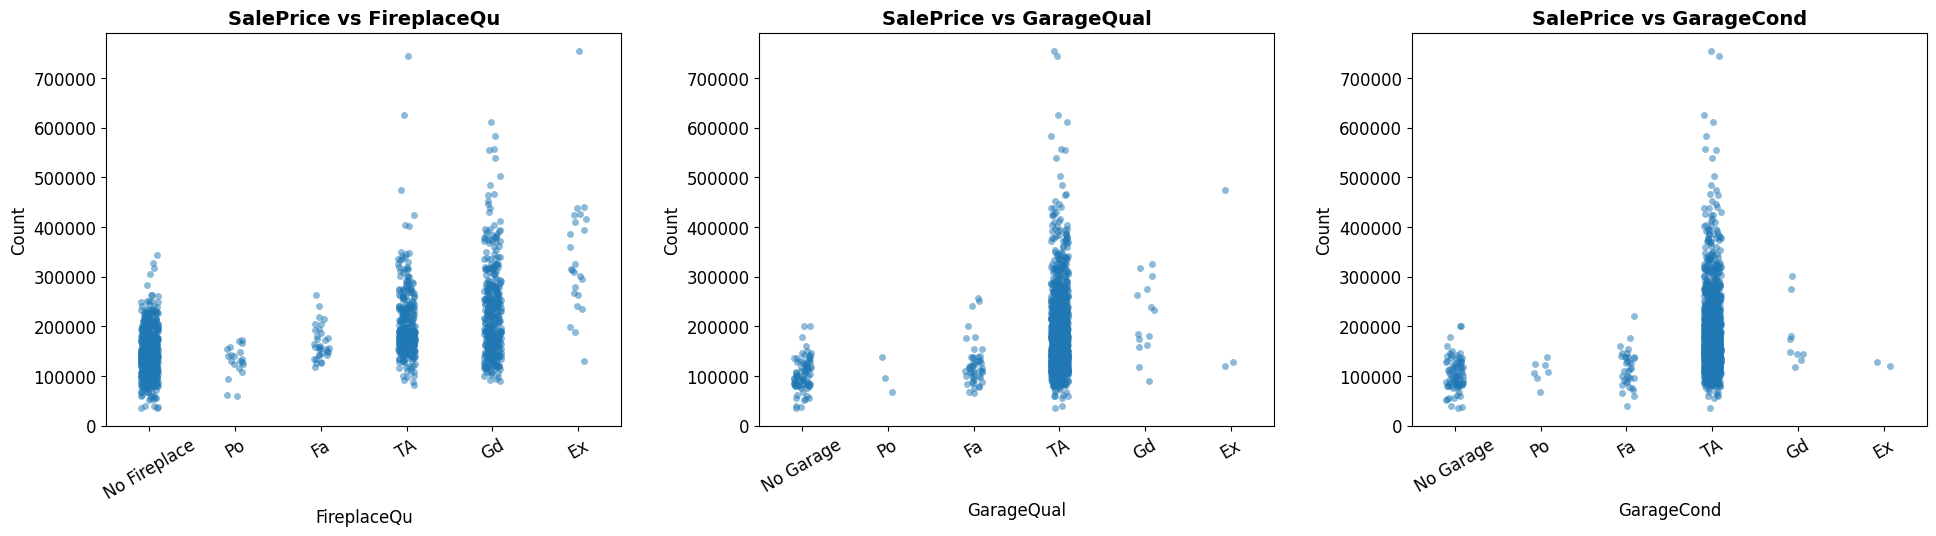

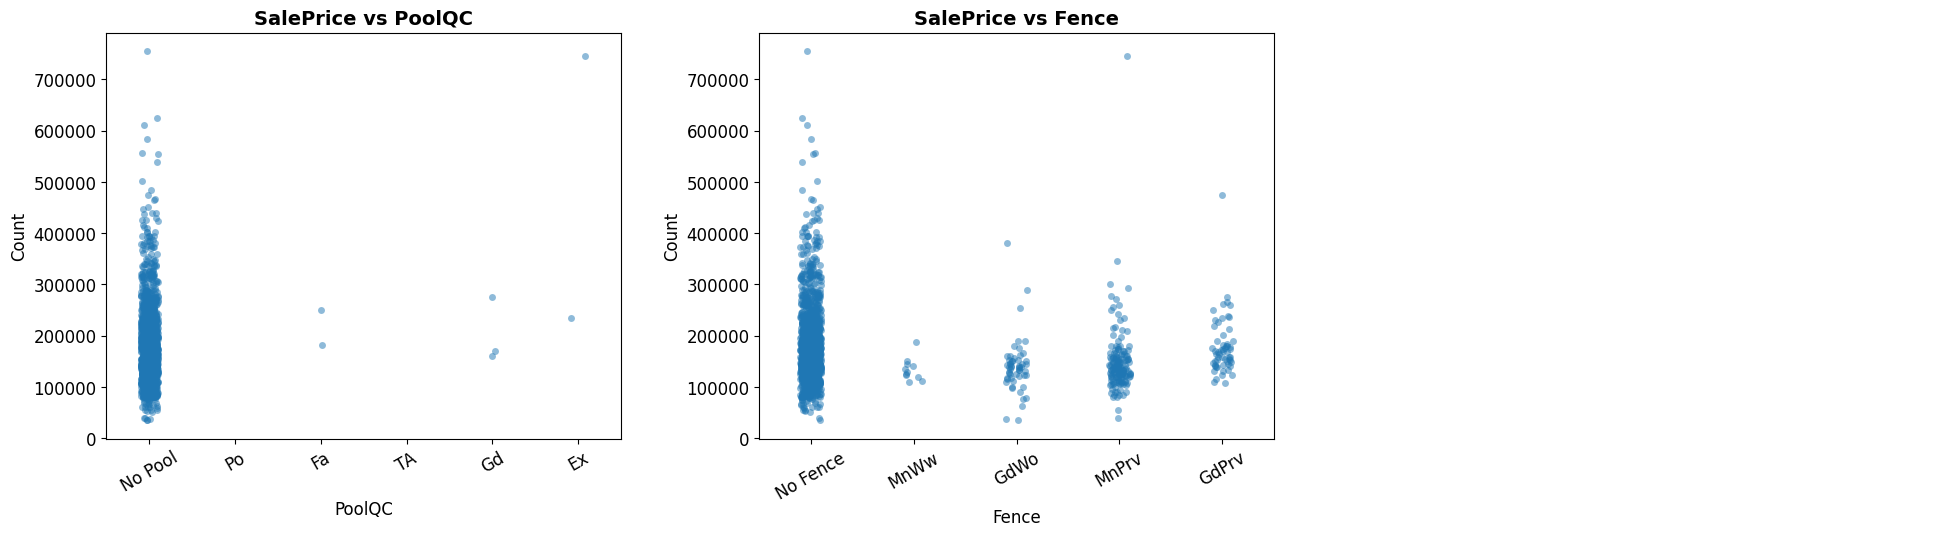

In [23]:
ncols = 3
nrows = 1

order_mapping = {
    "order": ["Po", "Fa", "TA", "Gd", "Ex"],
    "order_BsmtQual_Cond": ["No Basement", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_BsmtExposure": ["No Basement", "No", "Mn", "Av", "Gd"],
    "order_BsmtFinType": ["No Basement", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "order_Fireplace": ["No Fireplace", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Garage": ["No Garage", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Pool": ["No Pool", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Fence": ["No Fence", "MnWw", "GdWo", "MnPrv","GdPrv"]
}

for i in range(0, len(ordinal_cat_vars), ncols):
    chunk_vars = ordinal_cat_vars[i:i + ncols]
    
    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        if var in ("BsmtQual", "BsmtCond"):
            order = order_mapping.get("order_BsmtQual_Cond")
        elif var == "BsmtExposure":
            order = order_mapping.get("order_BsmtExposure")
        elif var in ("BsmtFinType1", "BsmtFinType2"):
            order = order_mapping.get("order_BsmtFinType")
        elif var == "FireplaceQu":
            order = order_mapping.get("order_Fireplace")
        elif var in ("GarageQual", "GarageCond"):
            order = order_mapping.get("order_Garage")
        elif var == "PoolQC":
            order = order_mapping.get("order_Pool")
        elif var == "Fence":
            order = order_mapping.get("order_Fence")
        else:
            order = order_mapping.get("order")
        sns.stripplot(data=train, x=var, y="SalePrice", alpha=0.5, ax=axs[j], order=order)
        axs[j].set_title(f"SalePrice vs {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel(var, fontsize=12)
        axs[j].set_ylabel("Count", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

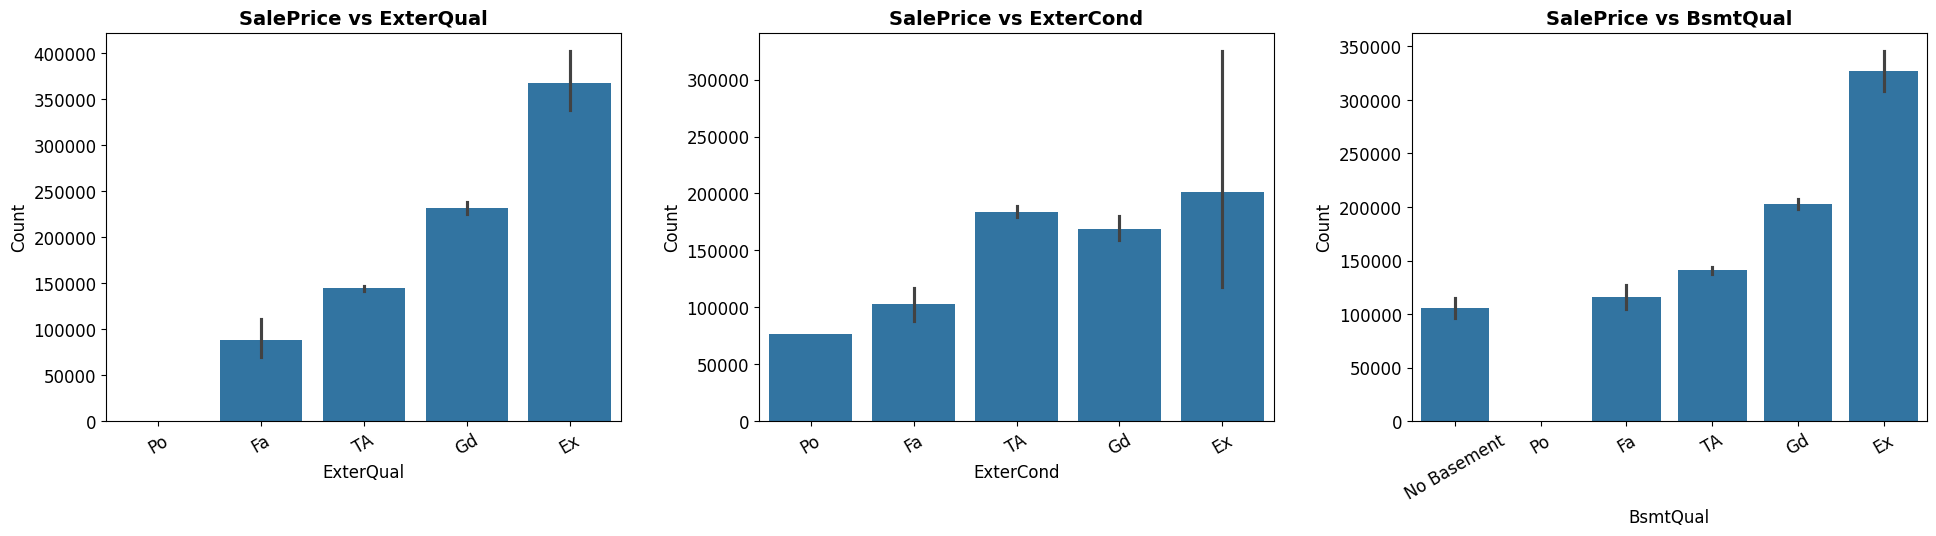

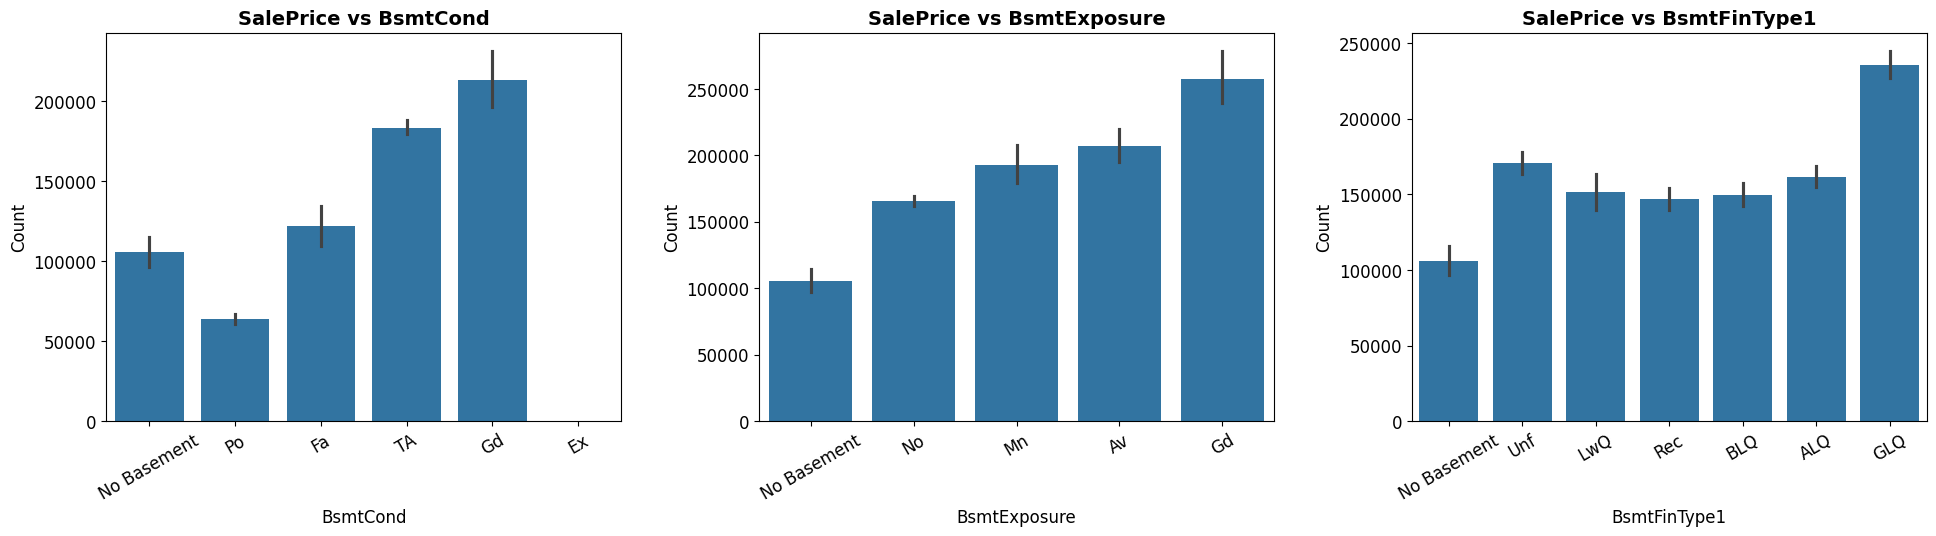

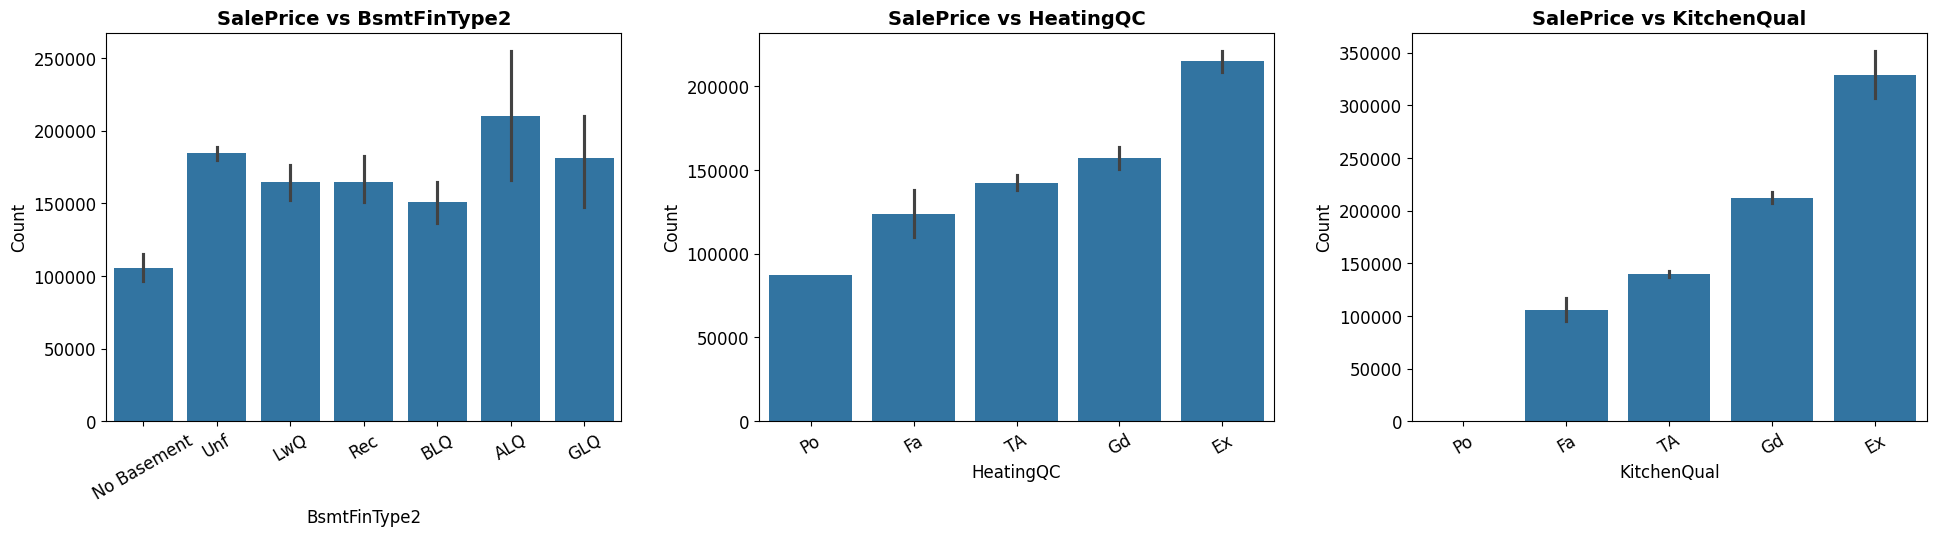

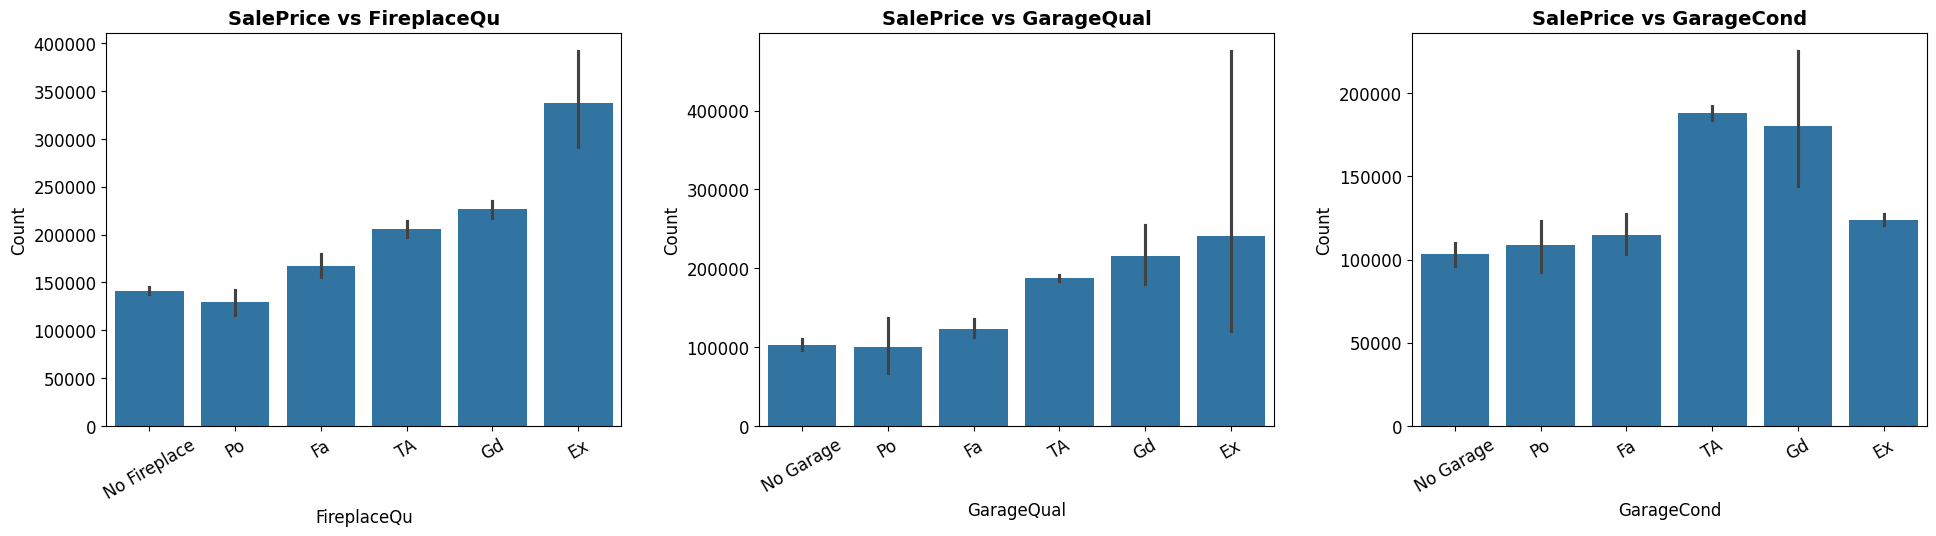

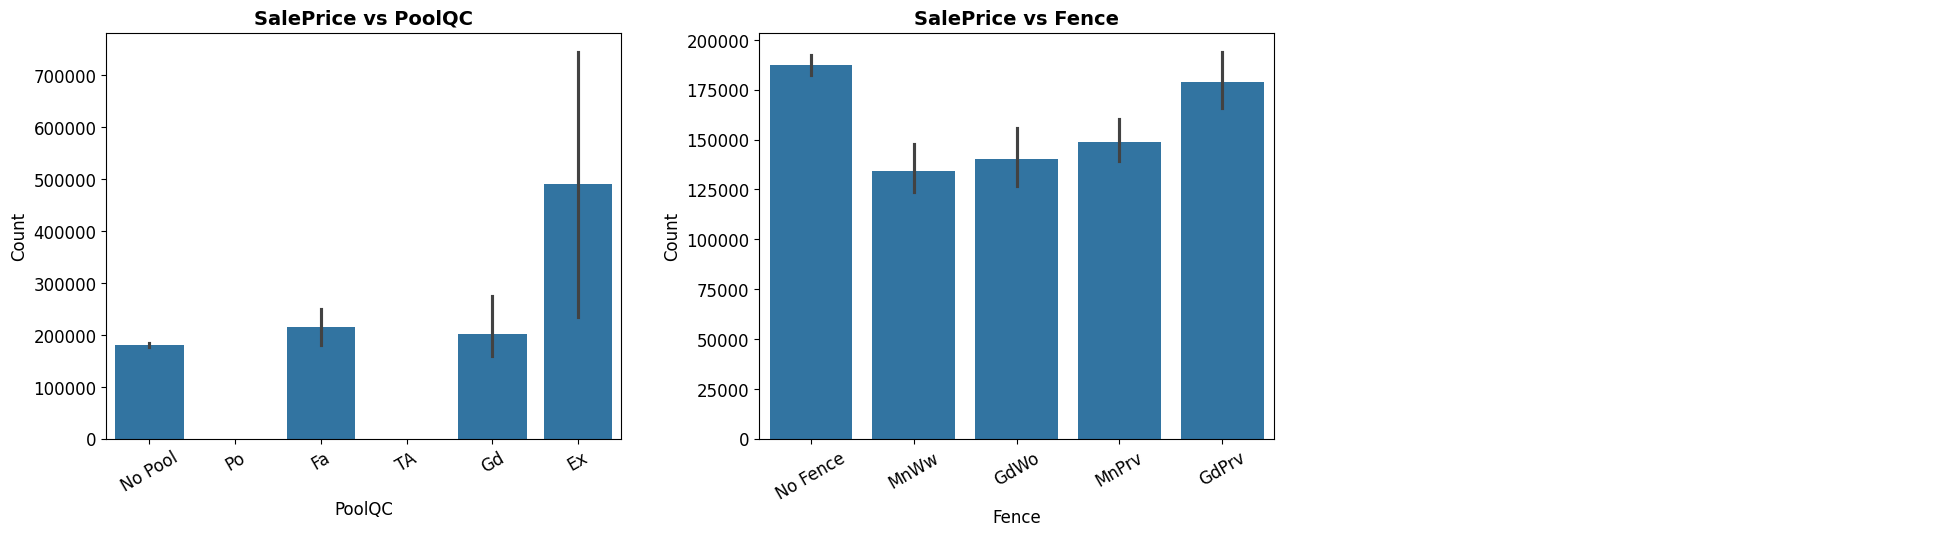

In [24]:
ncols = 3
nrows = 1

order_mapping = {
    "order": ["Po", "Fa", "TA", "Gd", "Ex"],
    "order_BsmtQual_Cond": ["No Basement", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_BsmtExposure": ["No Basement", "No", "Mn", "Av", "Gd"],
    "order_BsmtFinType": ["No Basement", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "order_Fireplace": ["No Fireplace", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Garage": ["No Garage", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Pool": ["No Pool", "Po", "Fa", "TA", "Gd", "Ex"],
    "order_Fence": ["No Fence", "MnWw", "GdWo", "MnPrv","GdPrv"]
}

for i in range(0, len(ordinal_cat_vars), ncols):
    chunk_vars = ordinal_cat_vars[i:i + ncols]
    
    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        if var in ("BsmtQual", "BsmtCond"):
            order = order_mapping.get("order_BsmtQual_Cond")
        elif var == "BsmtExposure":
            order = order_mapping.get("order_BsmtExposure")
        elif var in ("BsmtFinType1", "BsmtFinType2"):
            order = order_mapping.get("order_BsmtFinType")
        elif var == "FireplaceQu":
            order = order_mapping.get("order_Fireplace")
        elif var in ("GarageQual", "GarageCond"):
            order = order_mapping.get("order_Garage")
        elif var == "PoolQC":
            order = order_mapping.get("order_Pool")
        elif var == "Fence":
            order = order_mapping.get("order_Fence")
        else:
            order = order_mapping.get("order")
        sns.barplot(data=train, x=var, y="SalePrice", ax=axs[j], order=order)
        axs[j].set_title(f"SalePrice vs {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel(var, fontsize=12)
        axs[j].set_ylabel("Count", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

We can see very skewed distributions

### Nominal Features

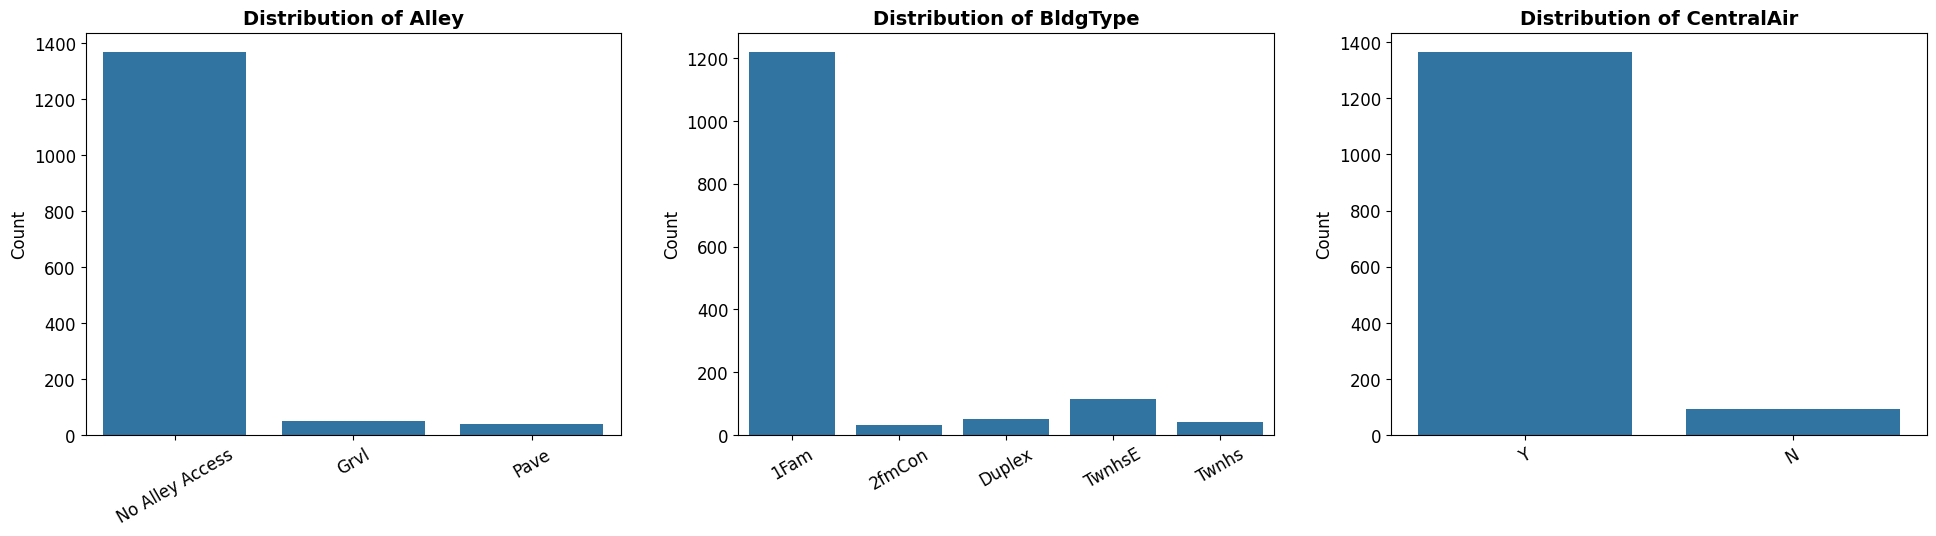

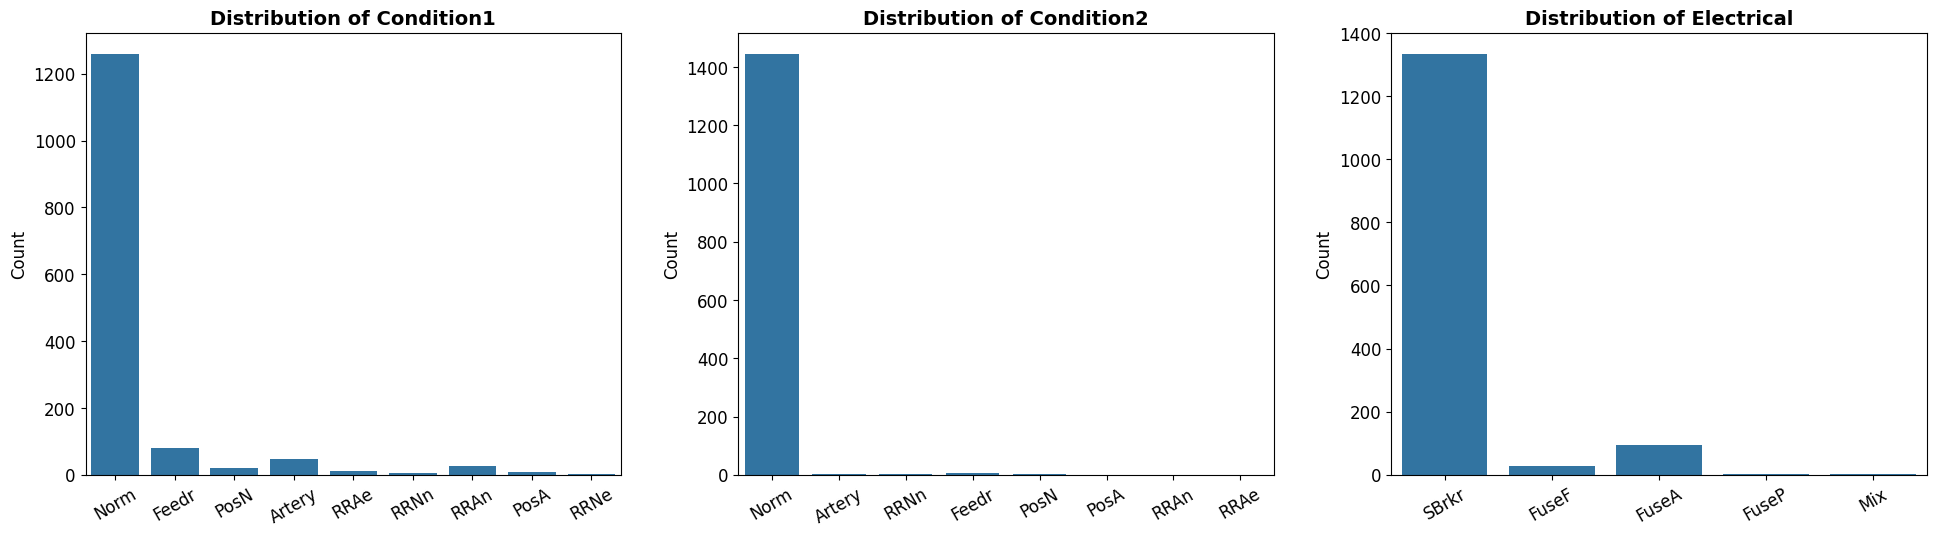

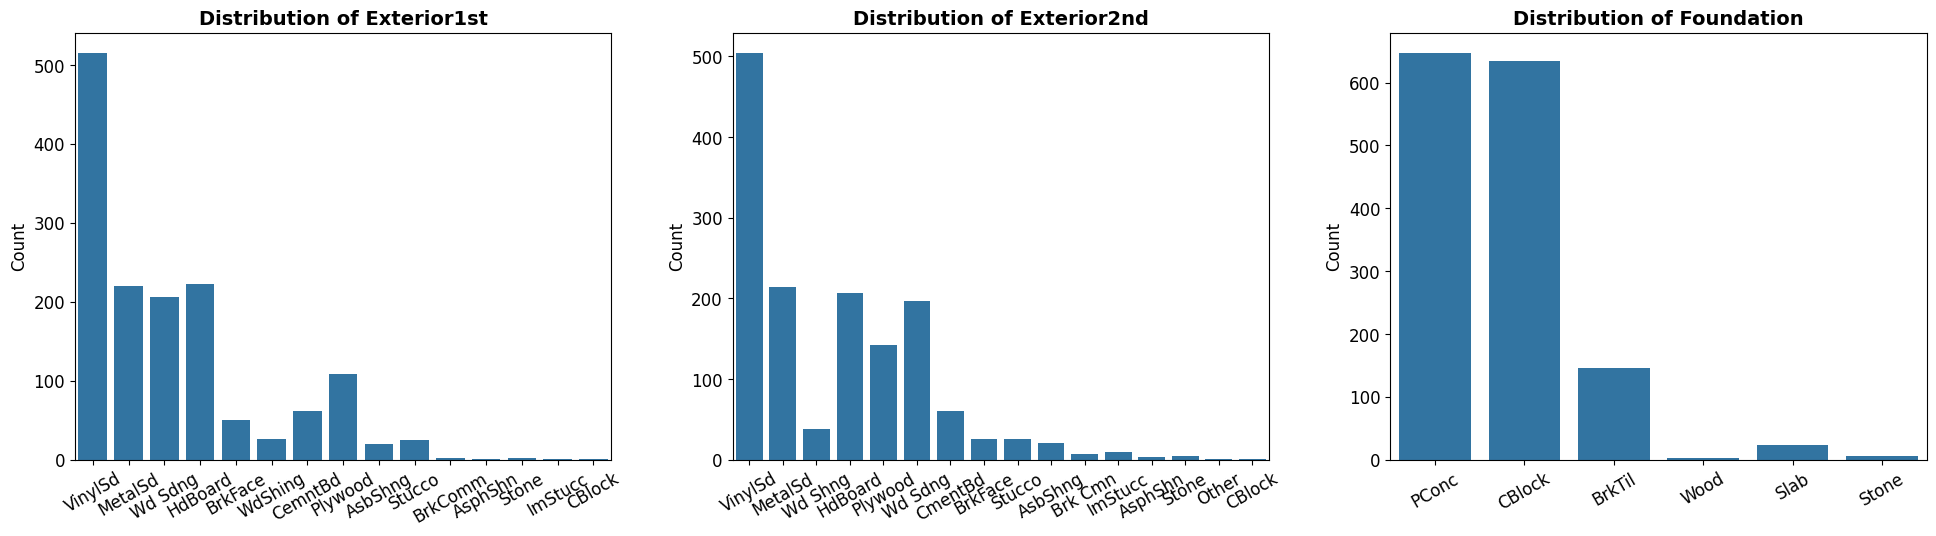

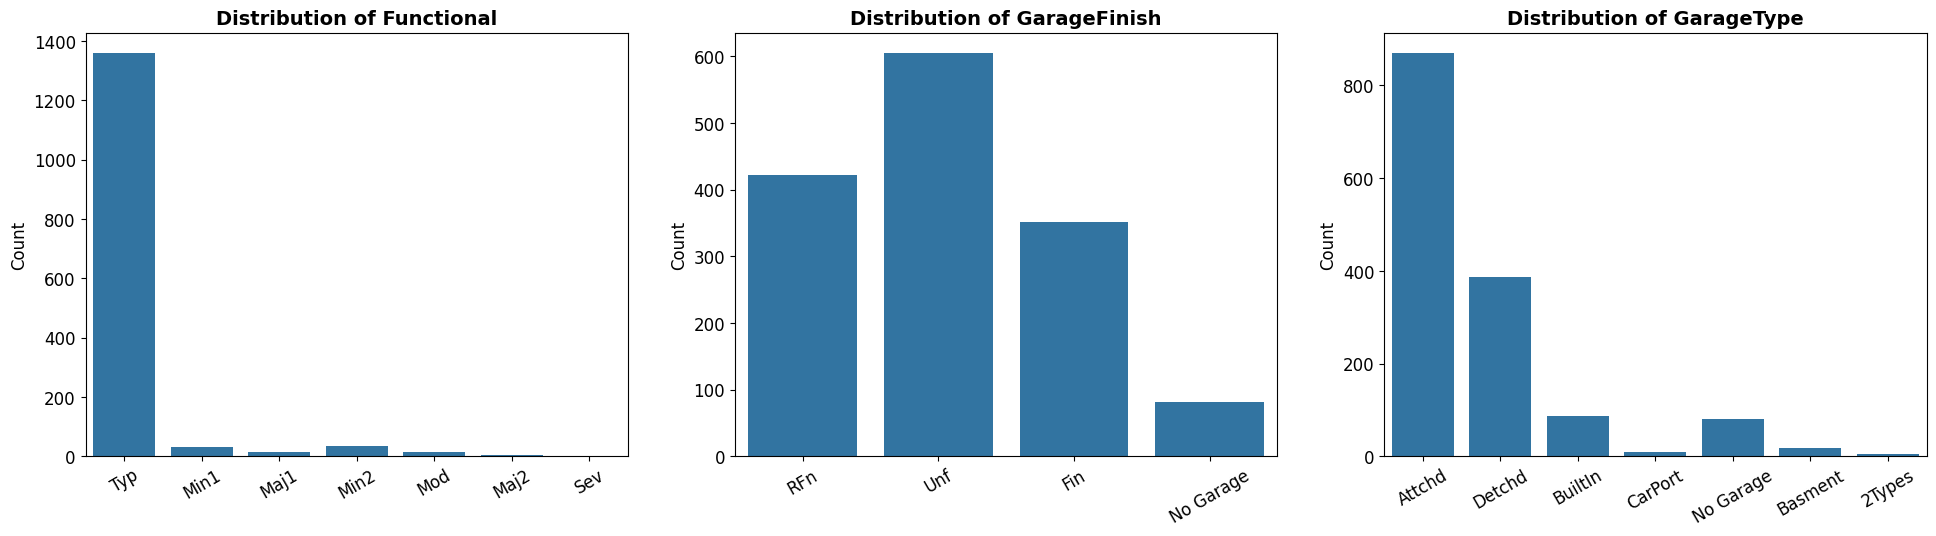

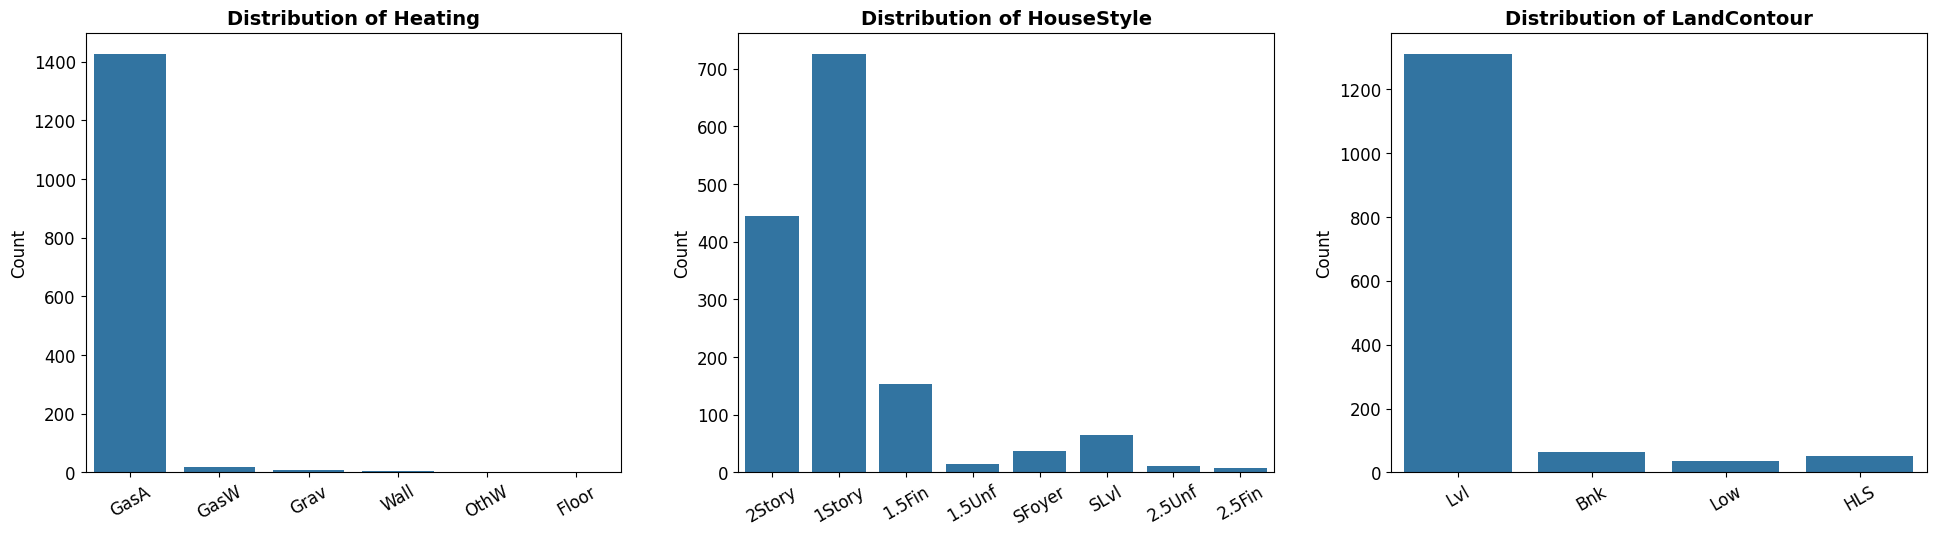

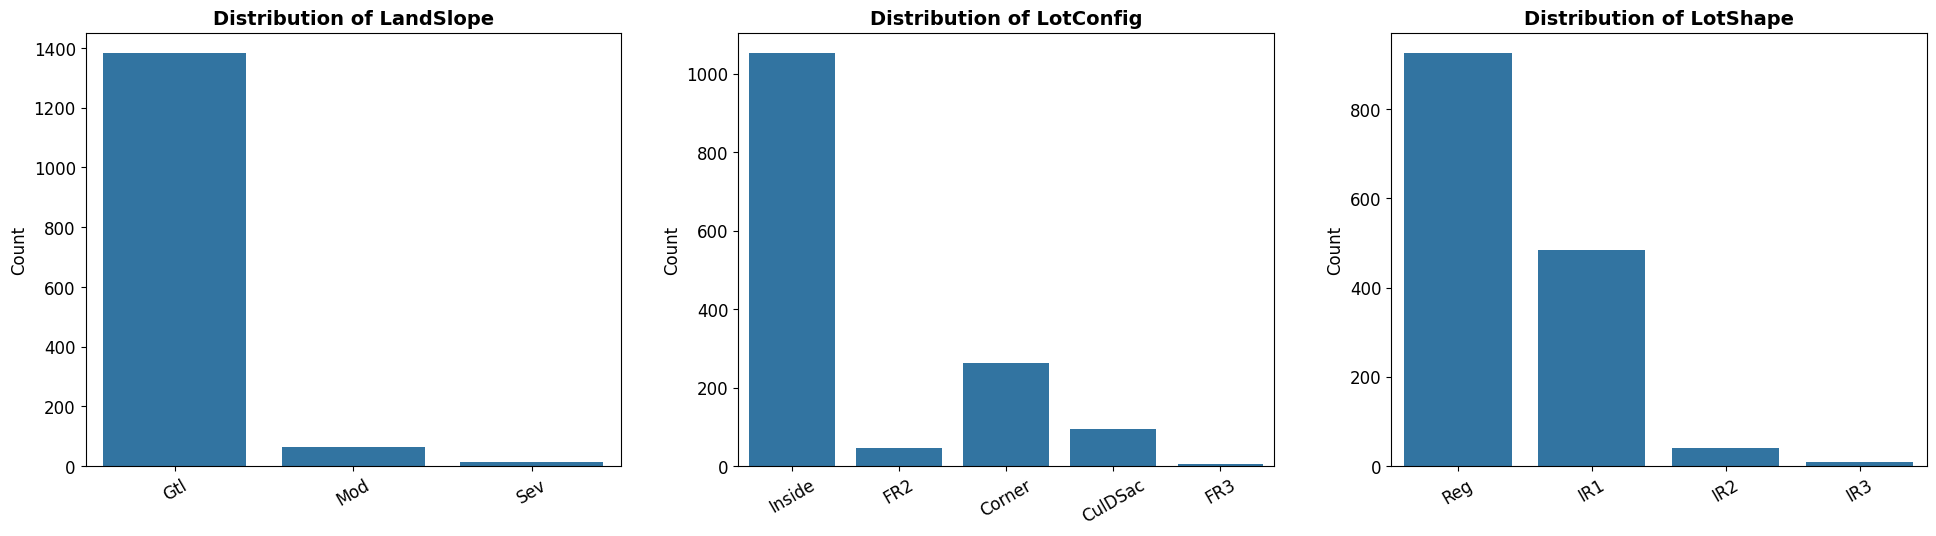

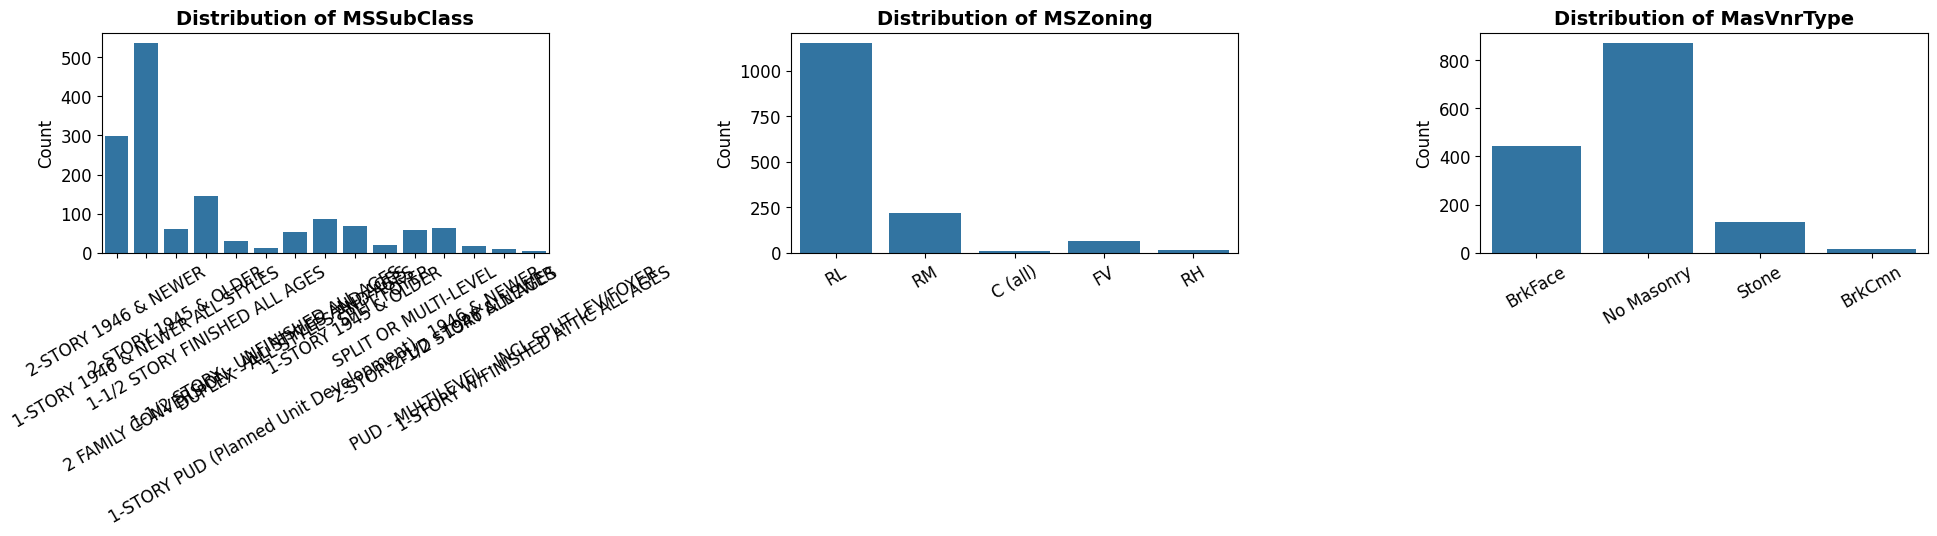

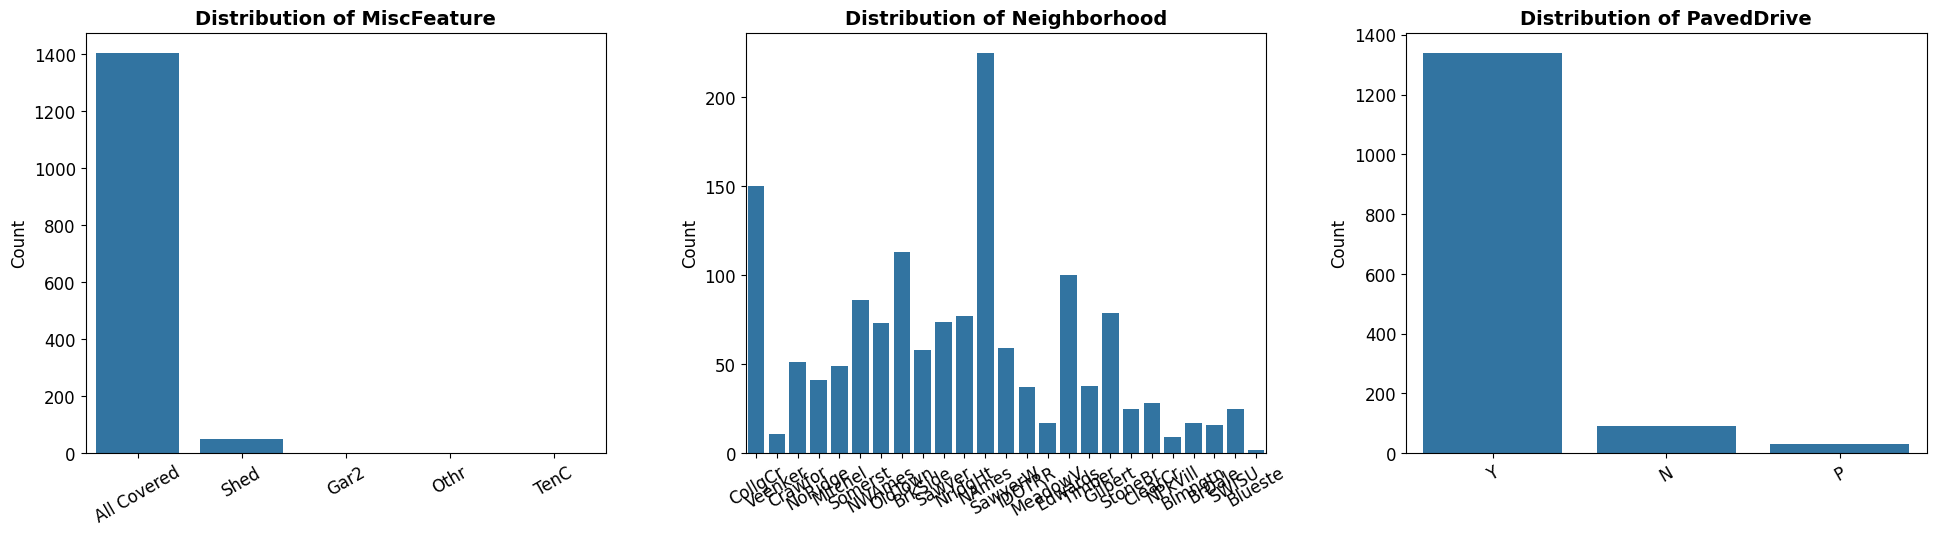

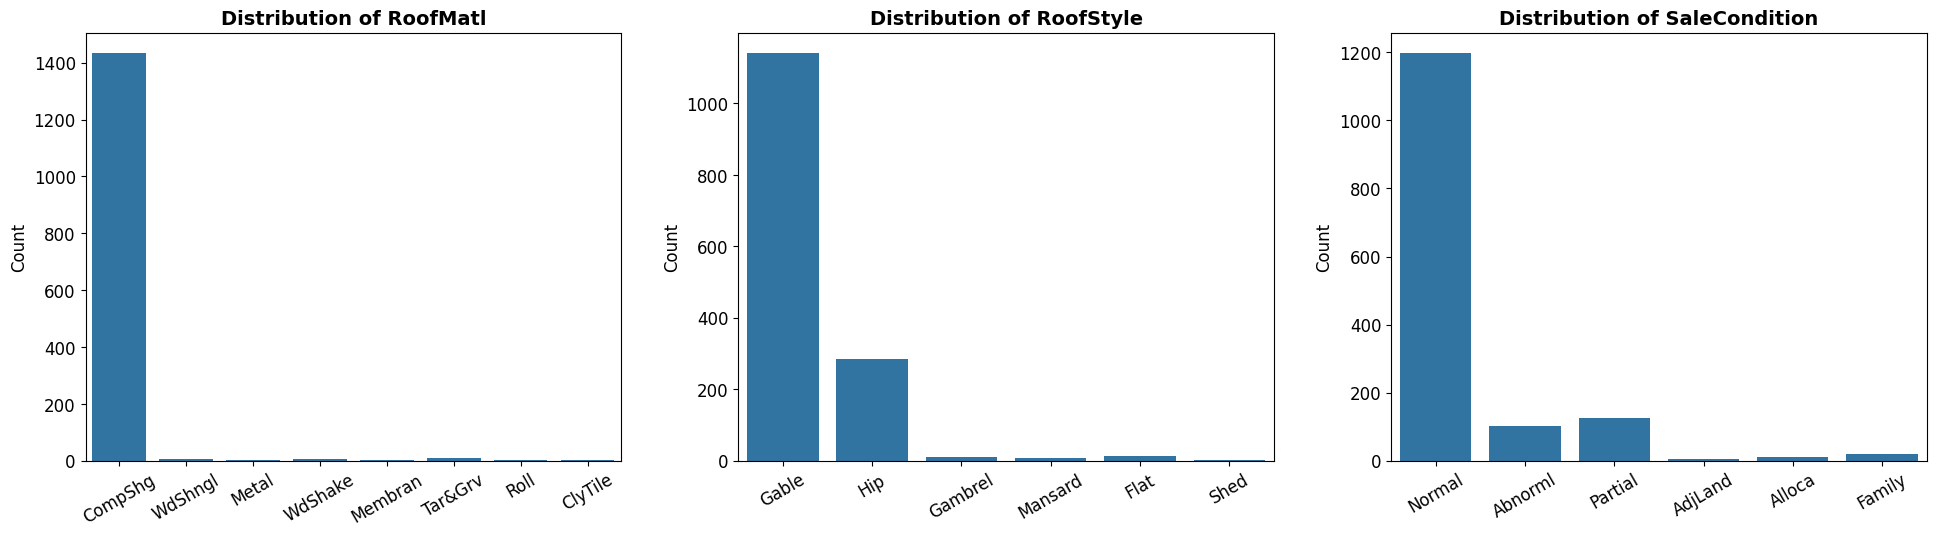

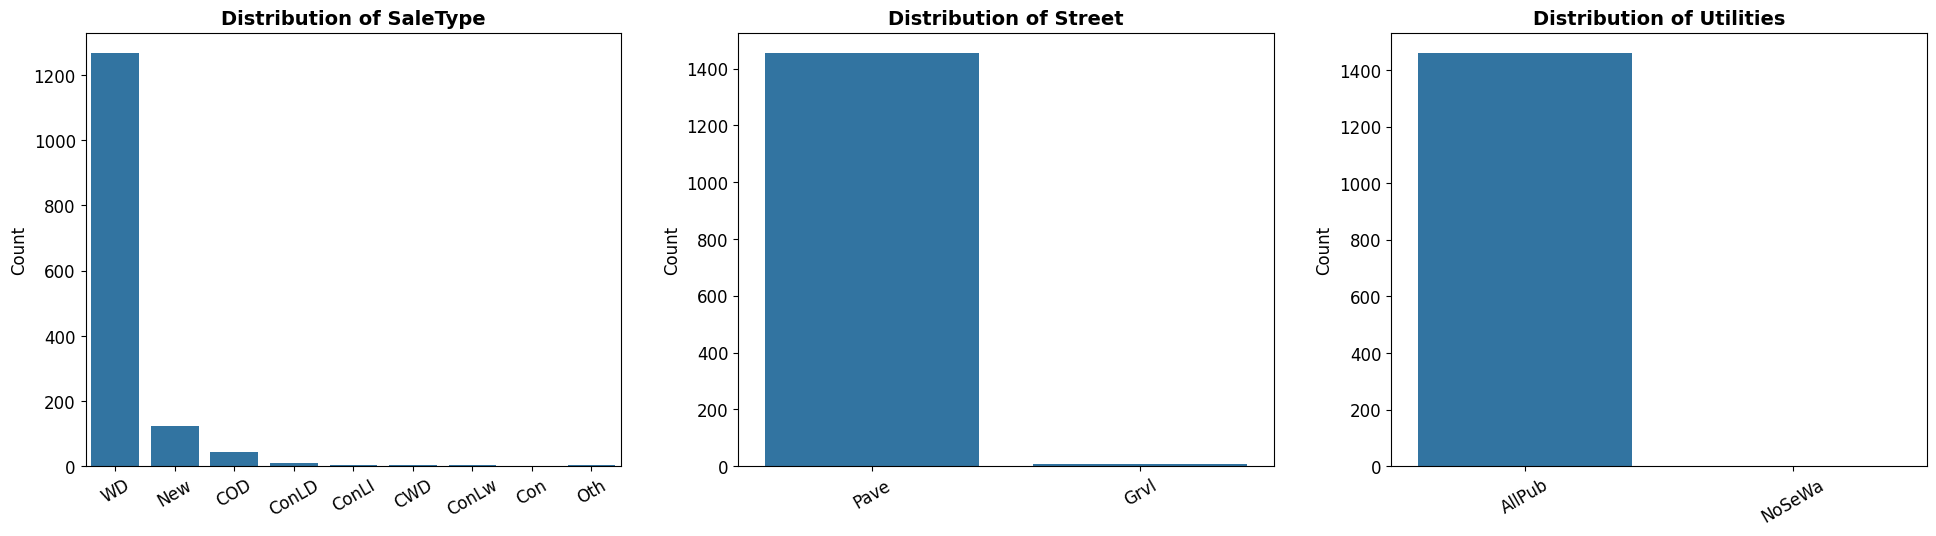

In [25]:
ncols = 3
nrows = 1

for i in range(0, len(nominal_cat_vars), ncols):
    chunk_vars = nominal_cat_vars[i:i + ncols]

    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        sns.countplot(data=train, x=var, ax=axs[j])
        axs[j].set_title(f"Distribution of {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel("")
        axs[j].set_ylabel("SalePrice", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

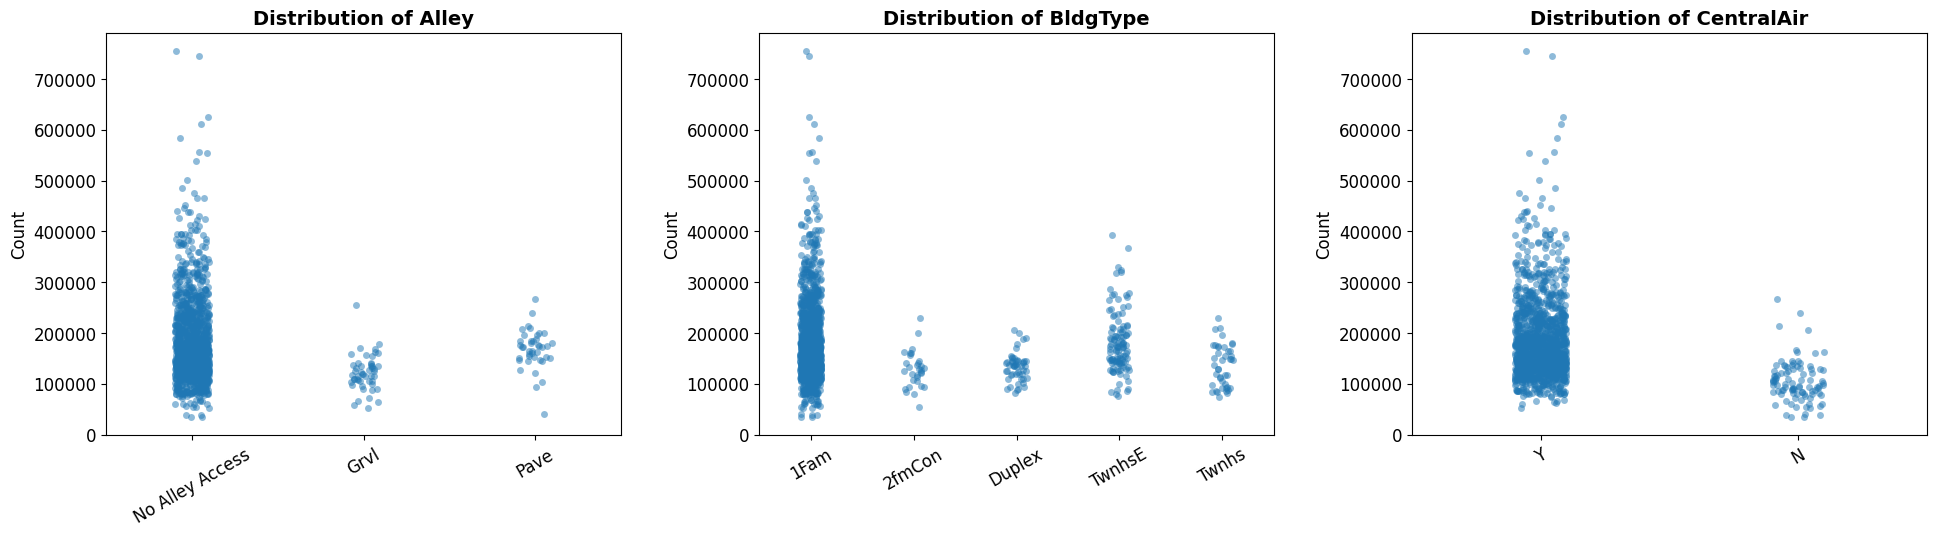

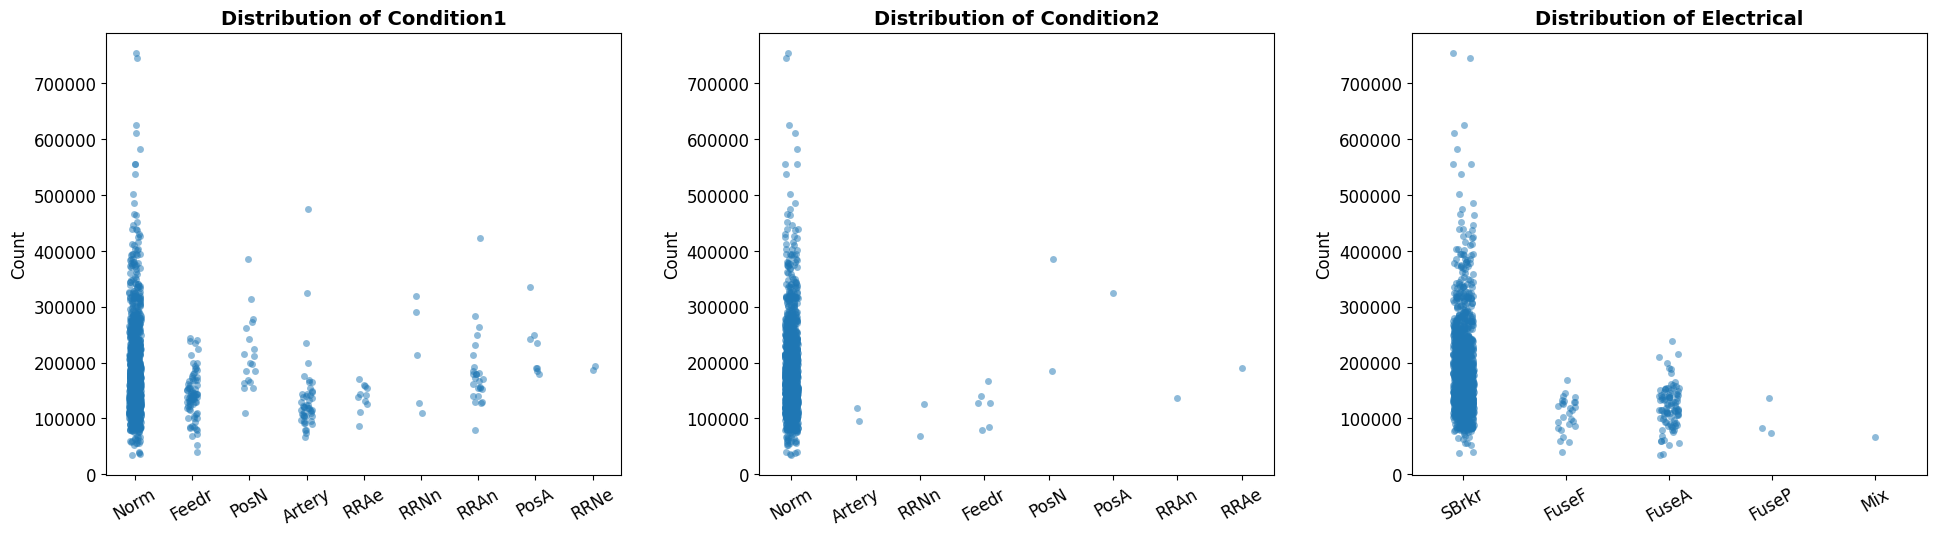

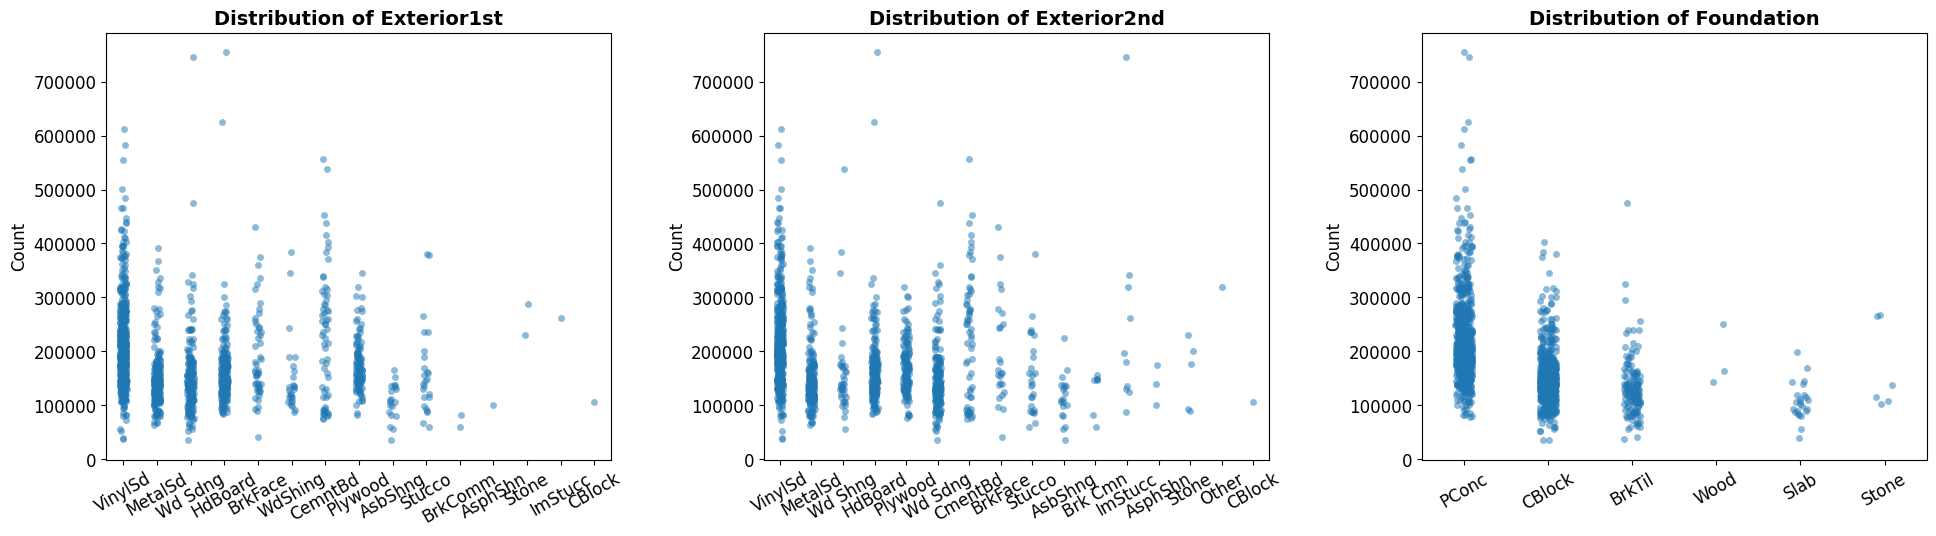

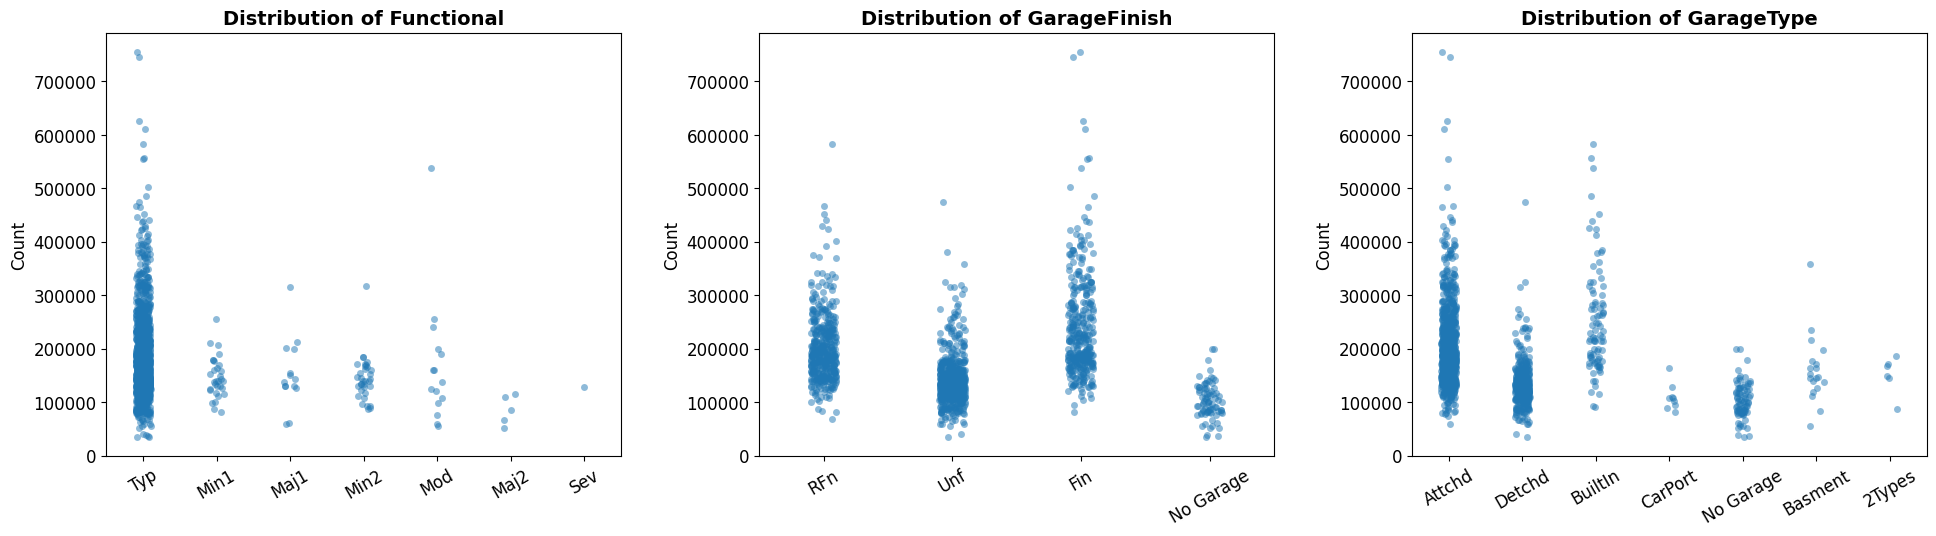

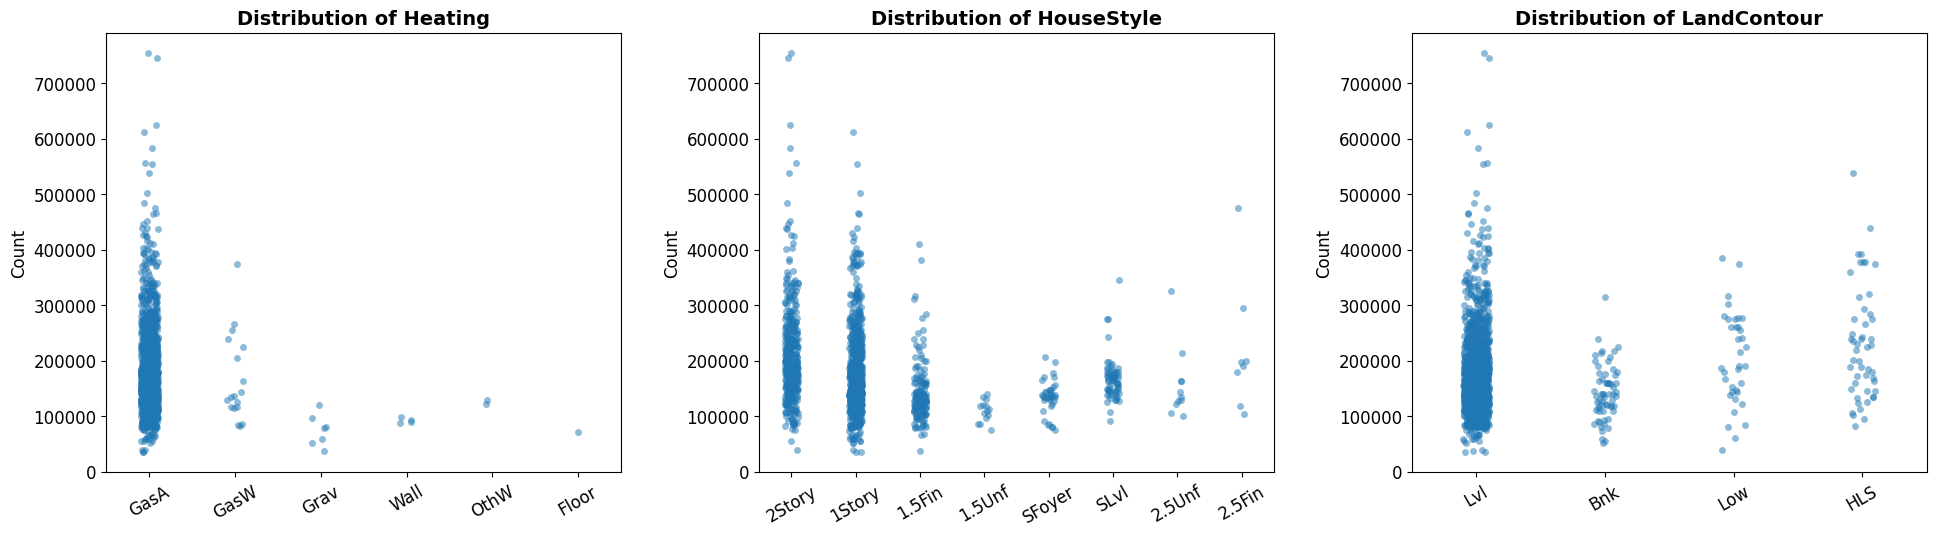

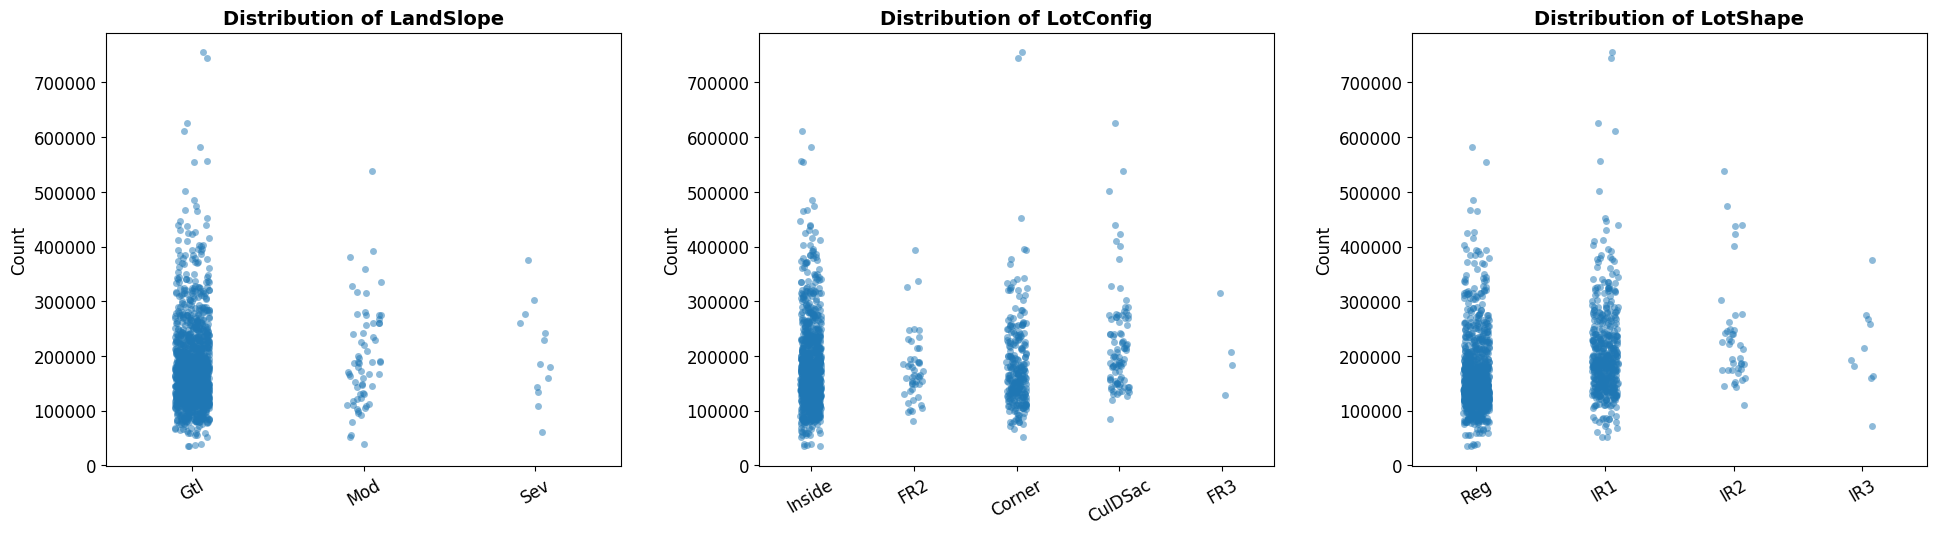

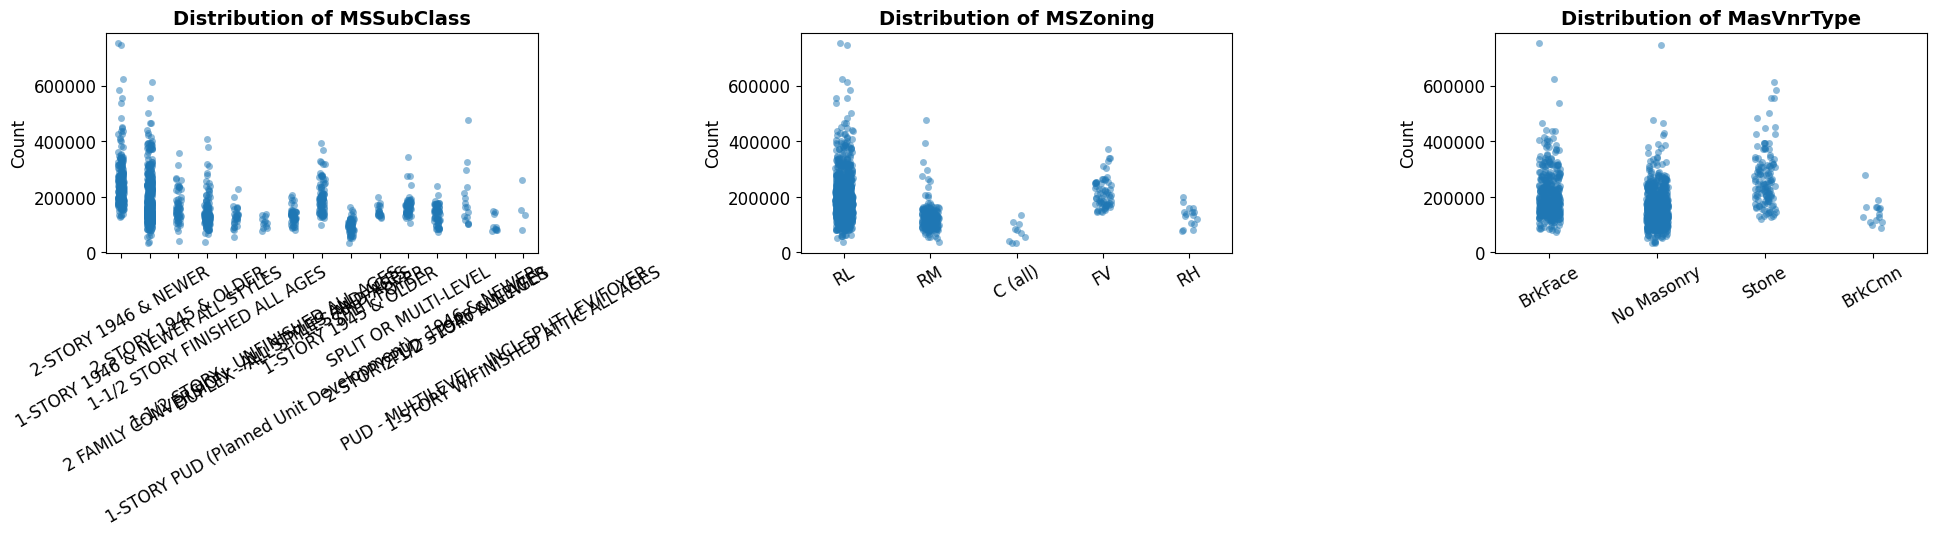

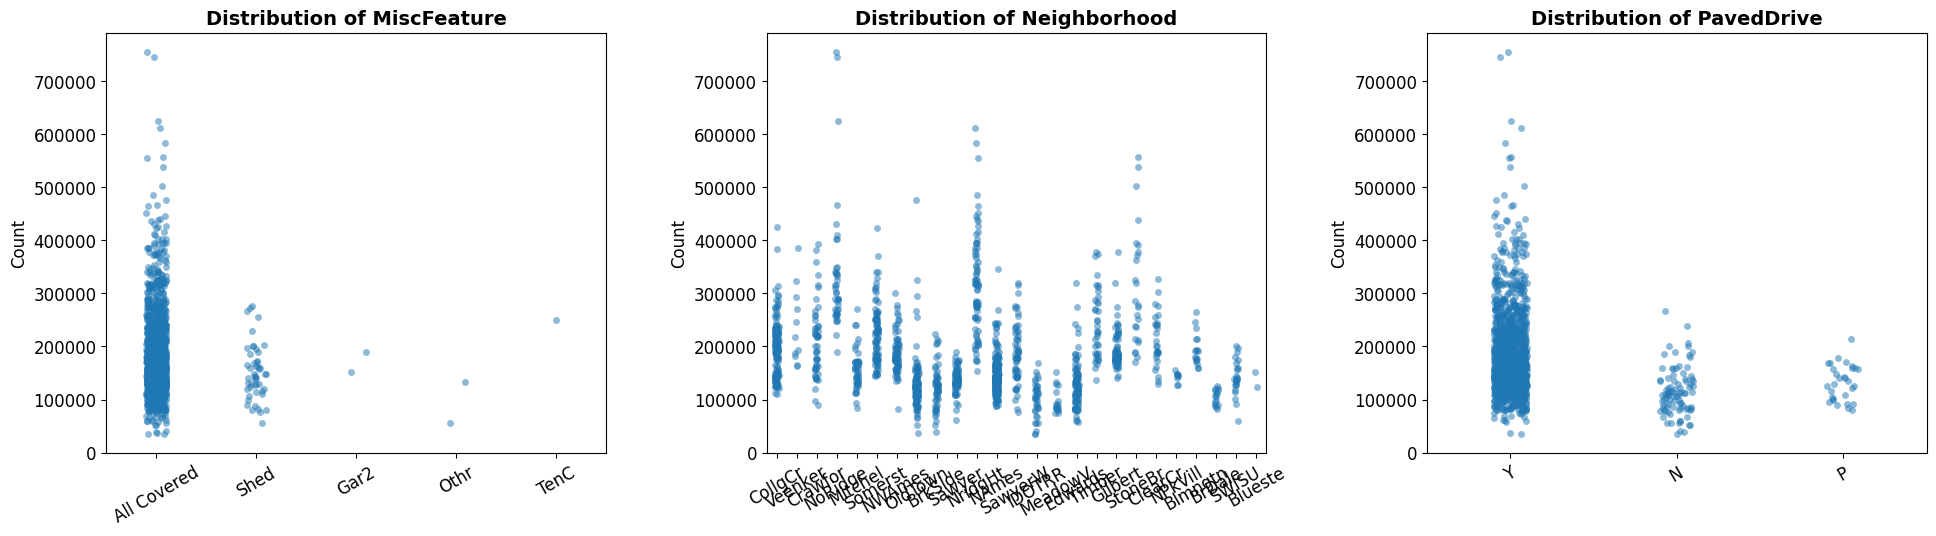

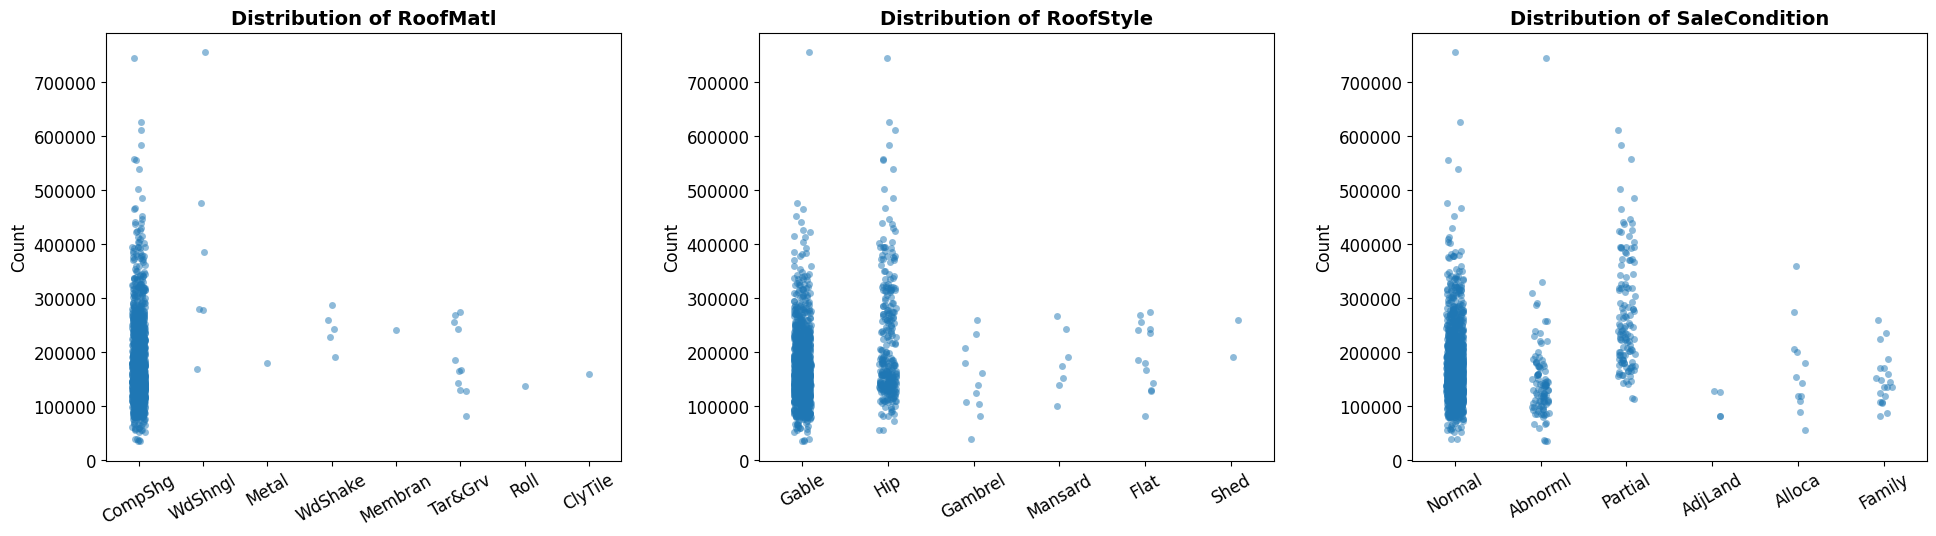

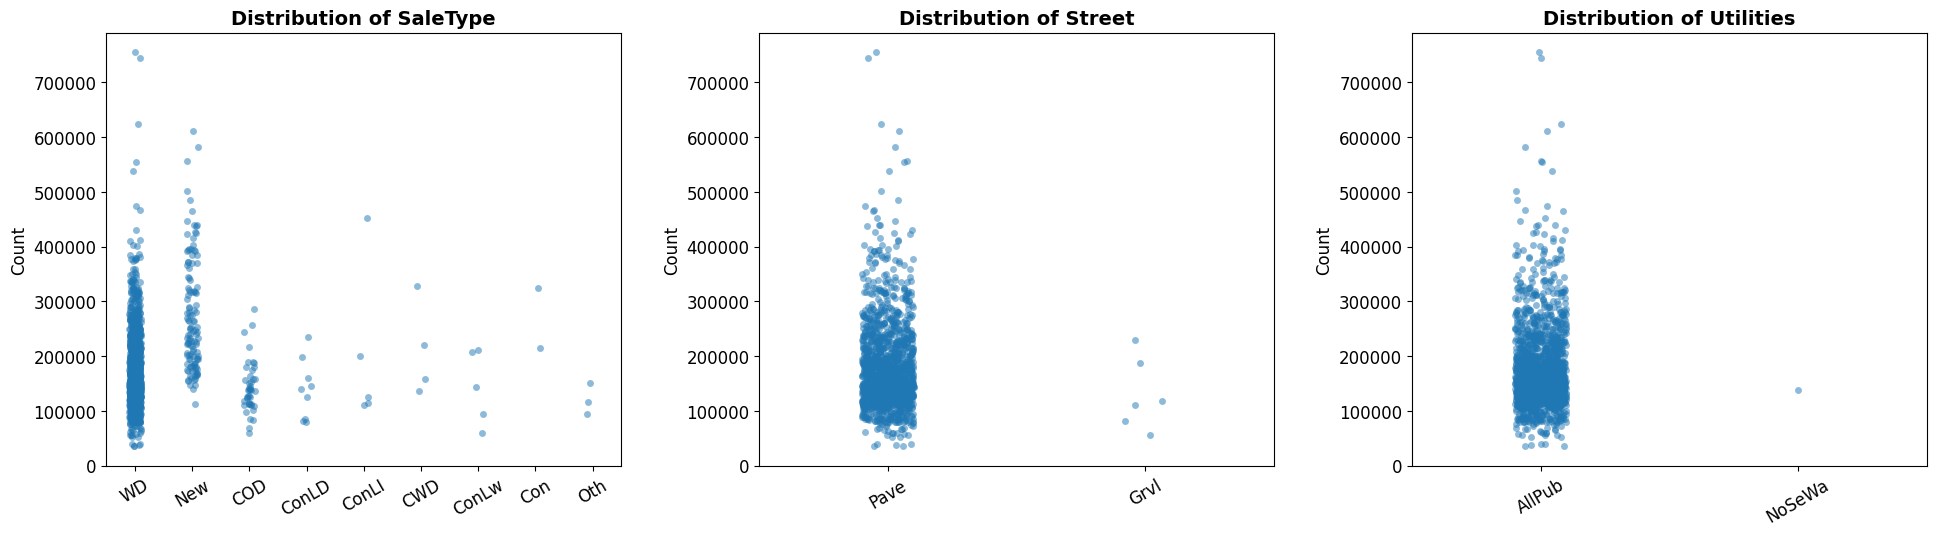

In [26]:
ncols = 3
nrows = 1

for i in range(0, len(nominal_cat_vars), ncols):
    chunk_vars = nominal_cat_vars[i:i + ncols]

    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        sns.stripplot(data=train, x=var, y="SalePrice", alpha=0.5, ax=axs[j])
        axs[j].set_title(f"Distribution of {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel("")
        axs[j].set_ylabel("SalePrice", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

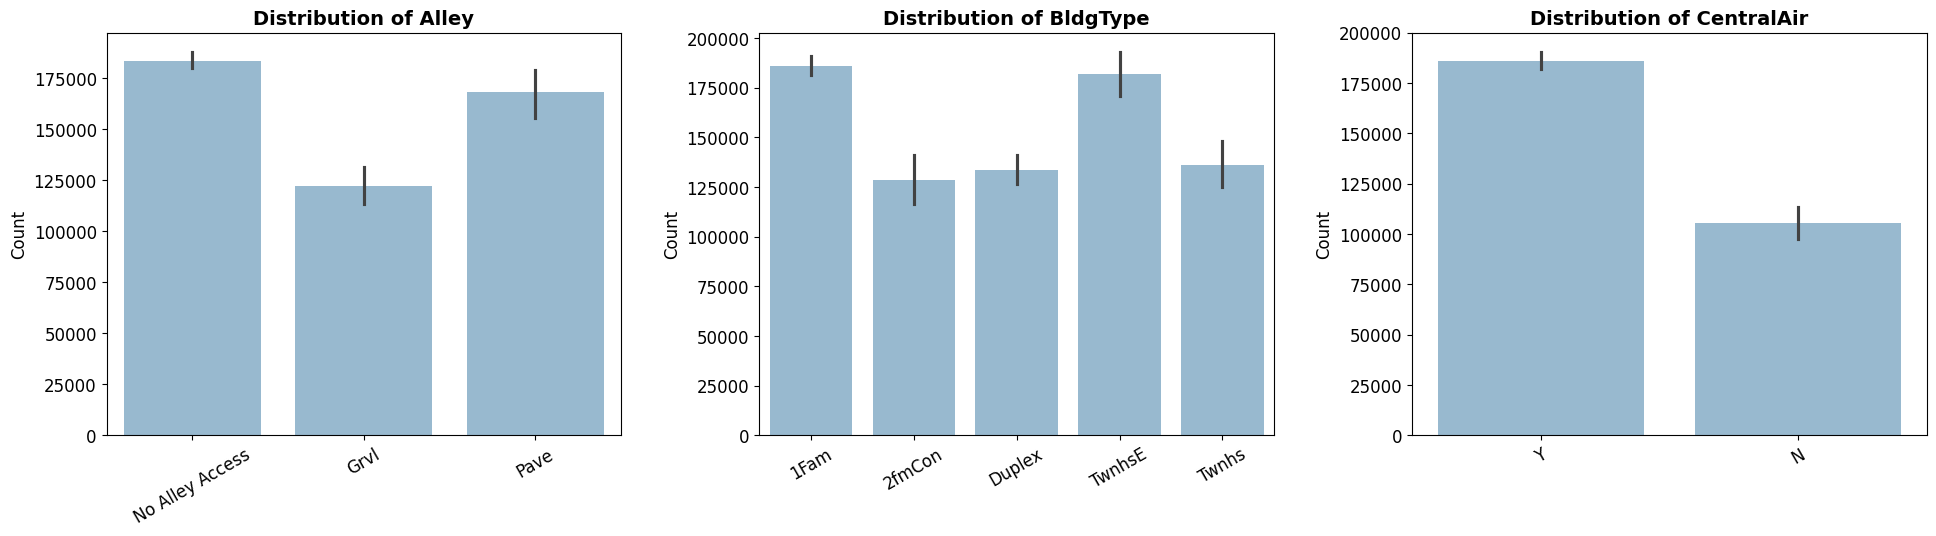

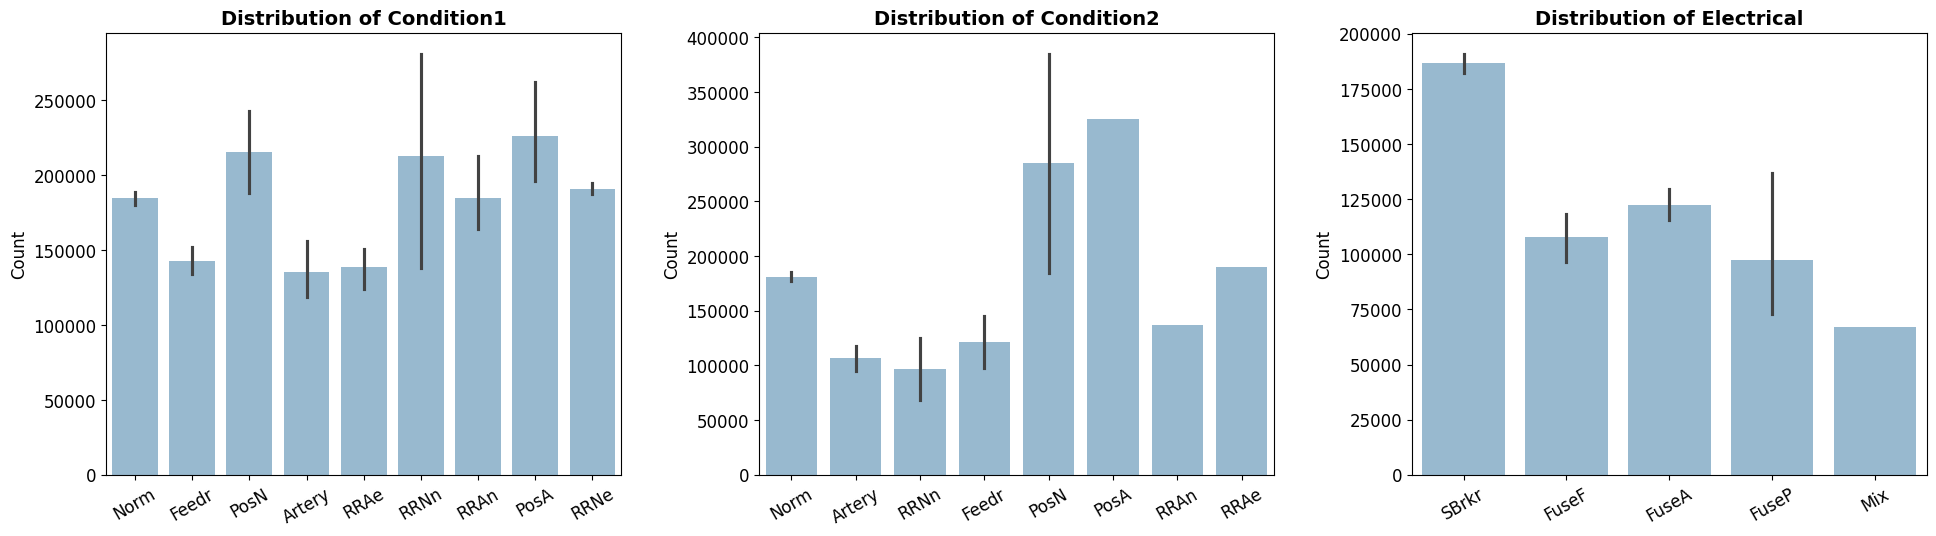

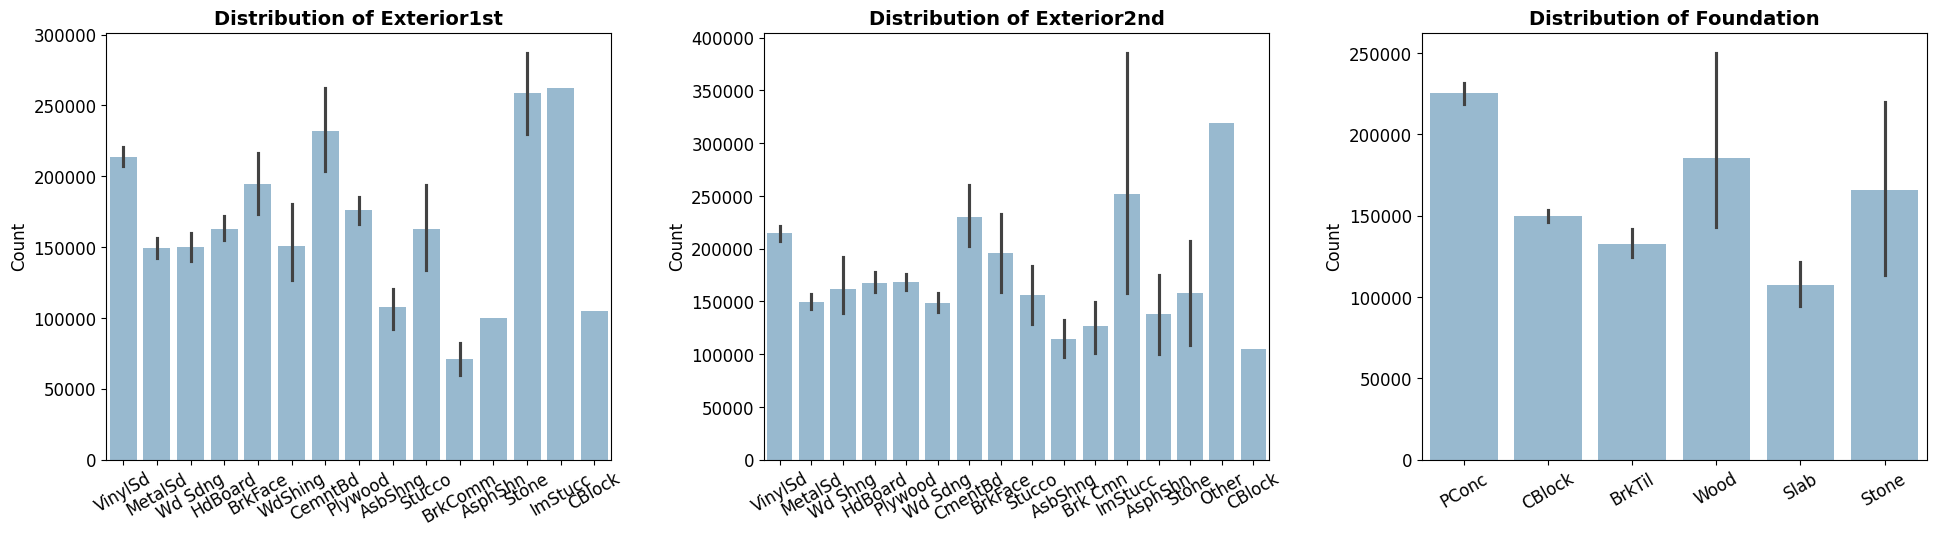

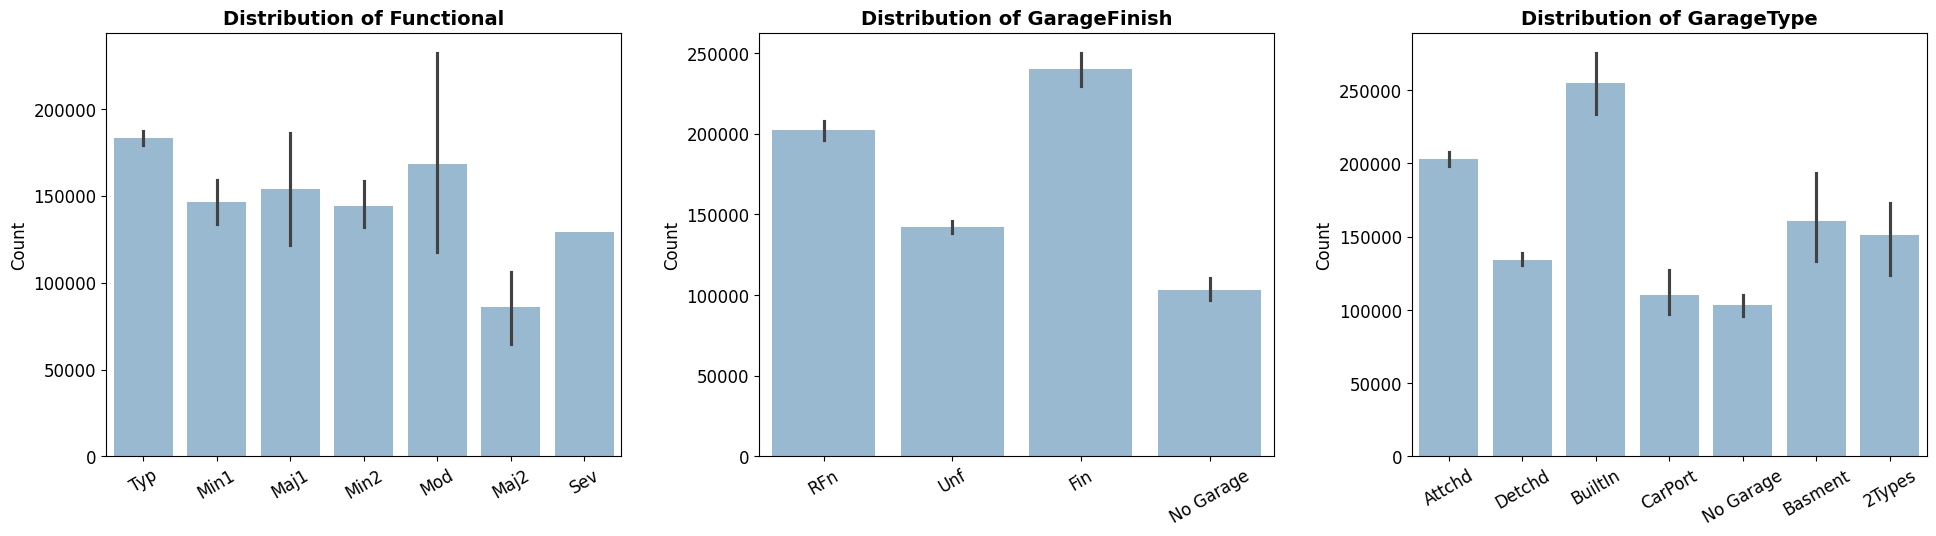

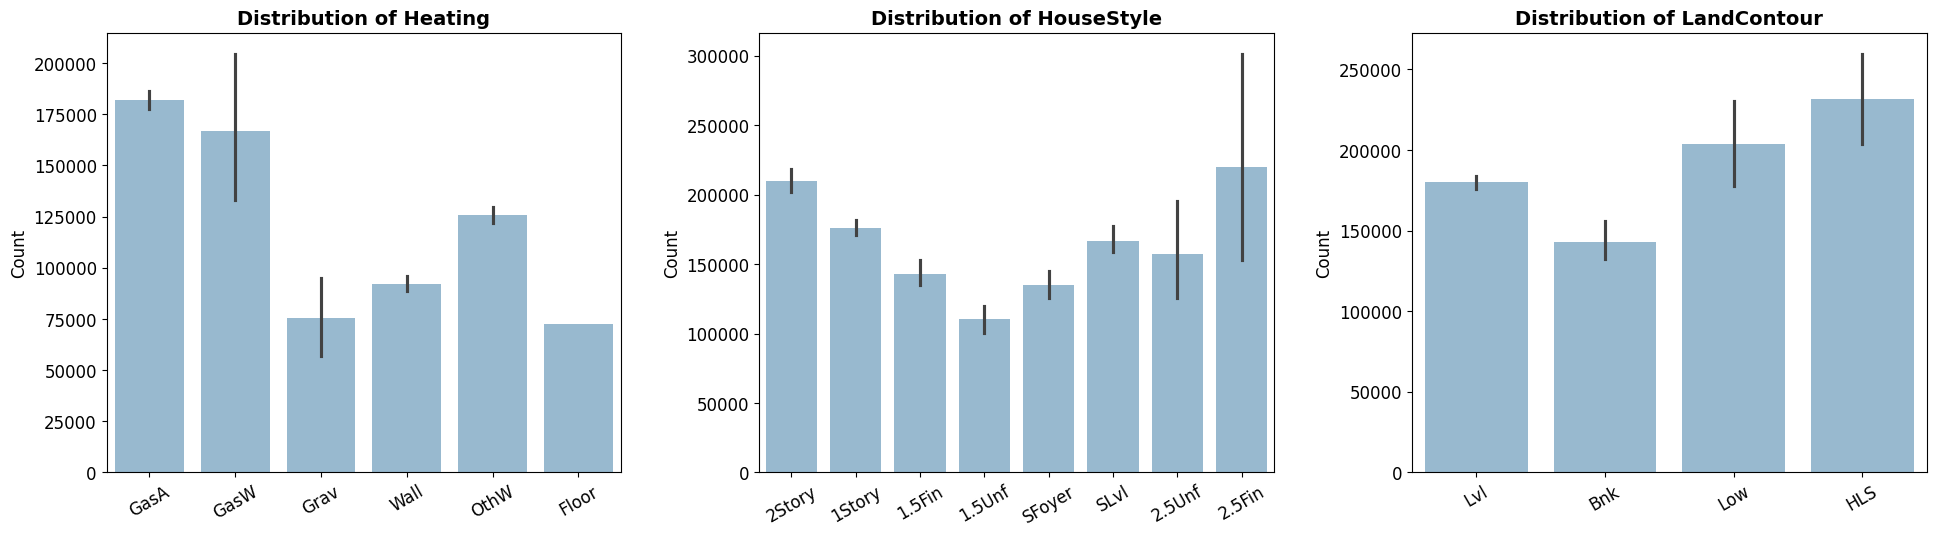

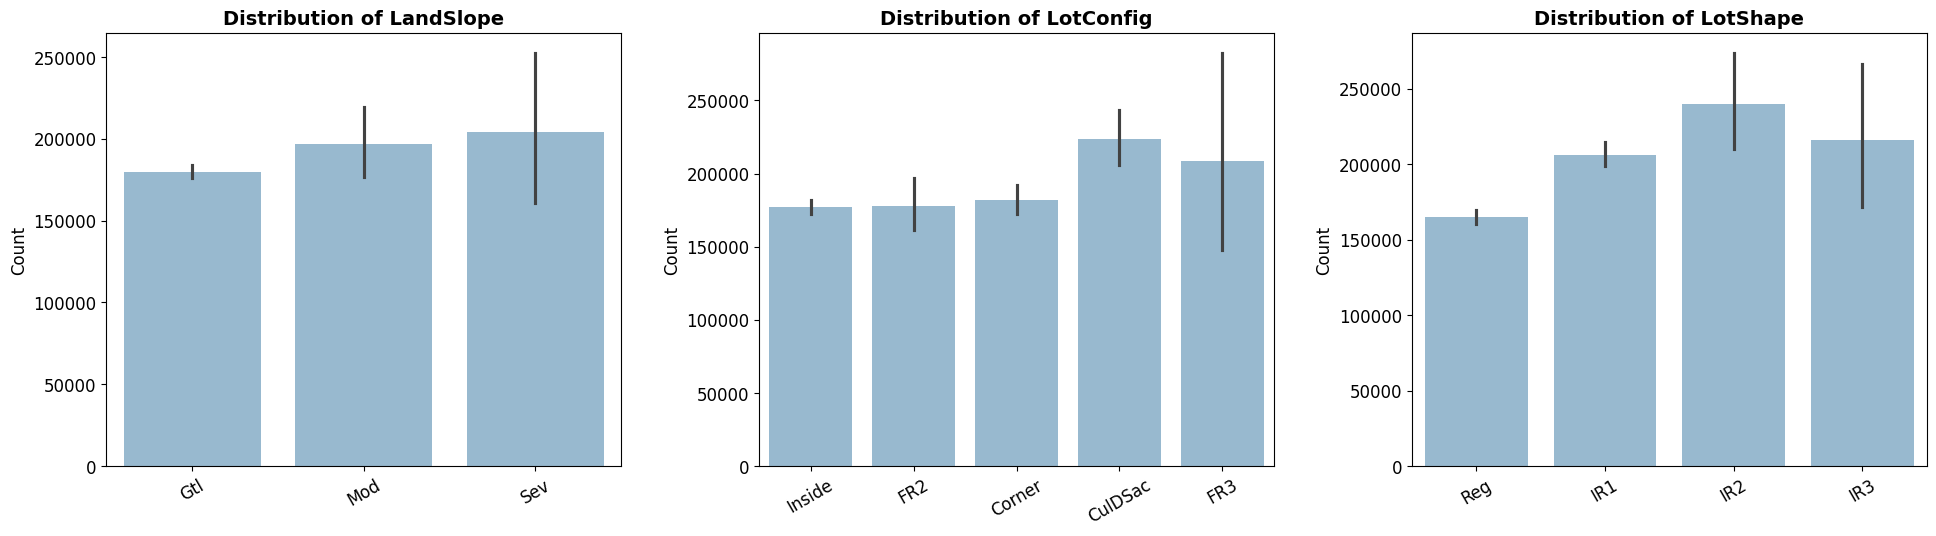

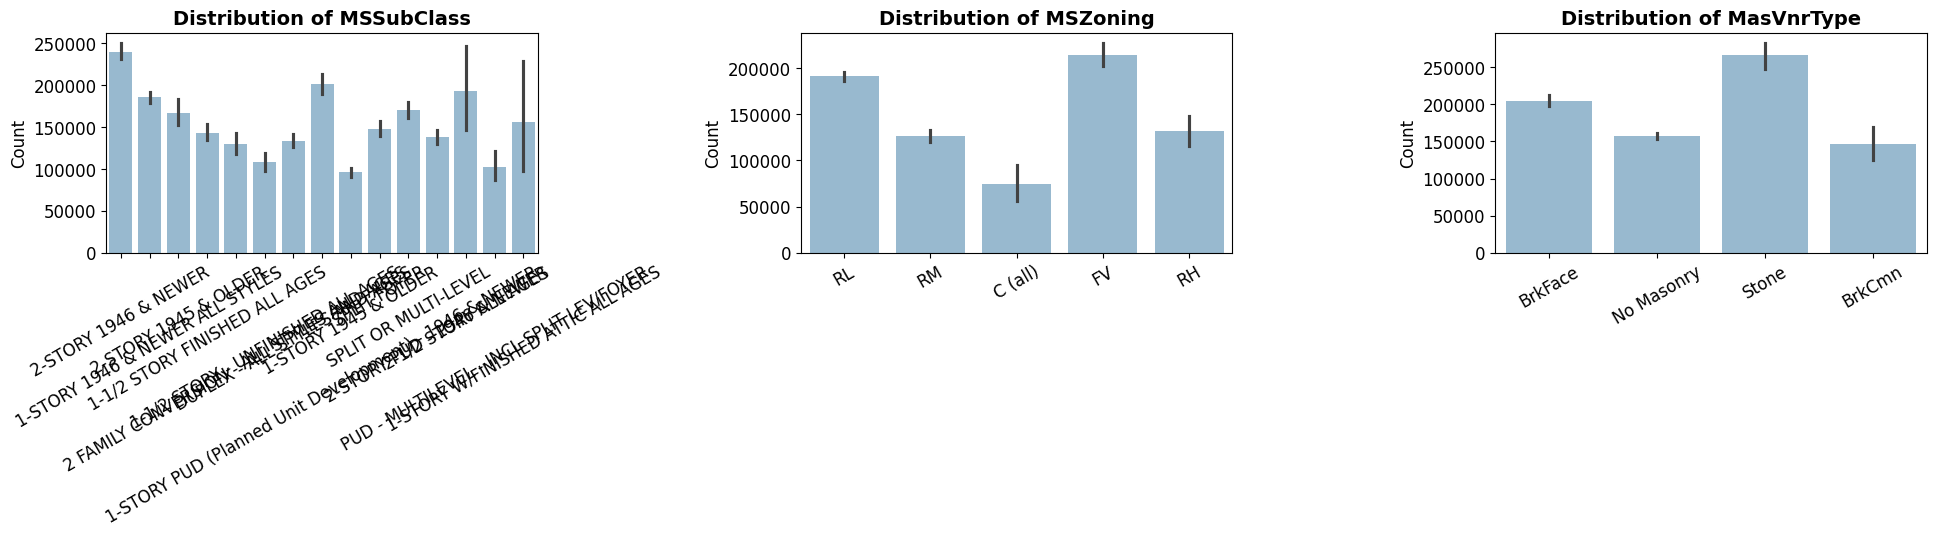

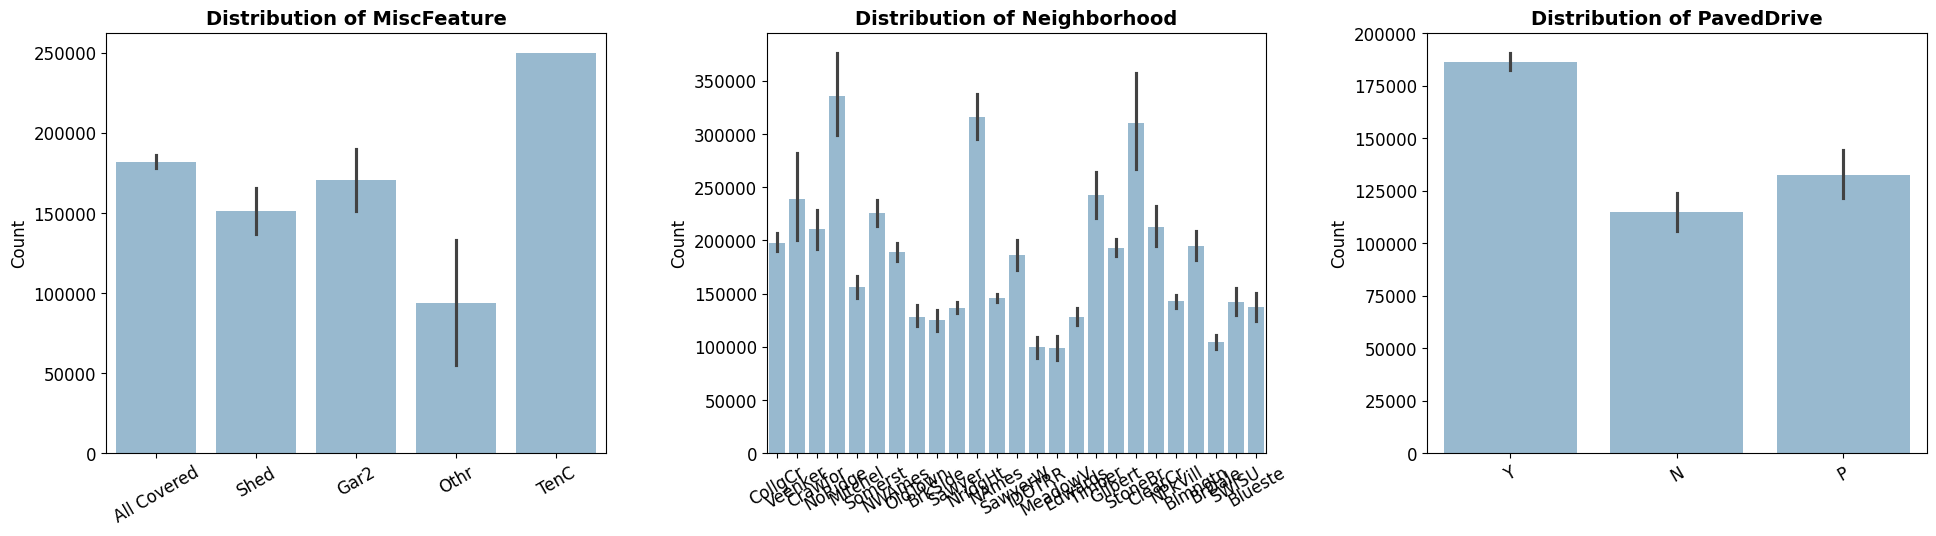

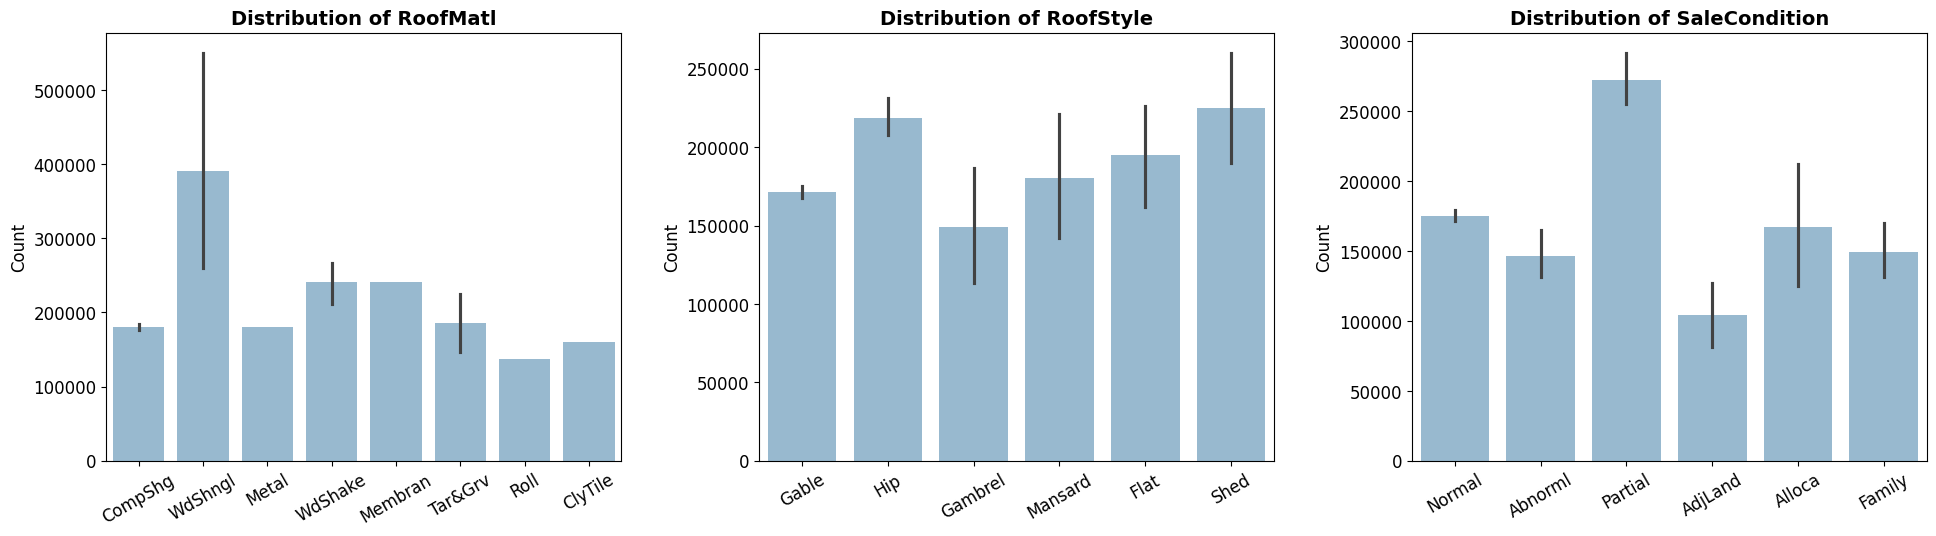

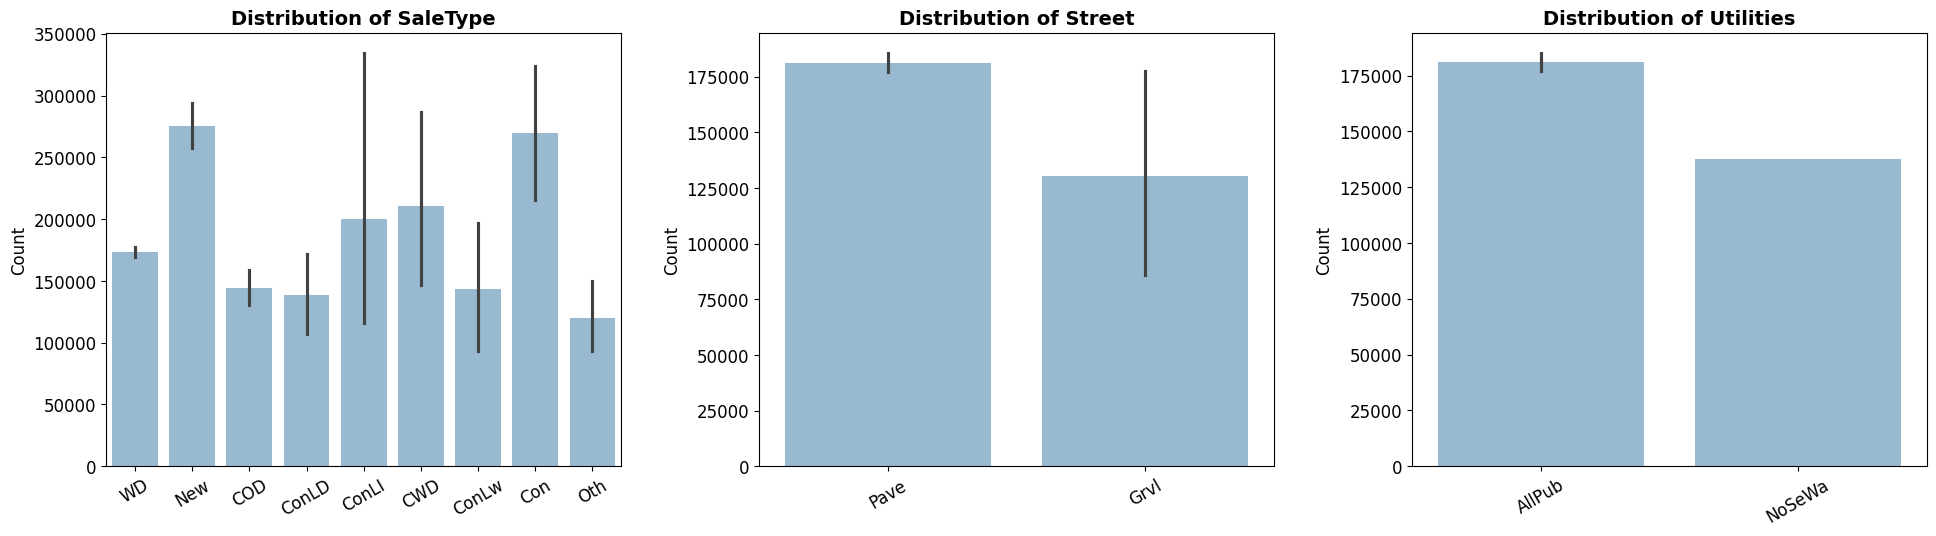

In [27]:
ncols = 3
nrows = 1

for i in range(0, len(nominal_cat_vars), ncols):
    chunk_vars = nominal_cat_vars[i:i + ncols]

    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        sns.barplot(data=train, x=var, y="SalePrice", alpha=0.5, ax=axs[j])
        axs[j].set_title(f"SalePrice vs {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel("")
        axs[j].set_ylabel("SalePrice", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

In some cases we notice that a category makes up almost the totality of the possible categories. This might indicate we could drop those columns or crate an `Other` category

## Numerical Features

### Discrete

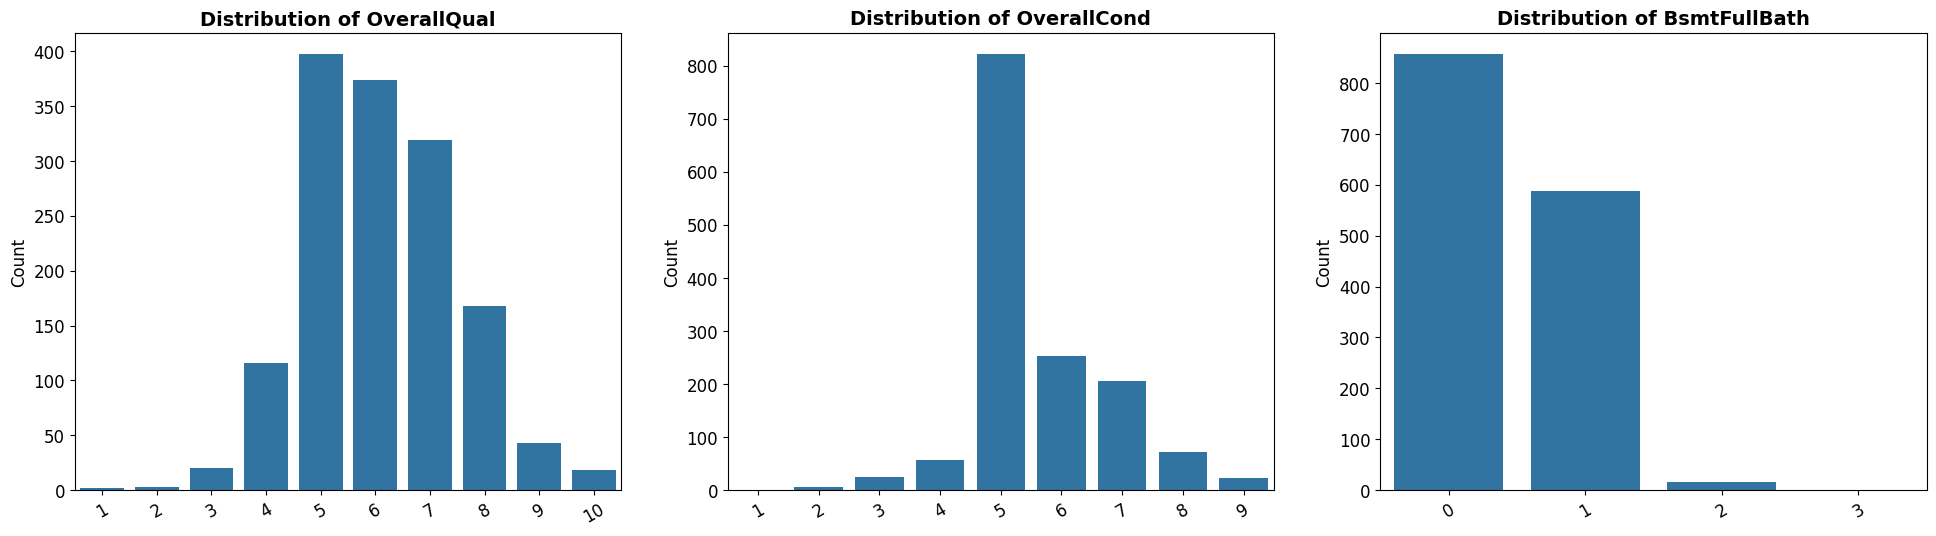

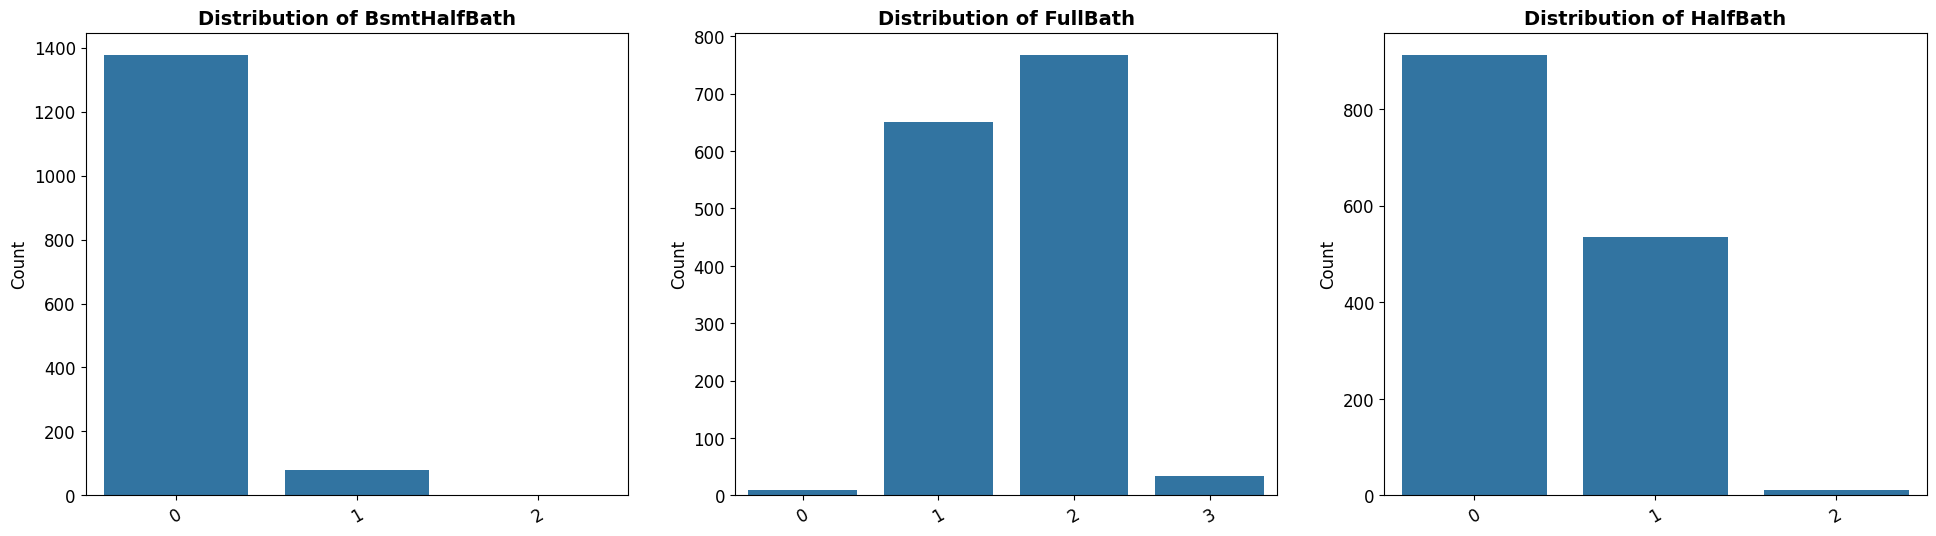

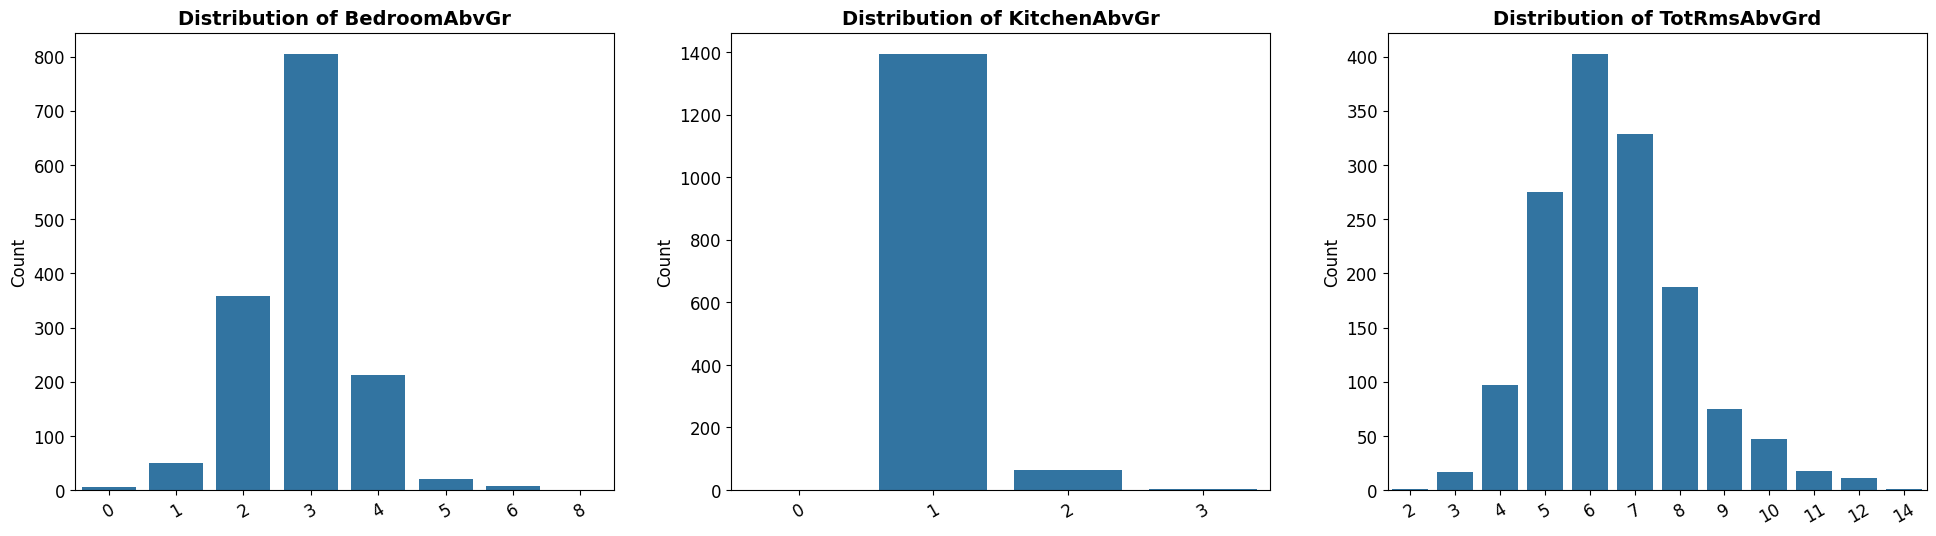

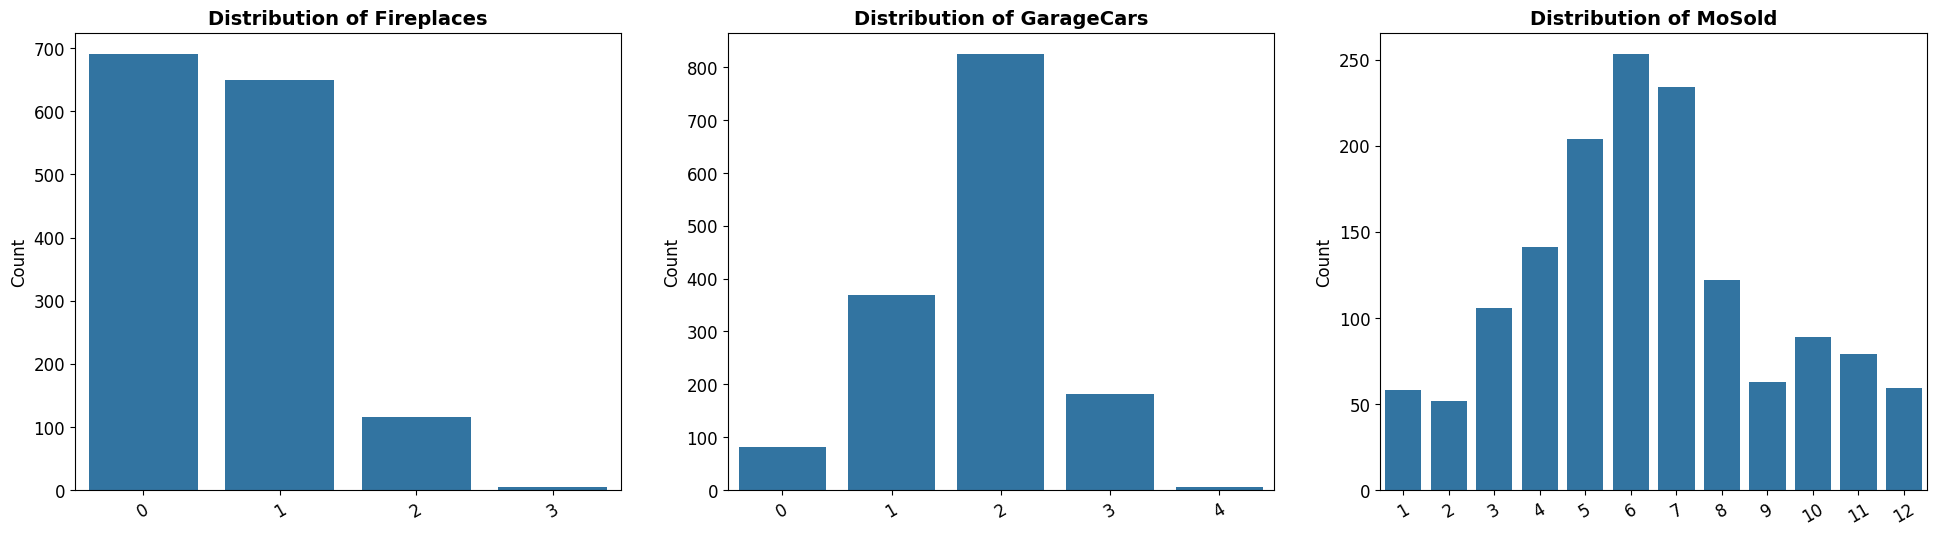

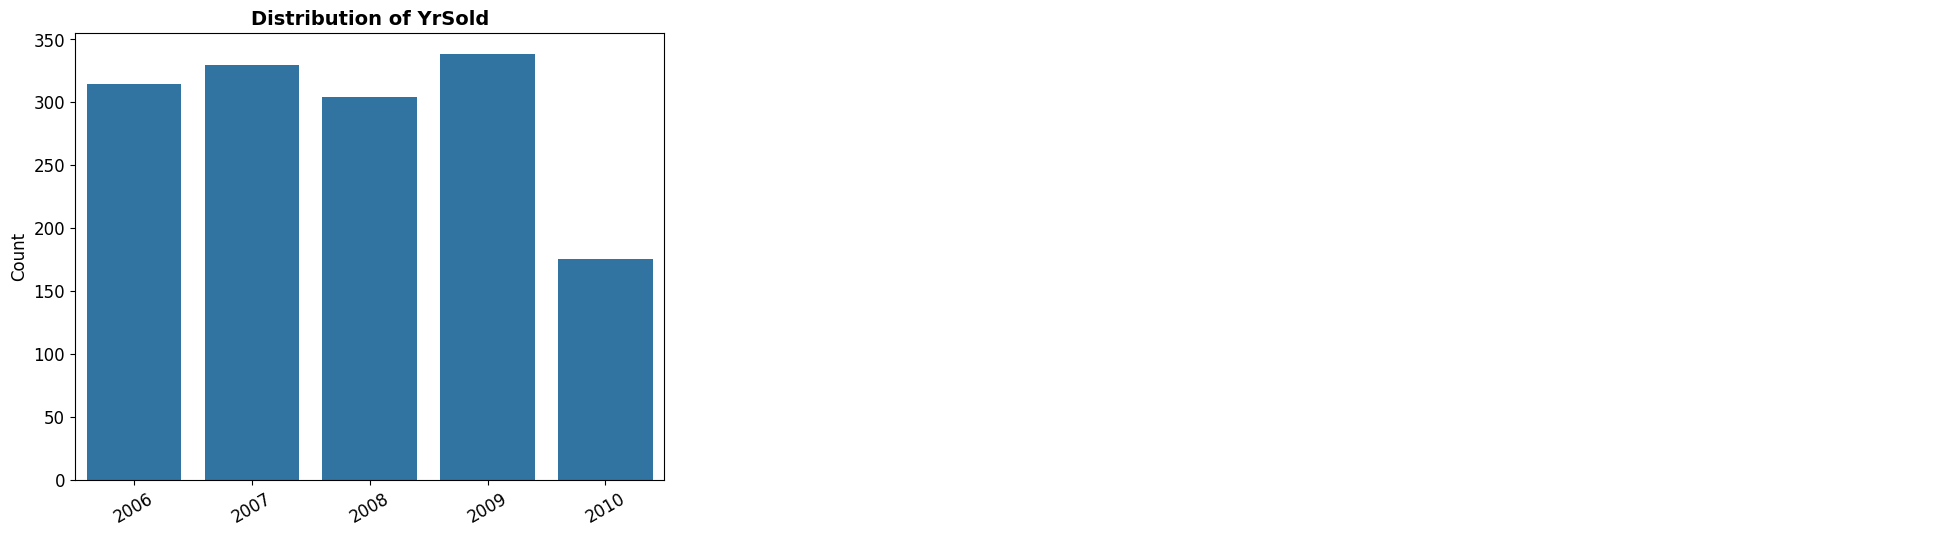

In [28]:
ncols = 3
nrows = 1

for i in range(0, len(discrete_num_vars), ncols):
    chunk_vars = discrete_num_vars[i:i + ncols]
    
    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        sns.countplot(data=train, x=var, ax=axs[j])
        axs[j].set_title(f"Distribution of {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel("")
        axs[j].set_ylabel("Count", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

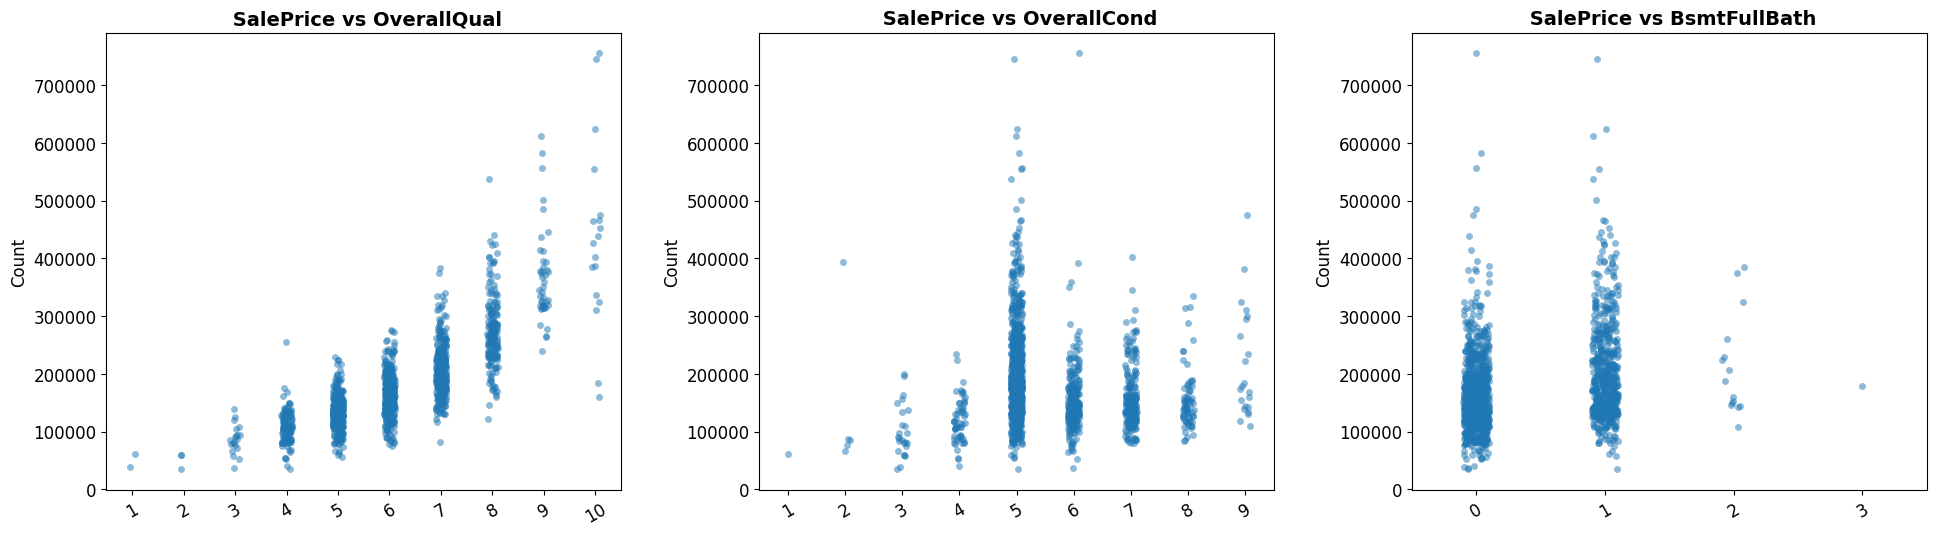

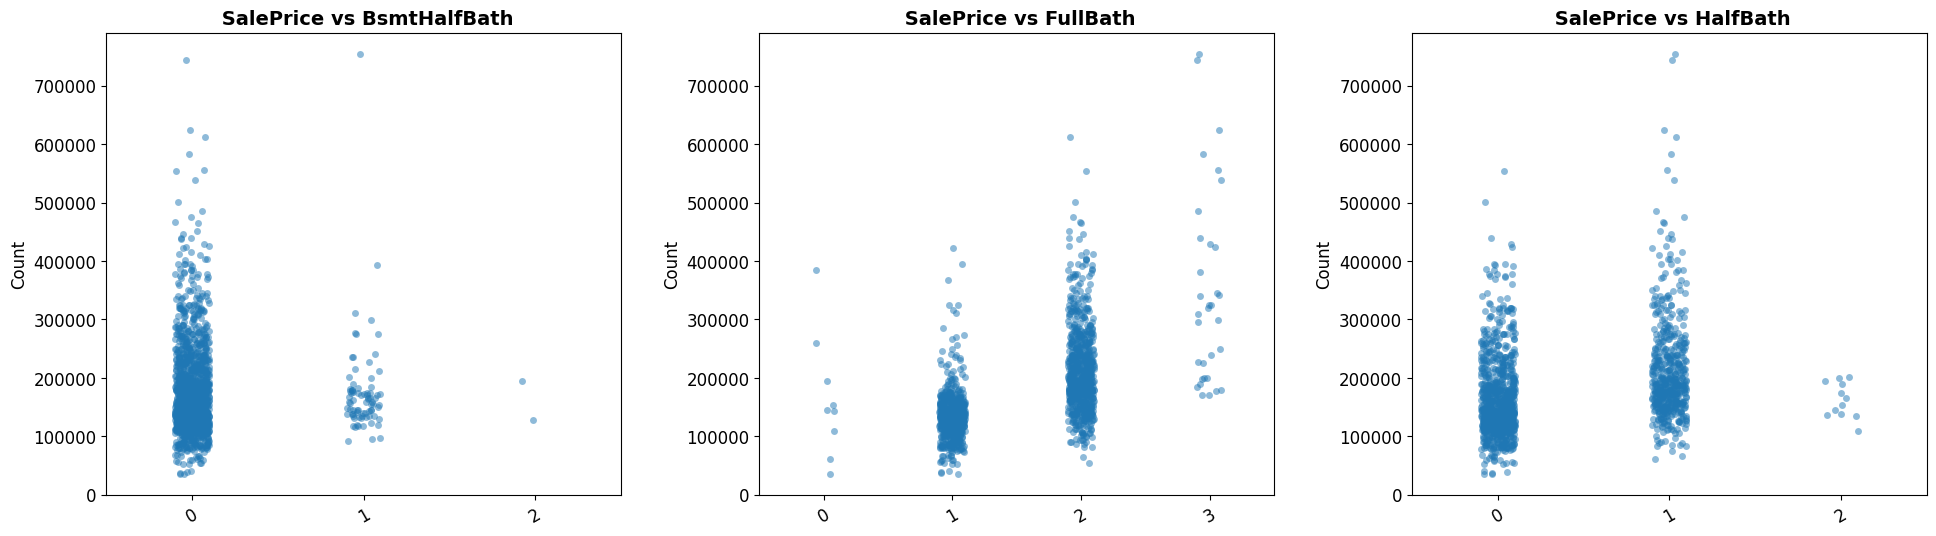

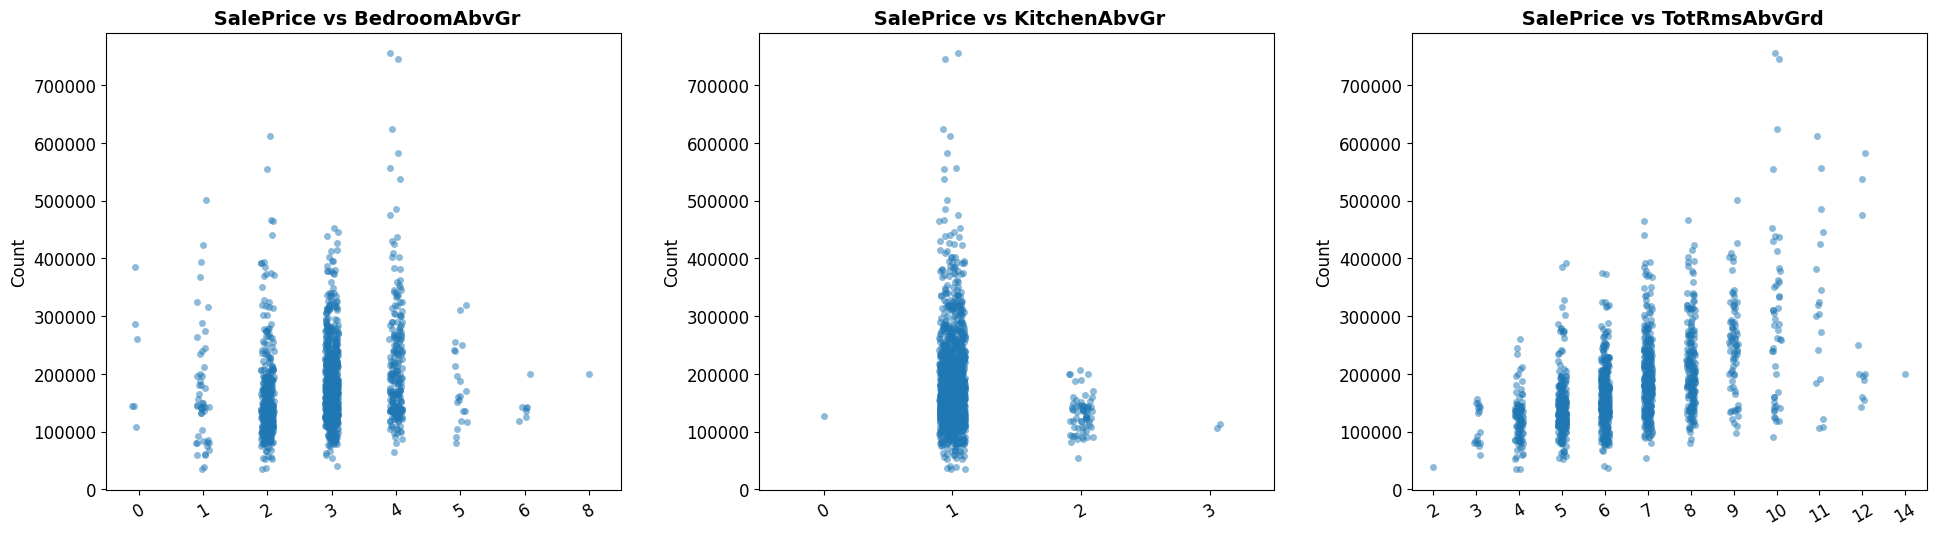

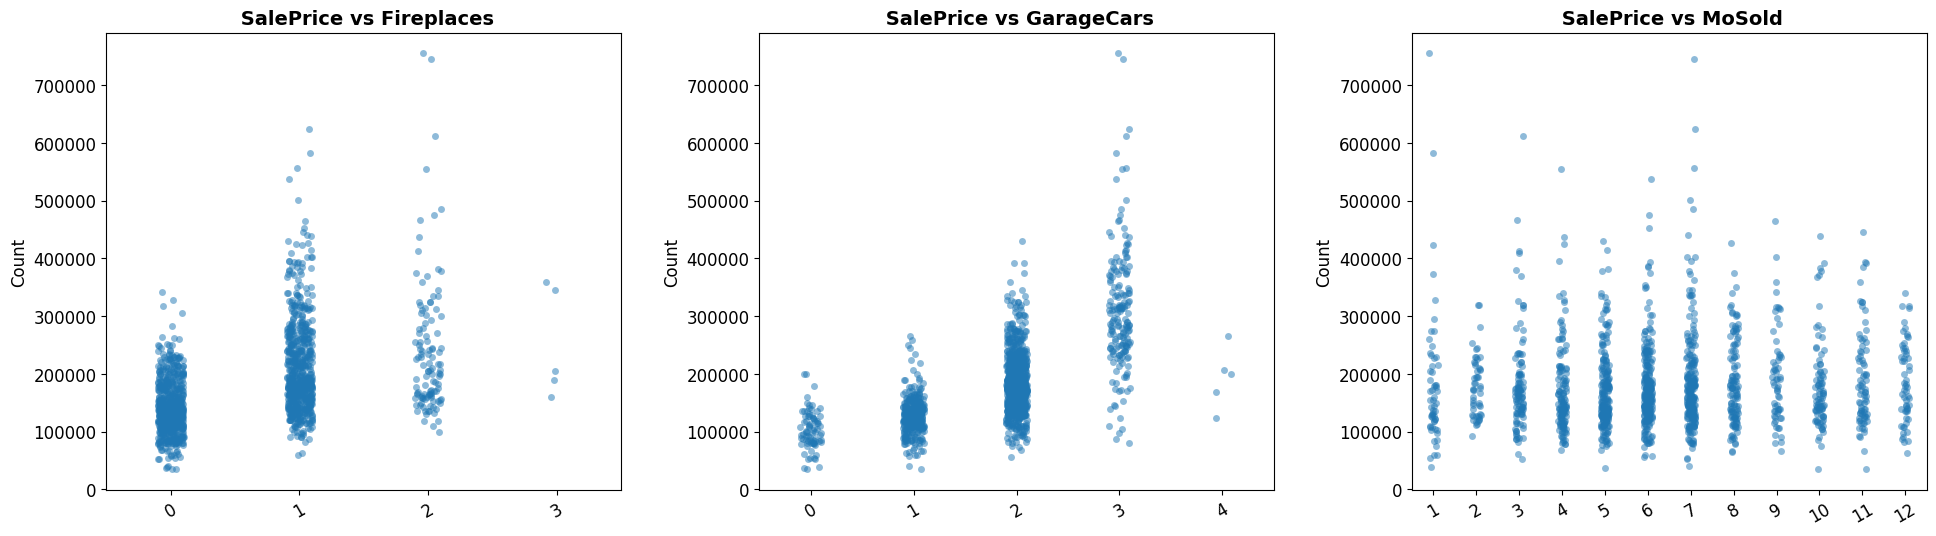

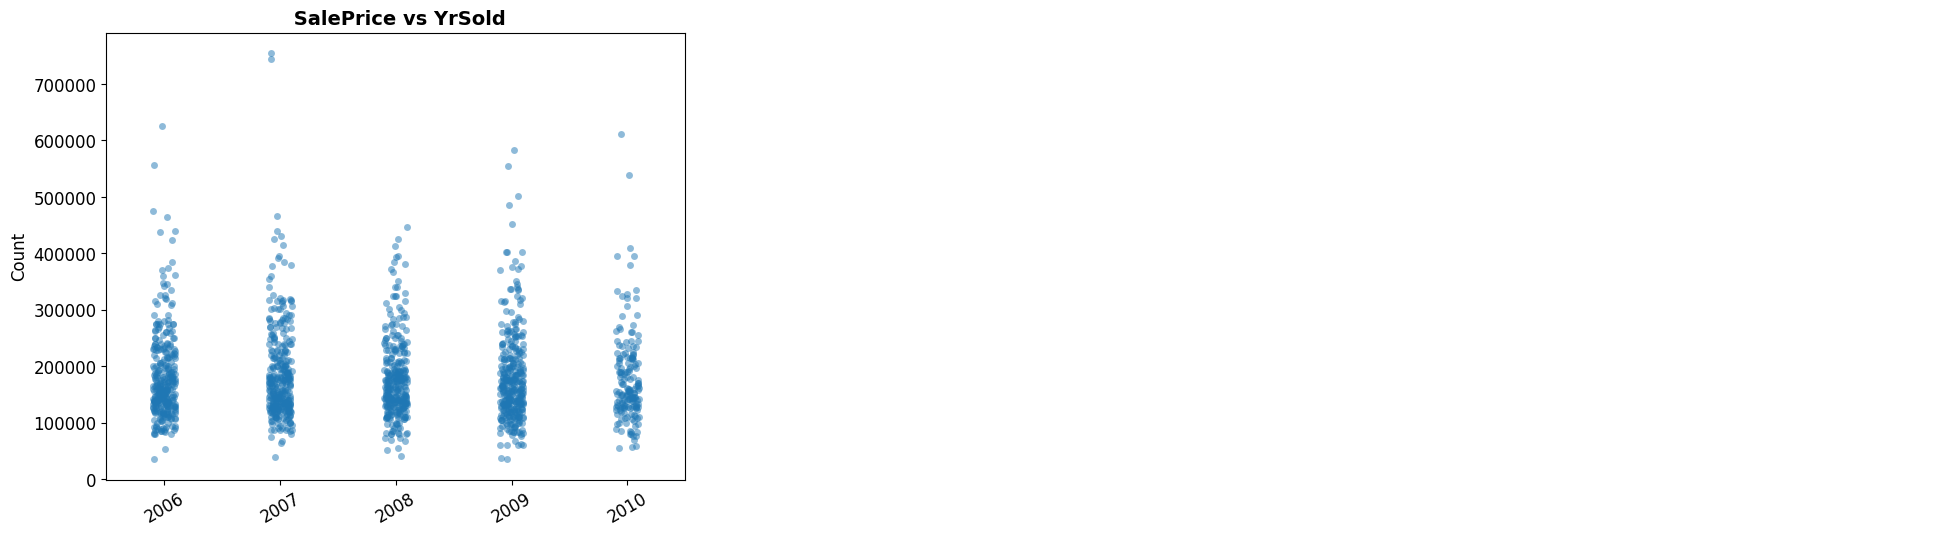

In [29]:
ncols = 3
nrows = 1

for i in range(0, len(discrete_num_vars), ncols):
    chunk_vars = discrete_num_vars[i:i + ncols]
    
    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        sns.stripplot(data=train, x=var, y="SalePrice", alpha=0.5, ax=axs[j])
        axs[j].set_title(f" SalePrice vs {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel("")
        axs[j].set_ylabel("Count", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

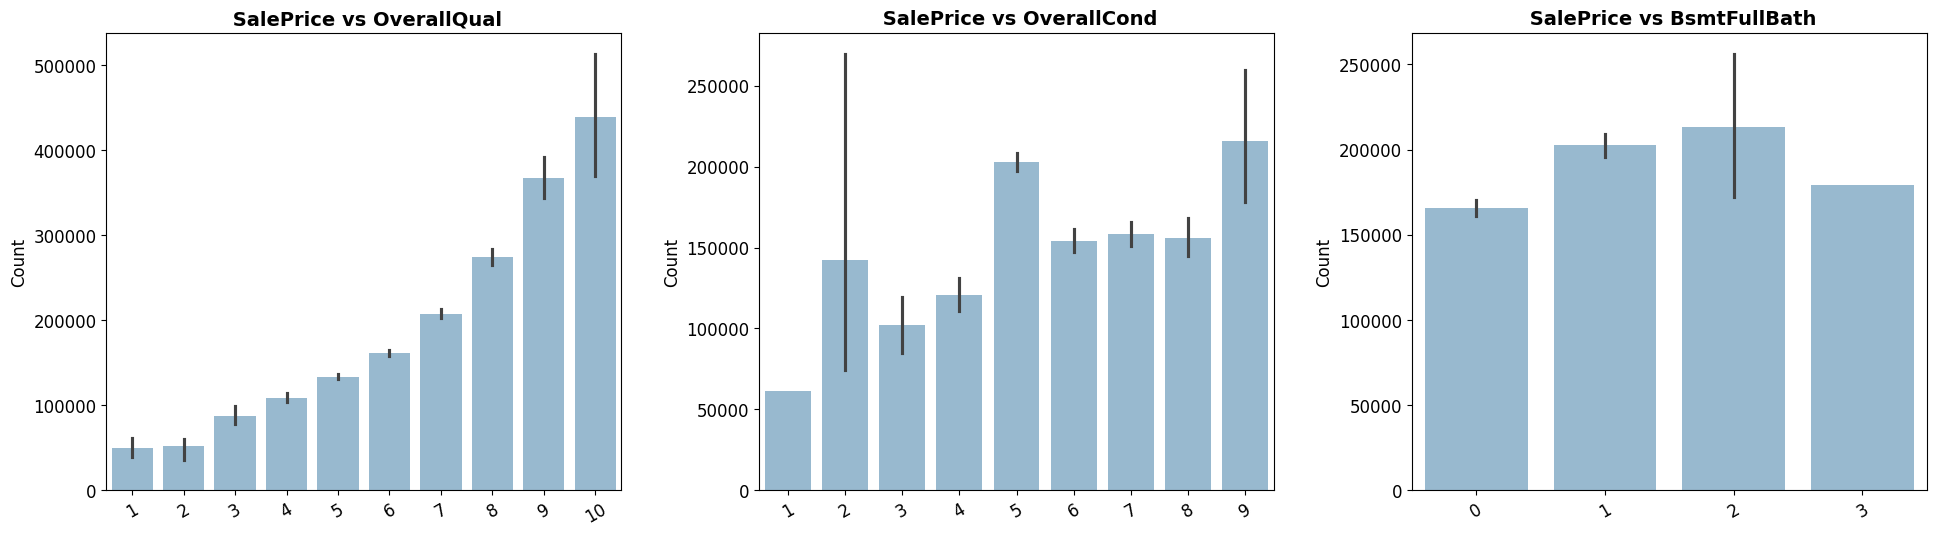

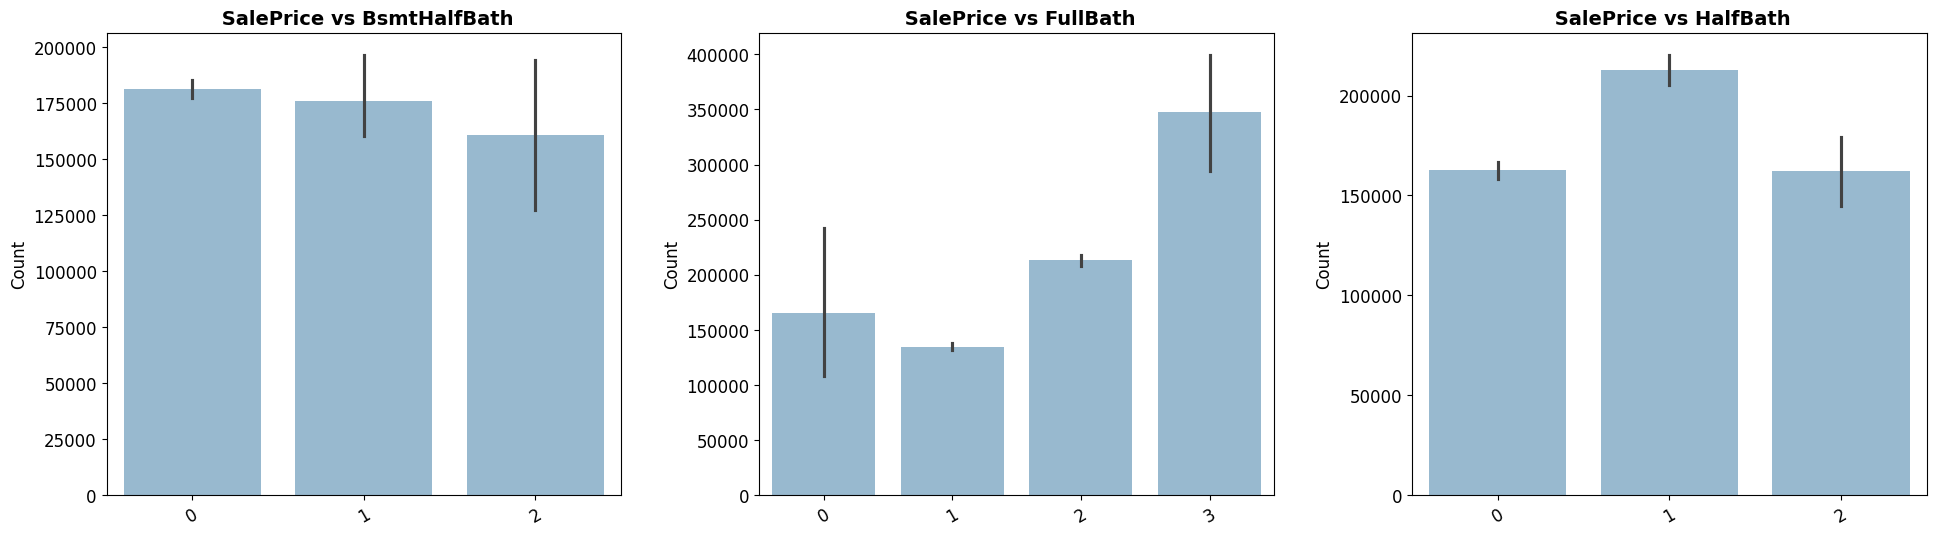

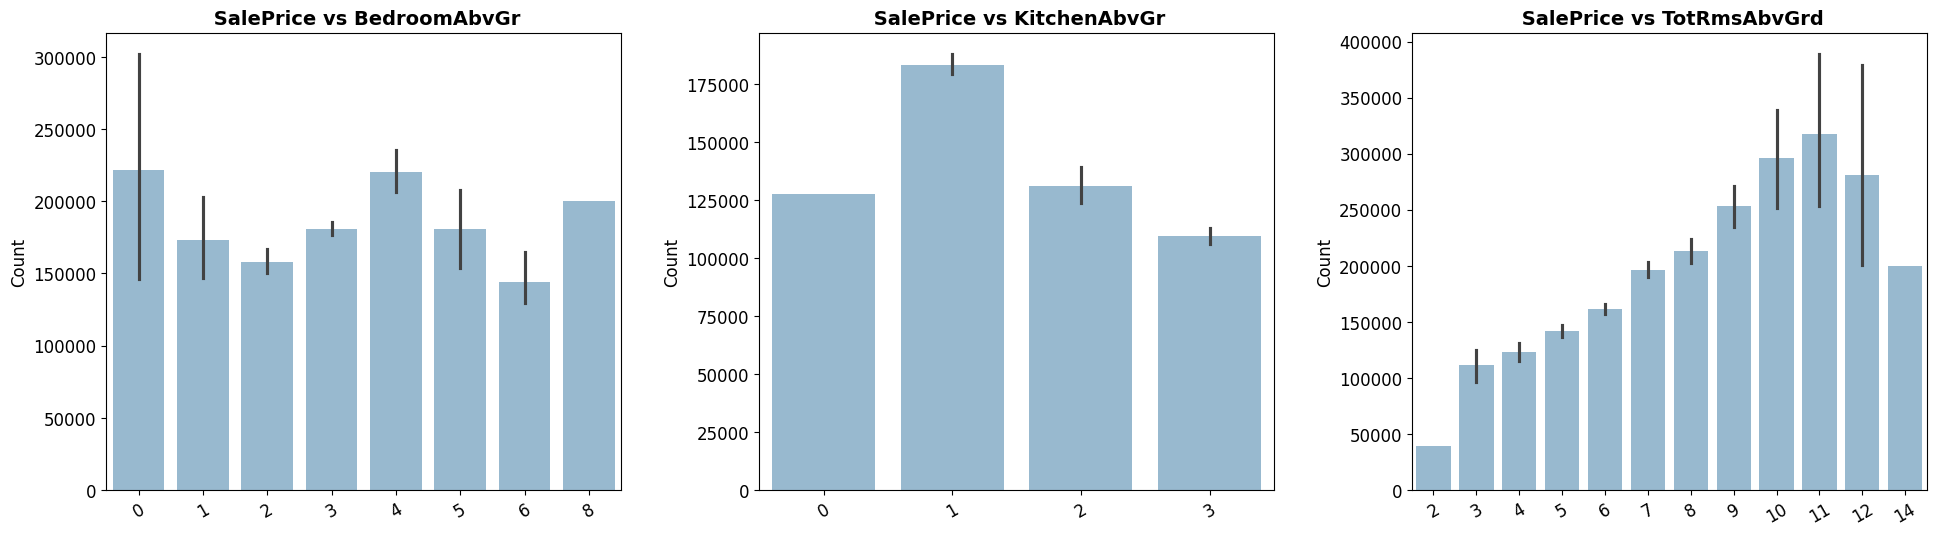

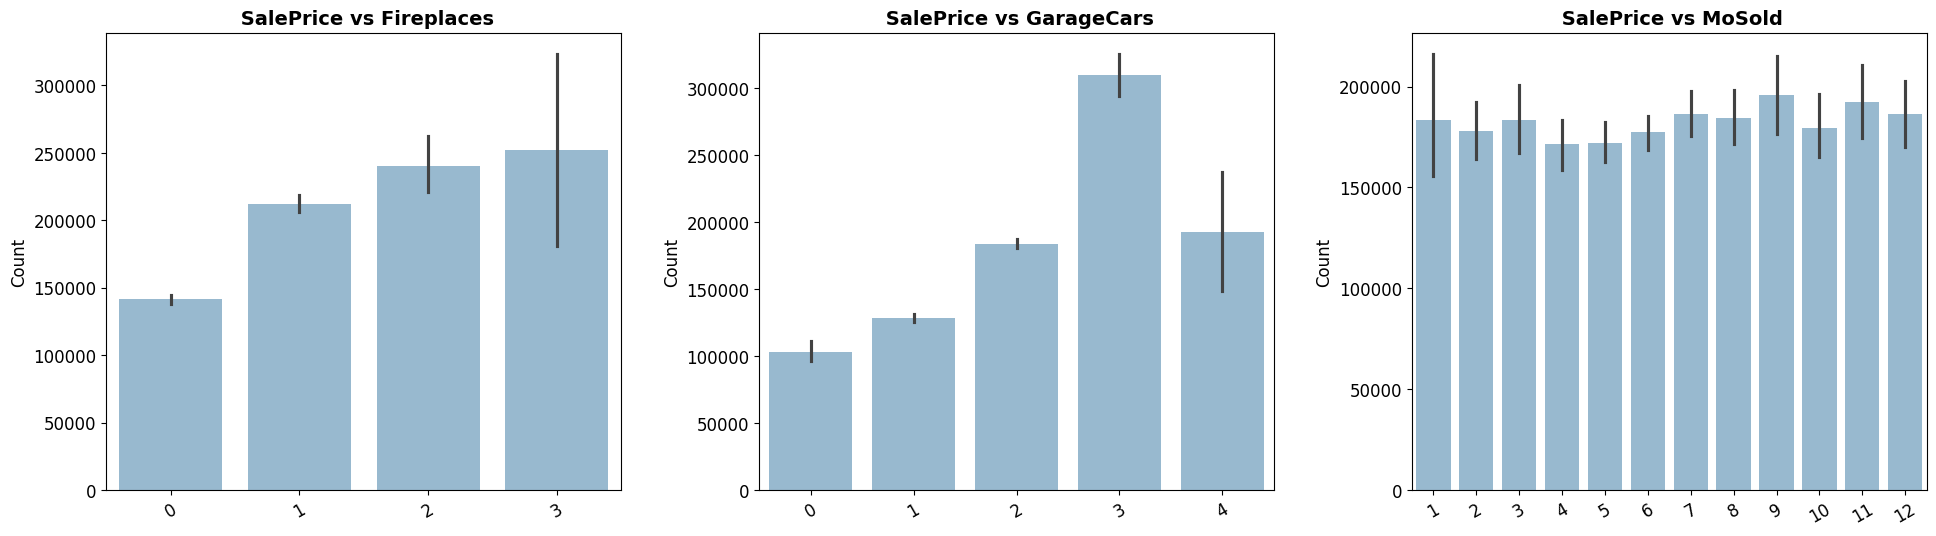

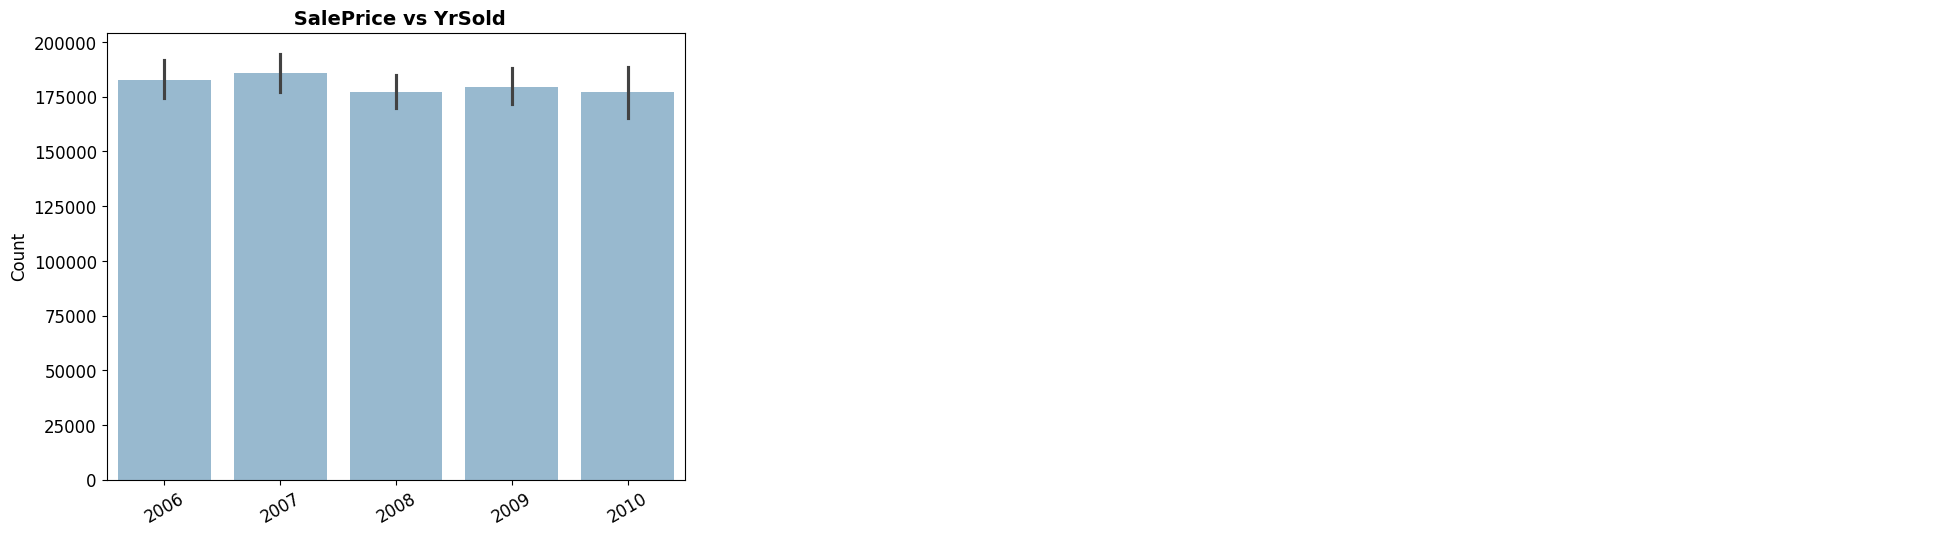

In [30]:
ncols = 3
nrows = 1

for i in range(0, len(discrete_num_vars), ncols):
    chunk_vars = discrete_num_vars[i:i + ncols]
    
    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        sns.barplot(data=train, x=var, y="SalePrice", alpha=0.5, ax=axs[j])
        axs[j].set_title(f" SalePrice vs {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel("")
        axs[j].set_ylabel("Count", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout(pad=3.0)
    plt.show()

### Continous

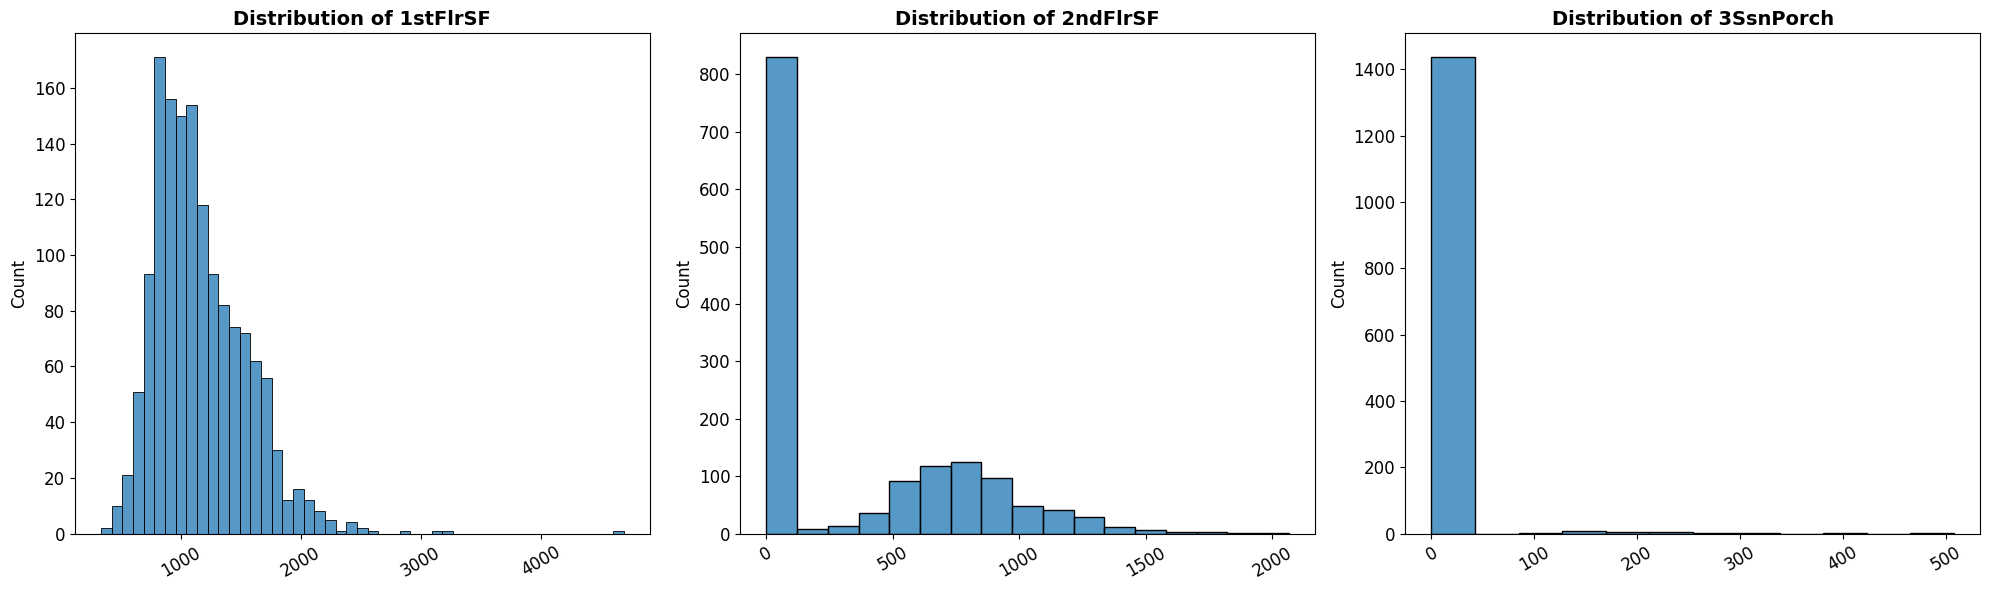

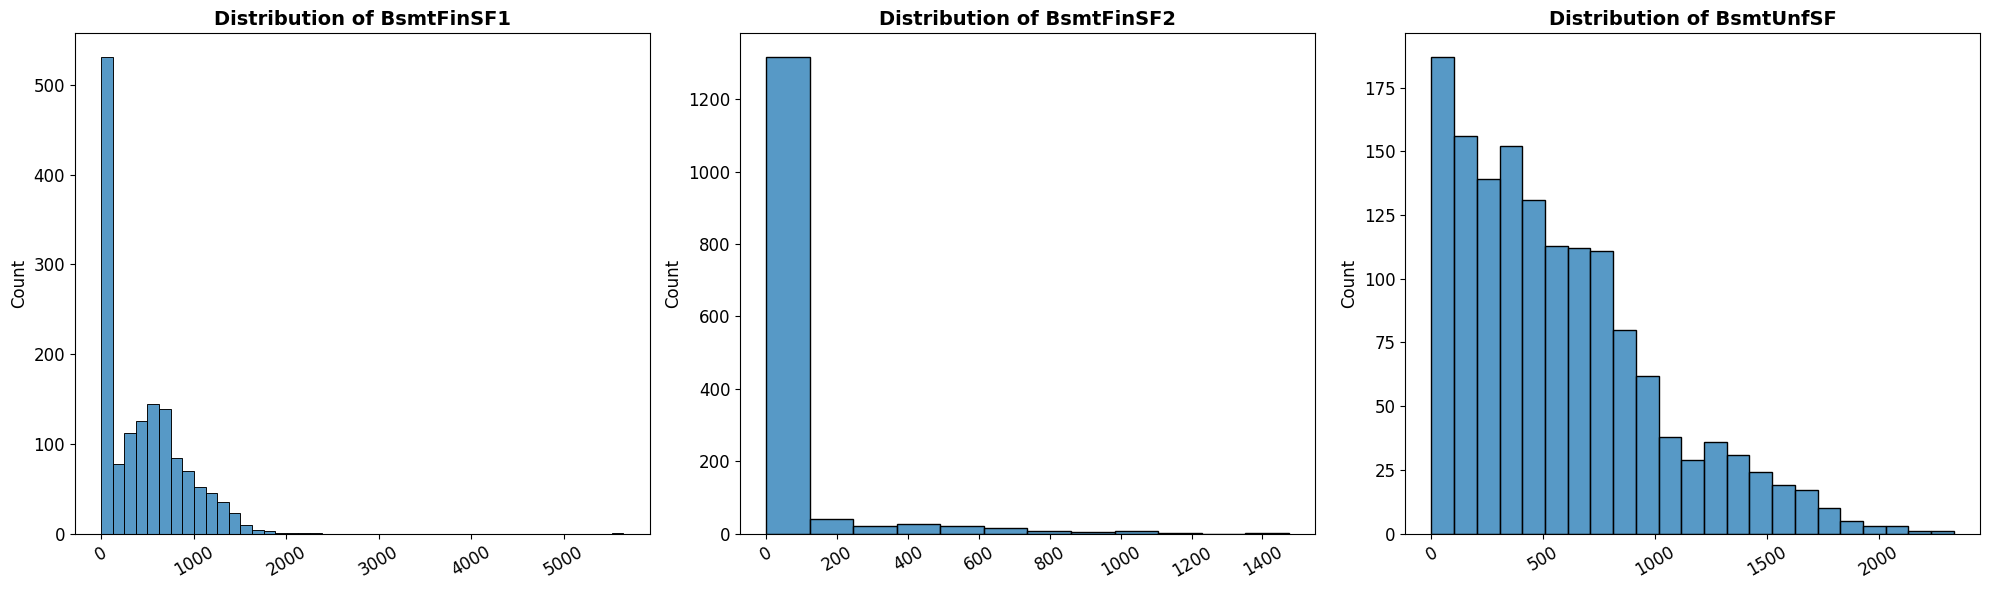

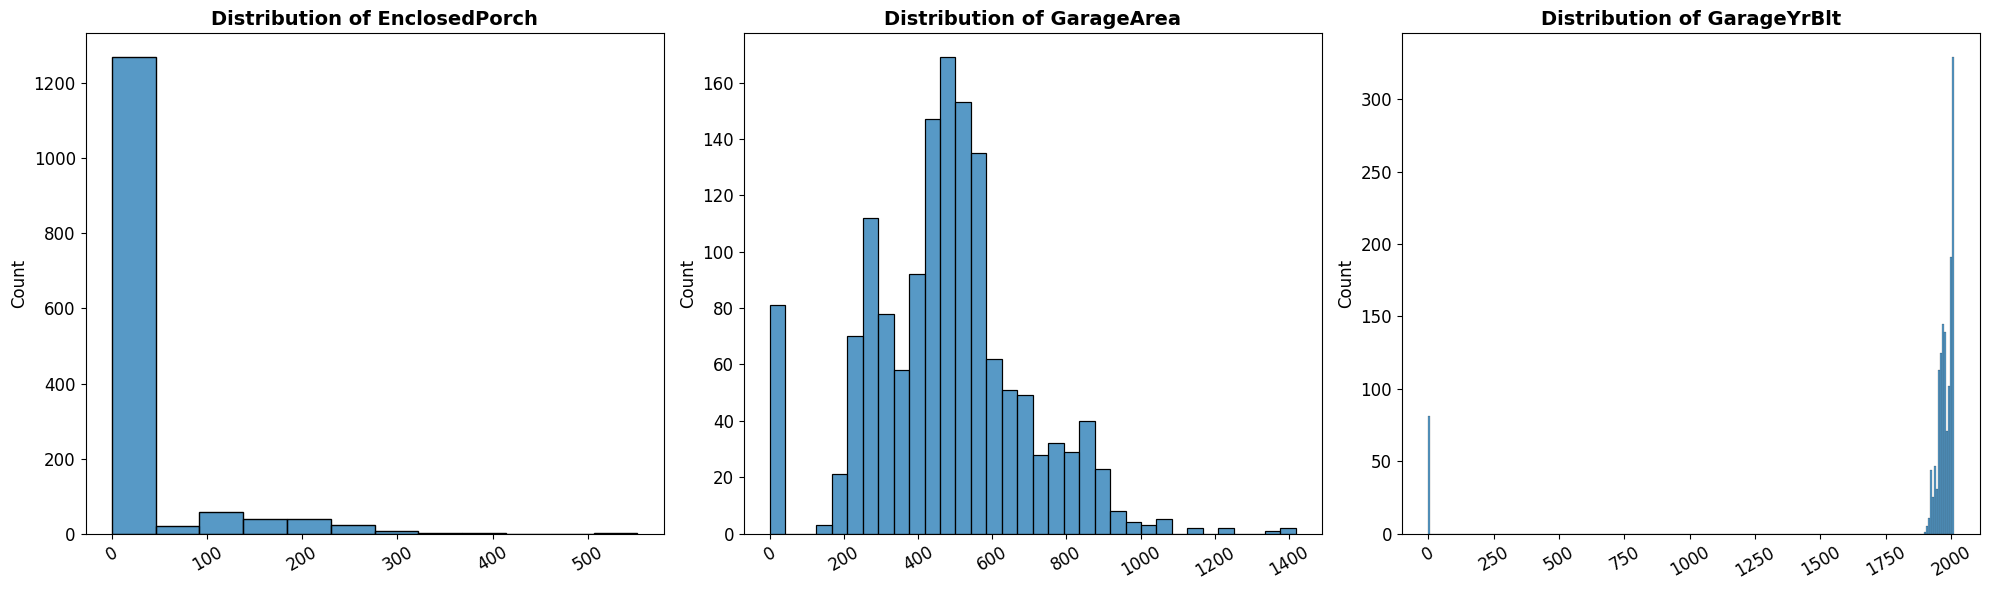

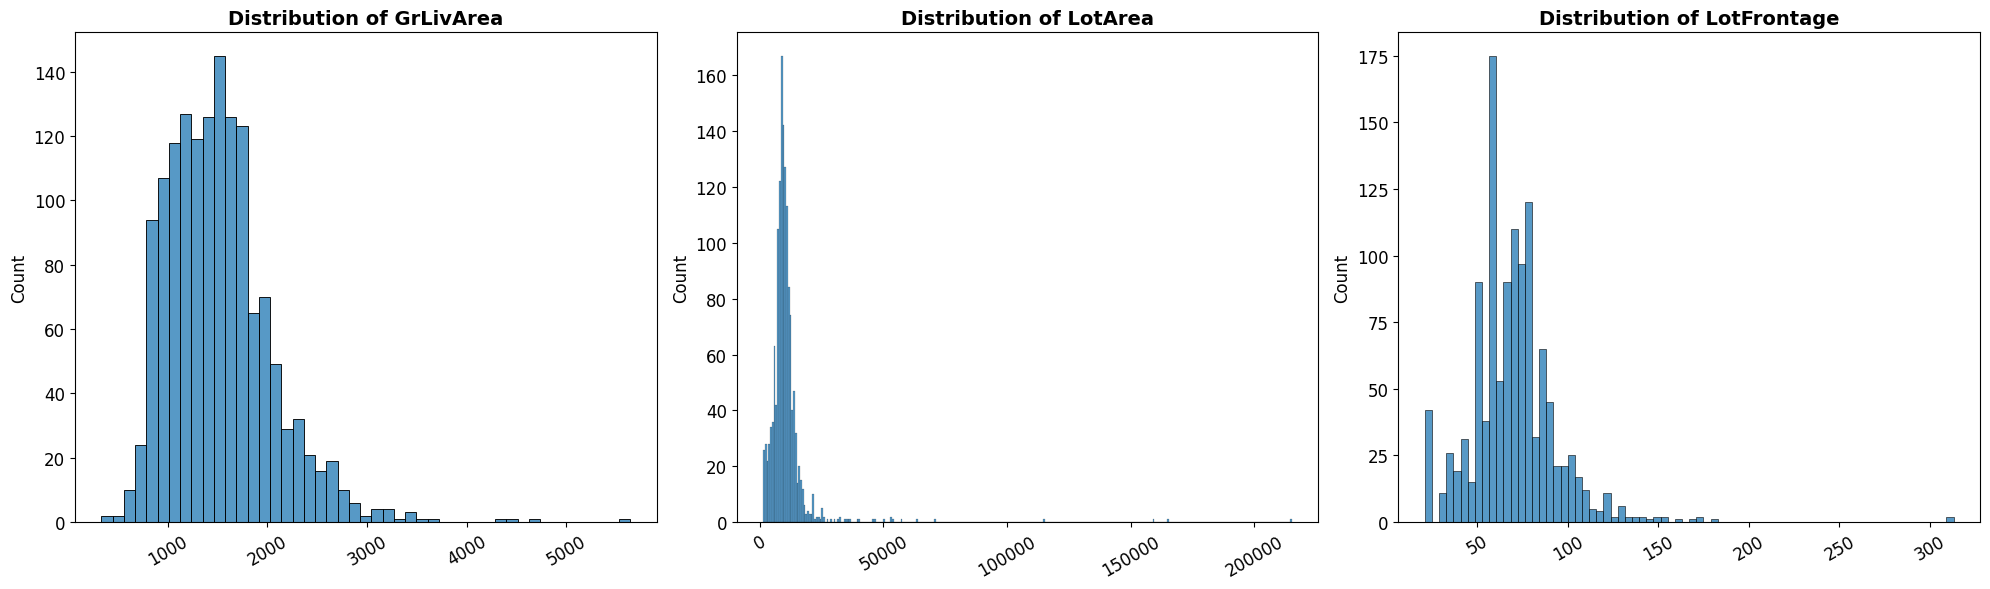

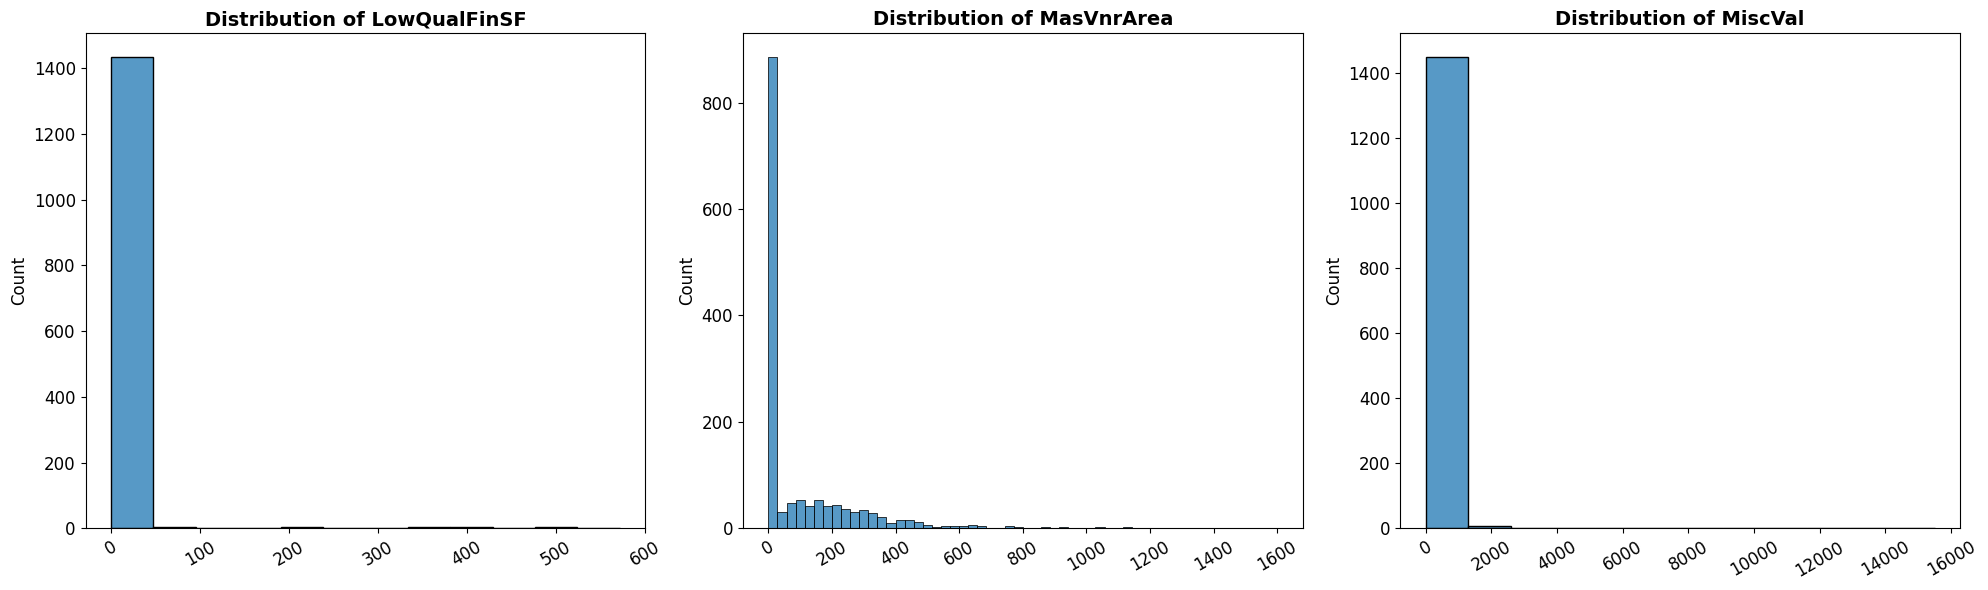

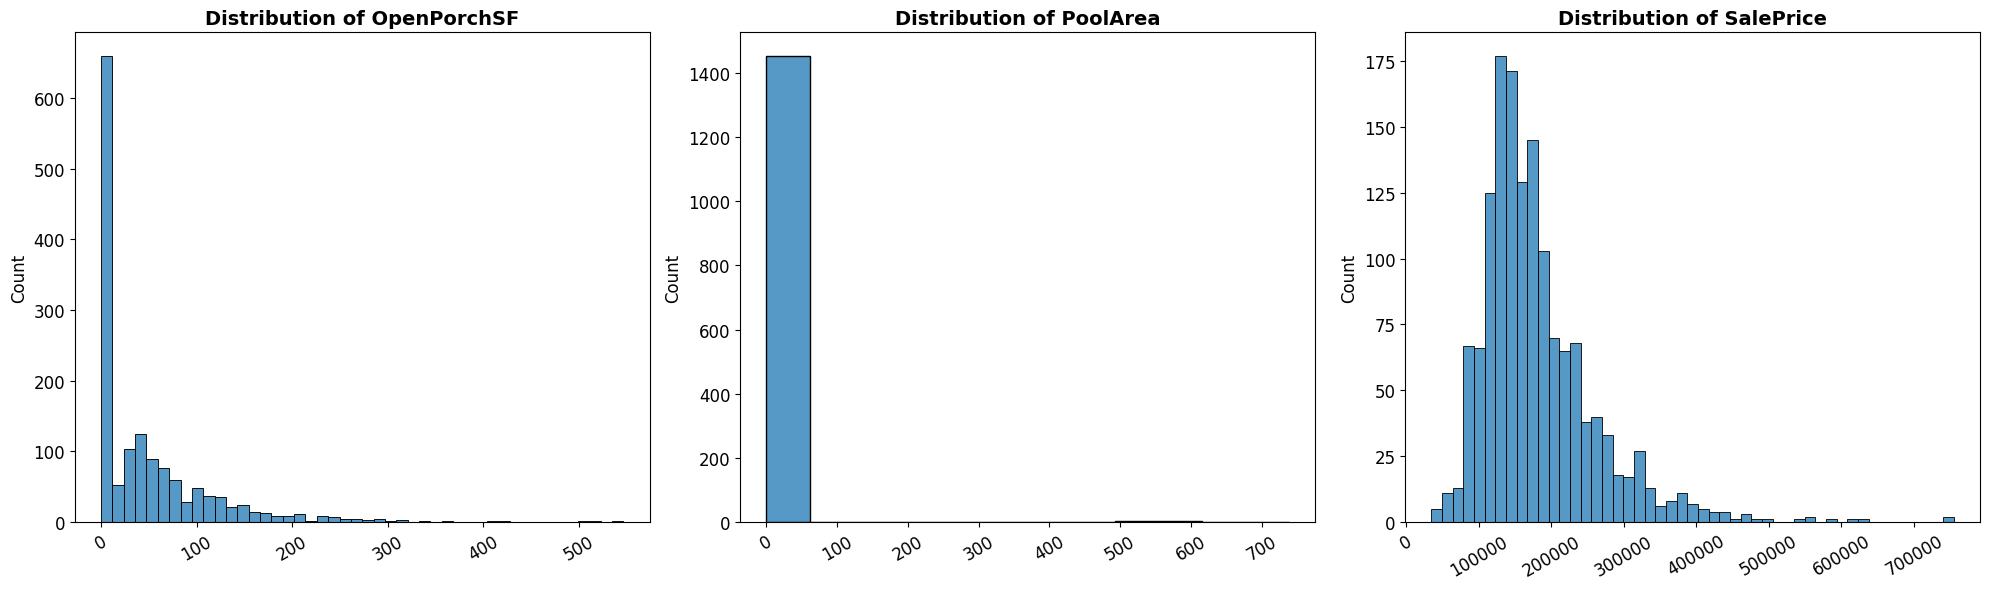

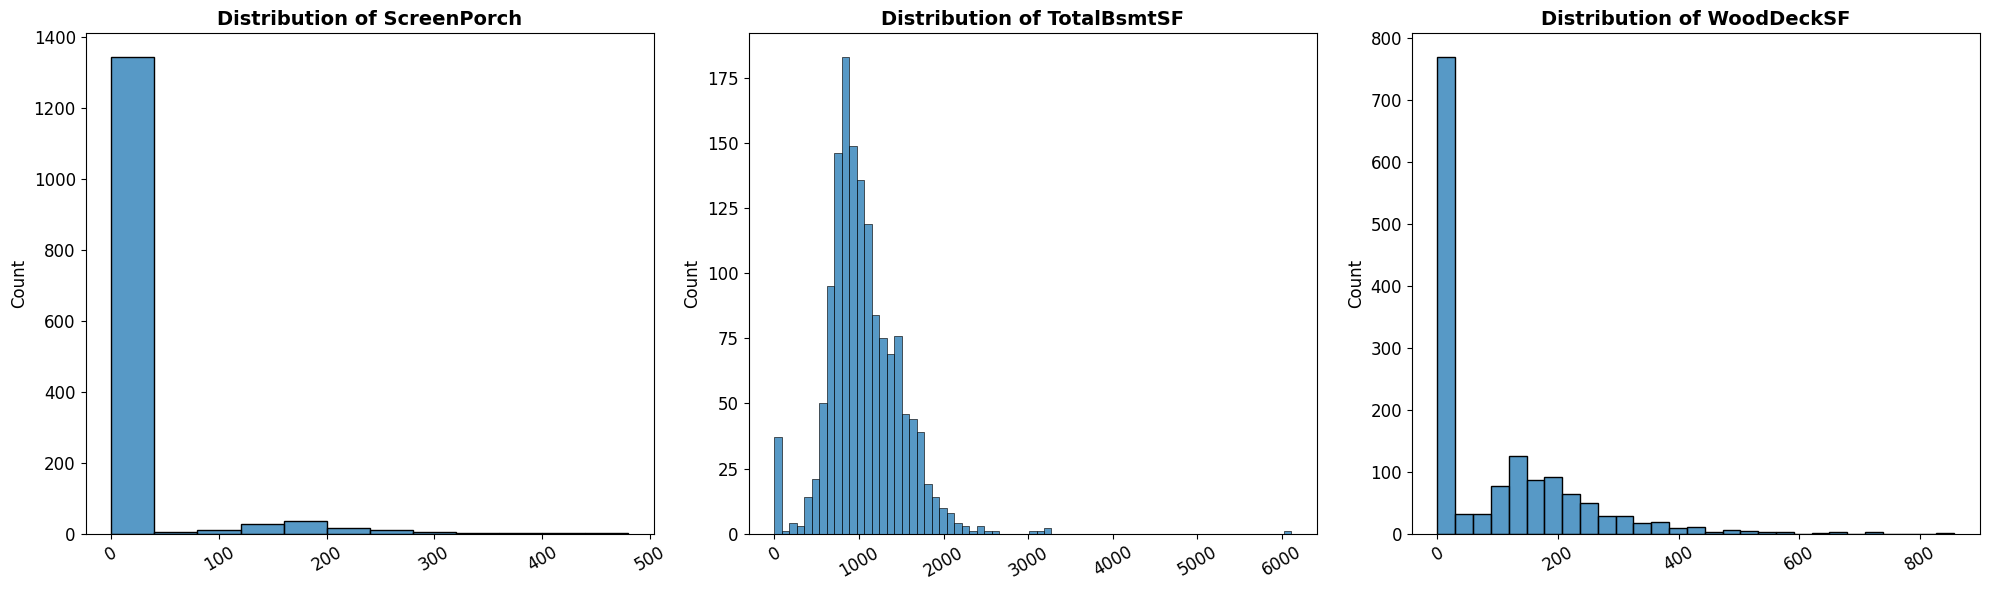

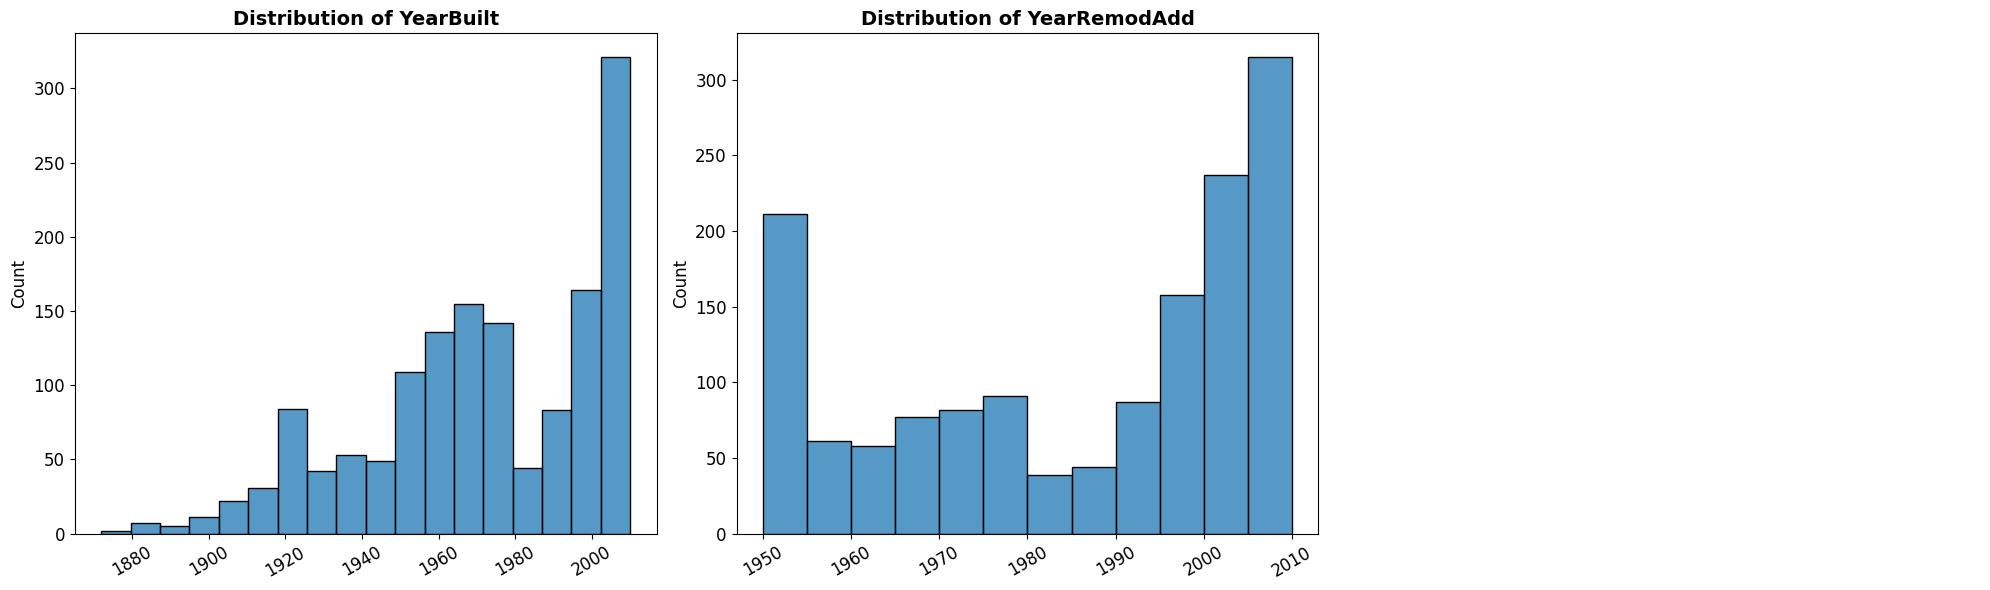

In [31]:
ncols = 3
nrows = 1

for i in range(0, len(continous_num_vars), ncols):
    chunk_vars = continous_num_vars[i:i + ncols]
    
    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        sns.histplot(data=train, x=var, ax=axs[j])
        axs[j].set_title(f"Distribution of {var}", fontsize=14, fontweight="bold")
        axs[j].set_xlabel("")
        axs[j].set_ylabel("Count", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout()
    plt.show()

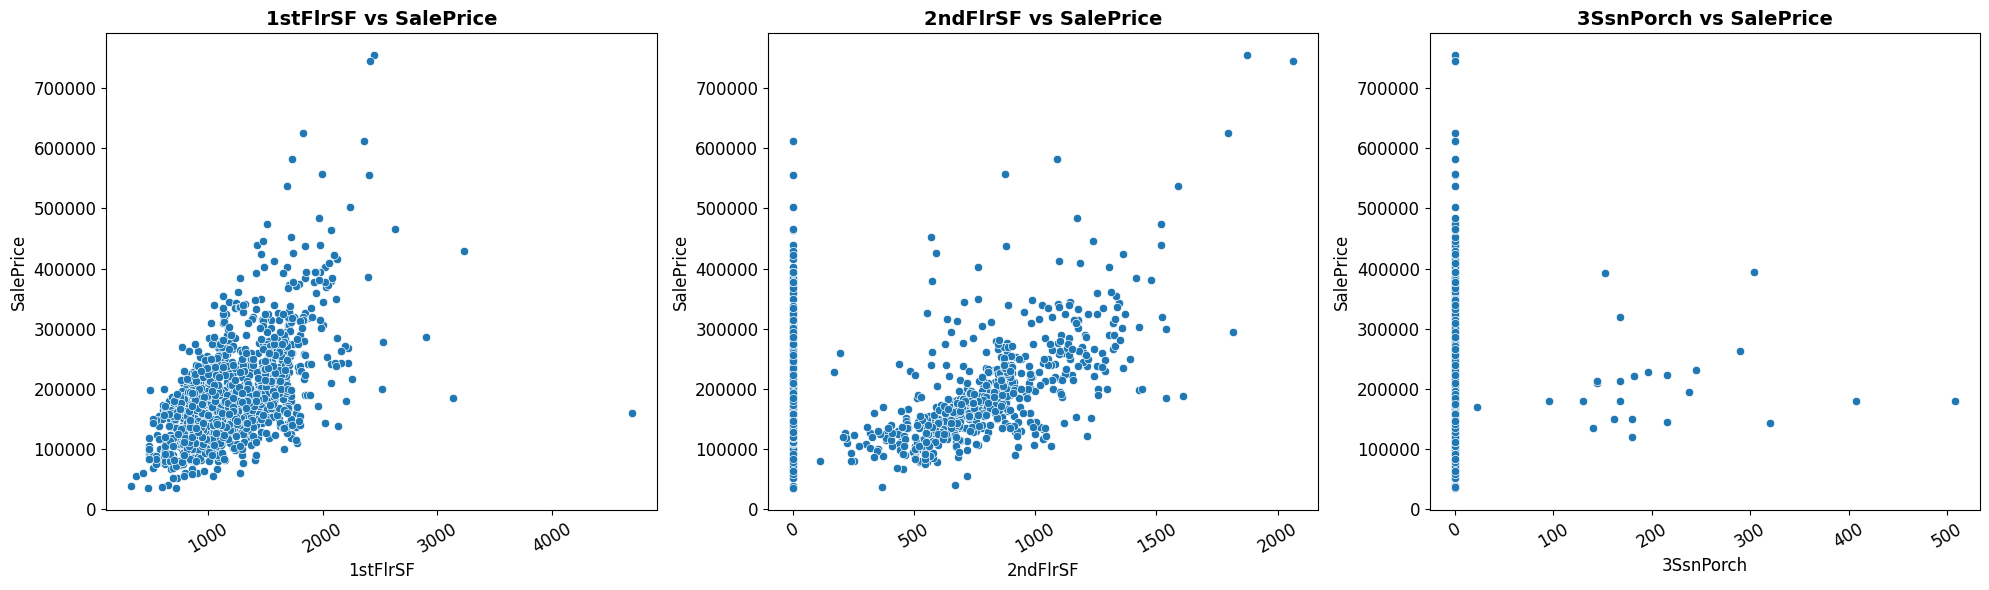

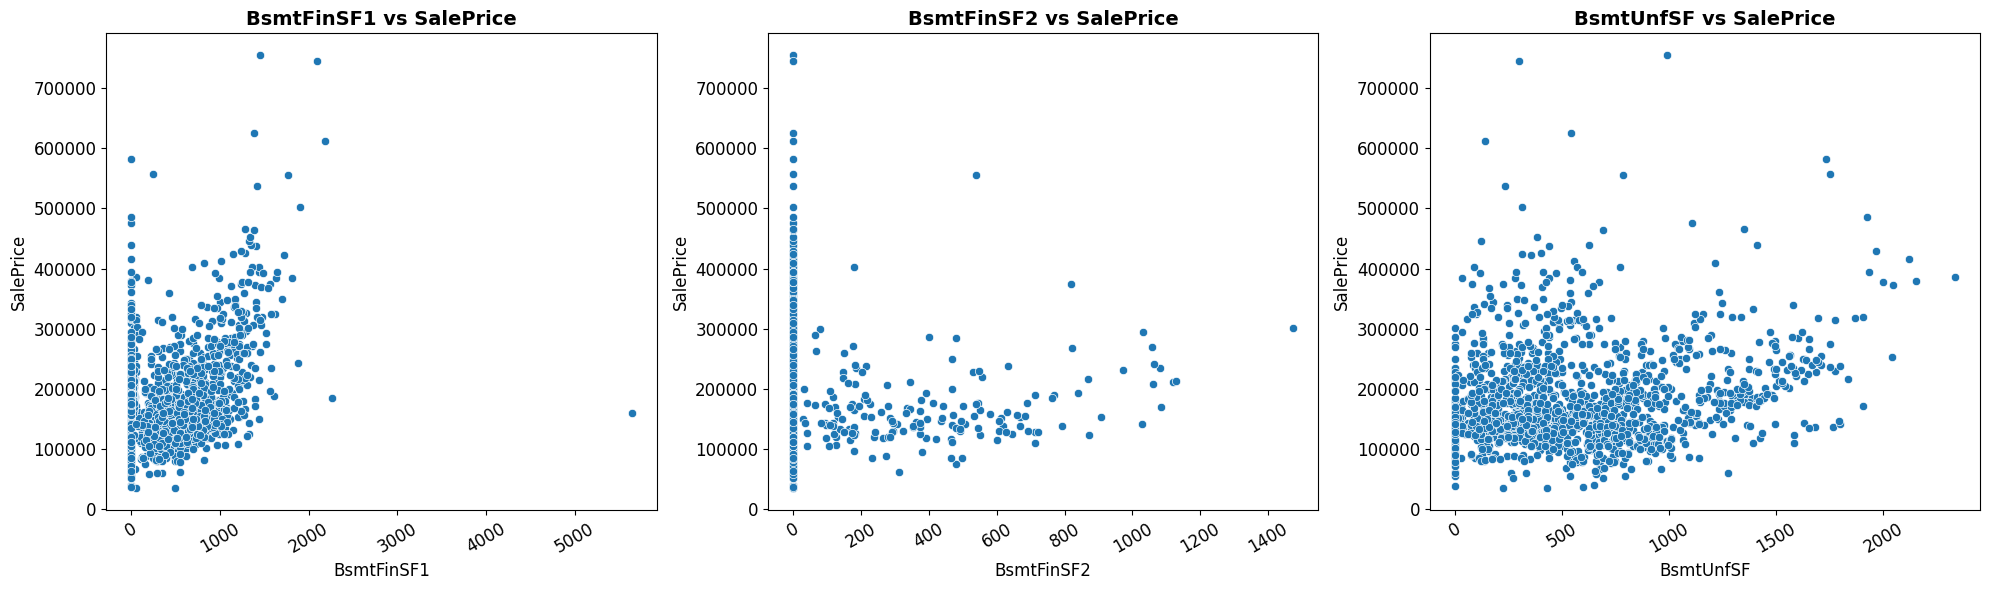

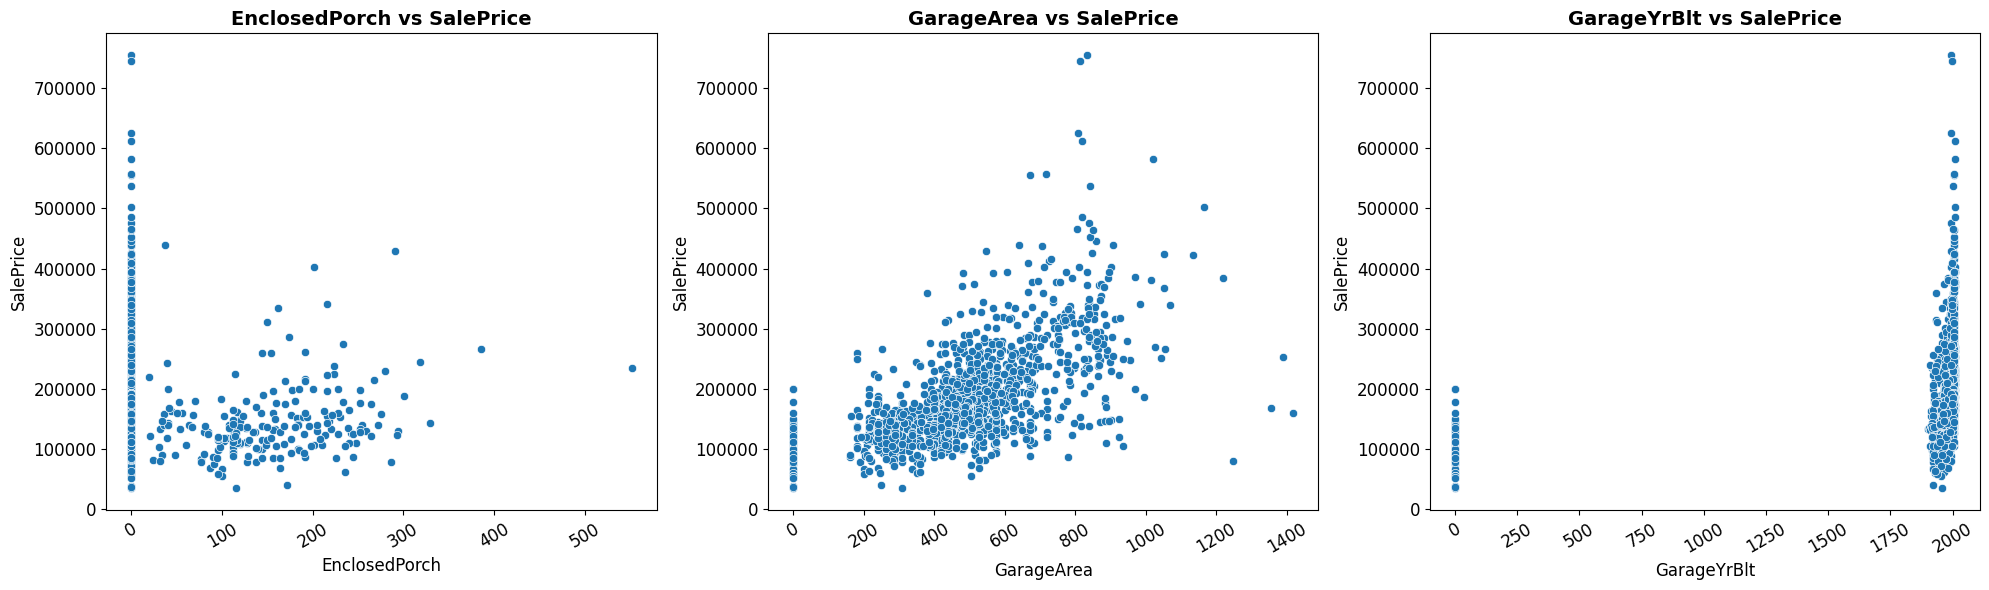

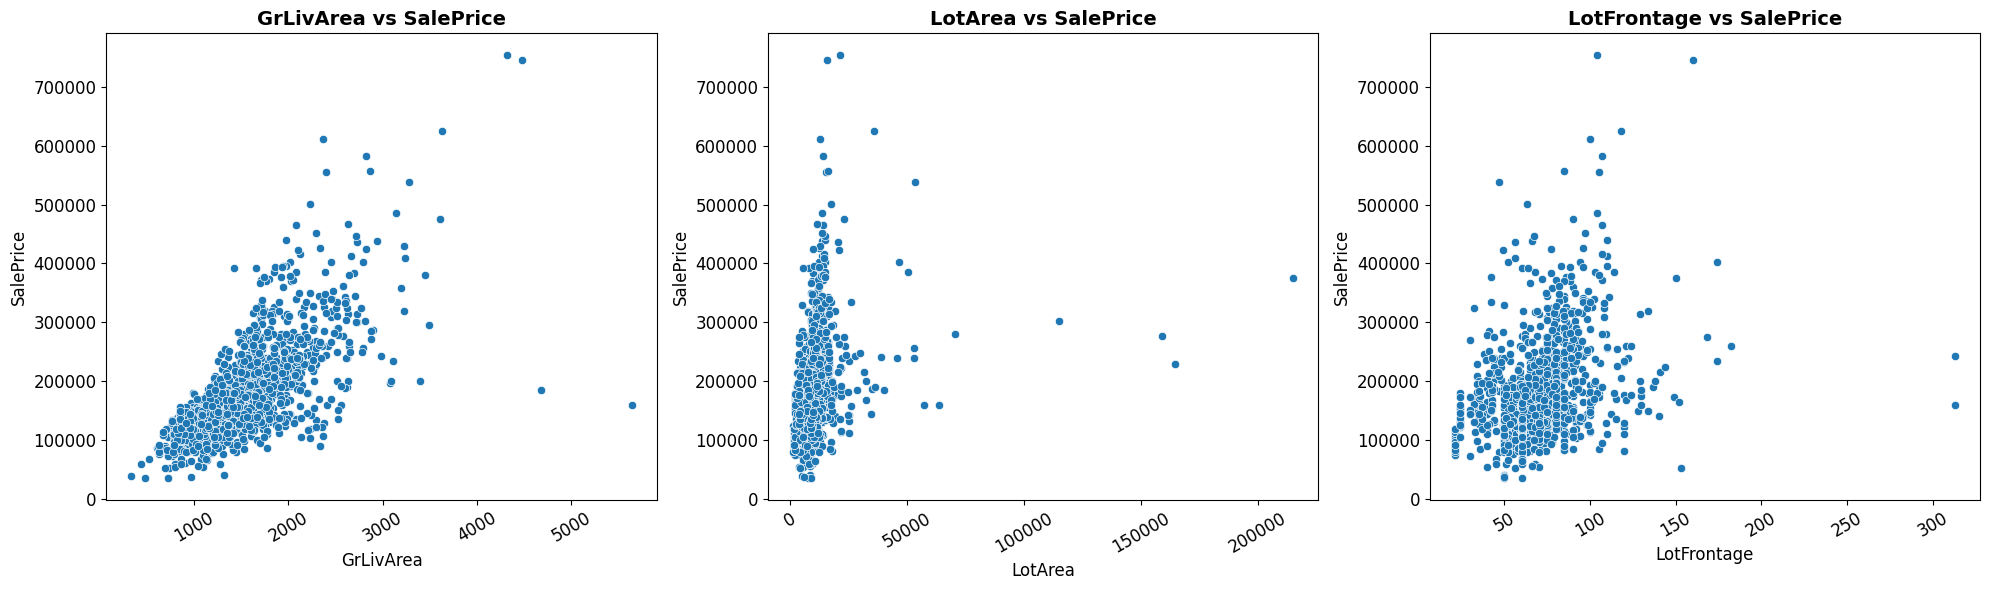

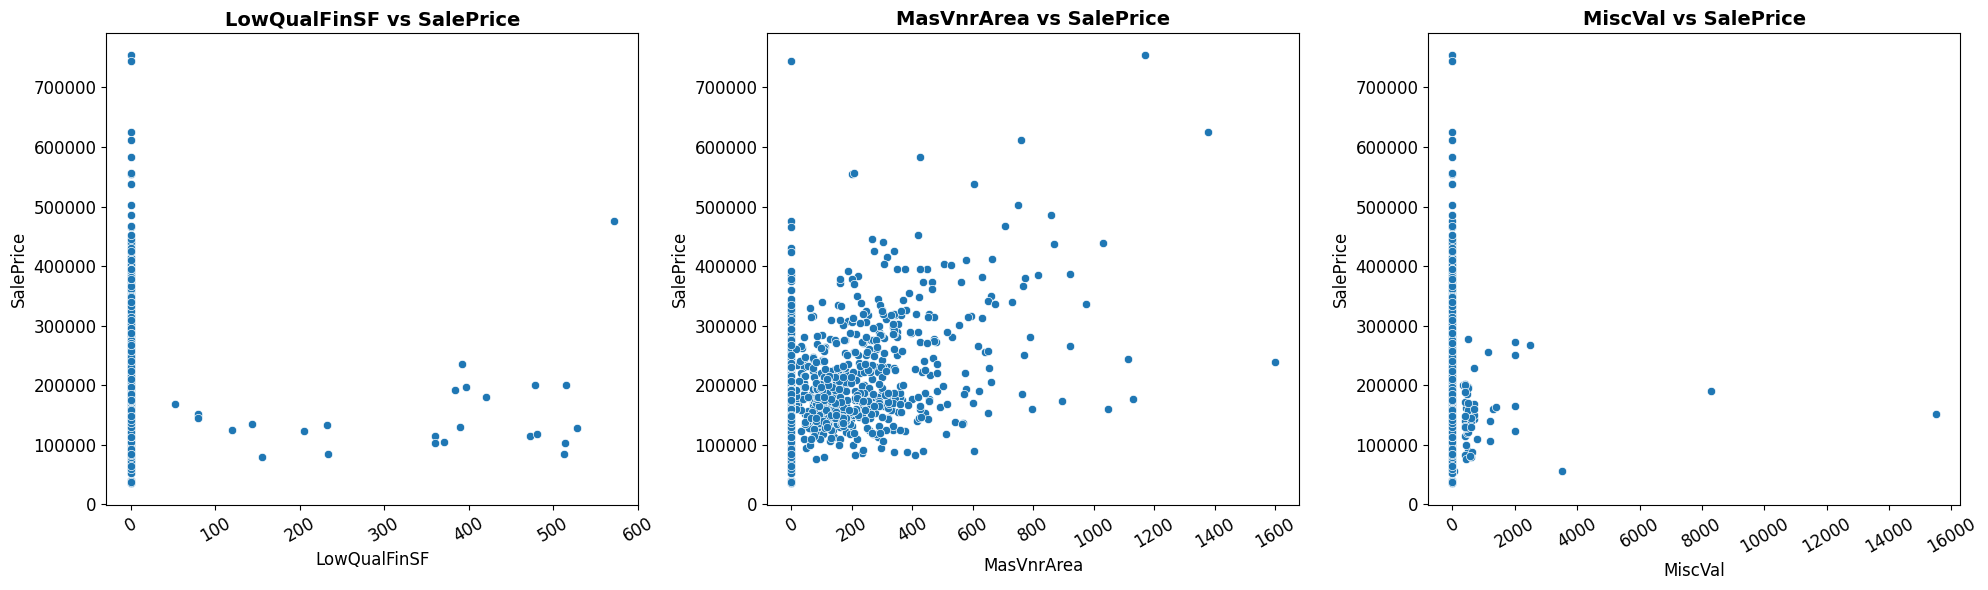

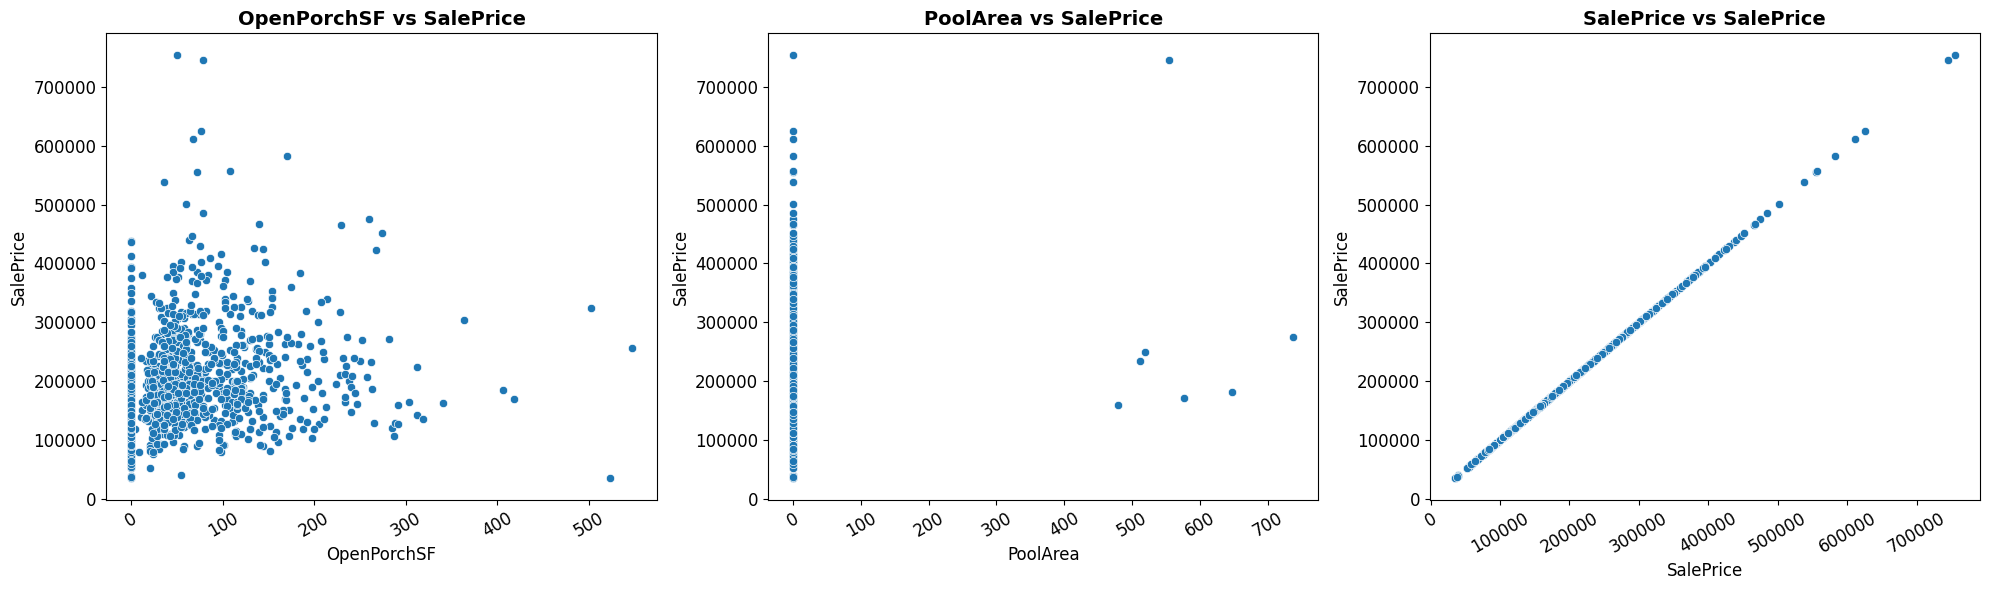

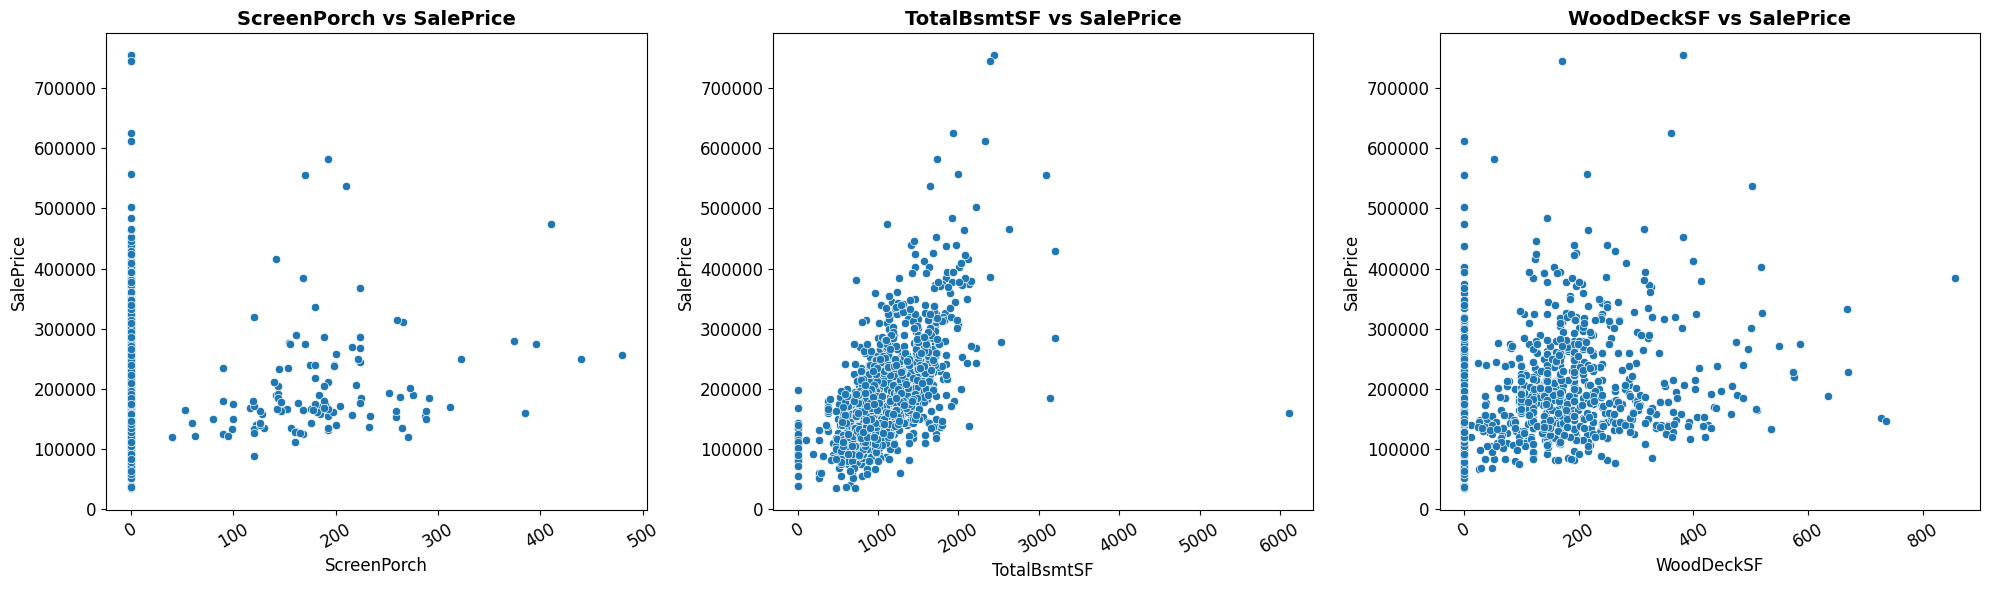

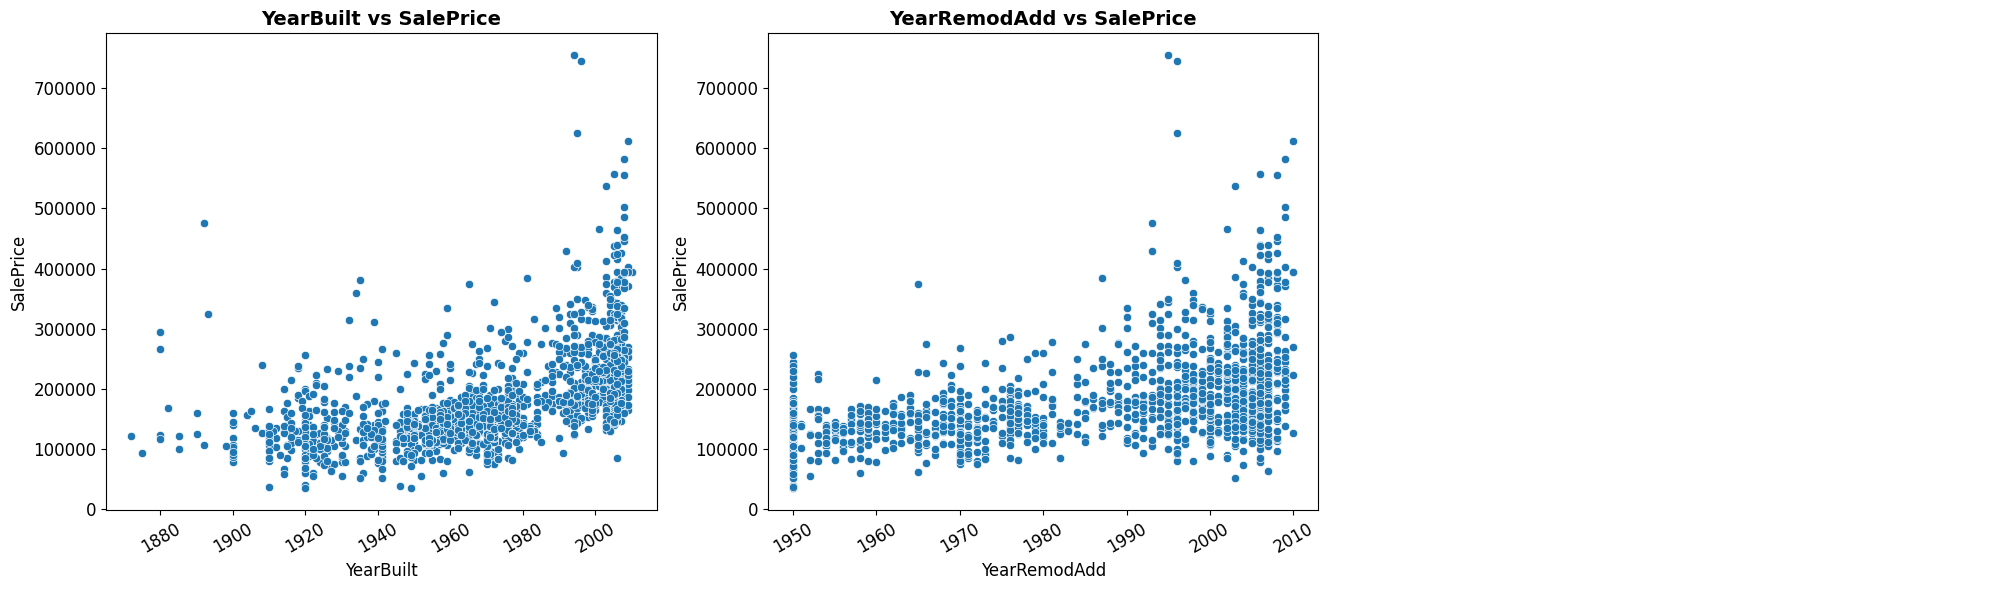

In [32]:
ncols = 3
nrows = 1

for i in range(0, len(continous_num_vars), ncols):
    chunk_vars = continous_num_vars[i:i + ncols]
    
    fig, axs = plt.subplots(ncols=ncols, nrows=nrows, figsize=(20, 6))
    axs = axs.flatten()
    
    for j, var in enumerate(chunk_vars):
        sns.scatterplot(data=train, x=var, y="SalePrice", ax=axs[j])
        axs[j].set_title(f"{var} vs SalePrice", fontsize=14, fontweight="bold")
        axs[j].set_xlabel(var, fontsize=12)
        axs[j].set_ylabel("SalePrice", fontsize=12)
        axs[j].tick_params(axis="x", rotation=30, labelsize=12)
        axs[j].tick_params(axis="y", labelsize=12)
    
    for j in range(len(chunk_vars), ncols):
        axs[j].axis('off')
        
    plt.tight_layout()
    plt.show()

at a first glance we can see some columns having potential outliers

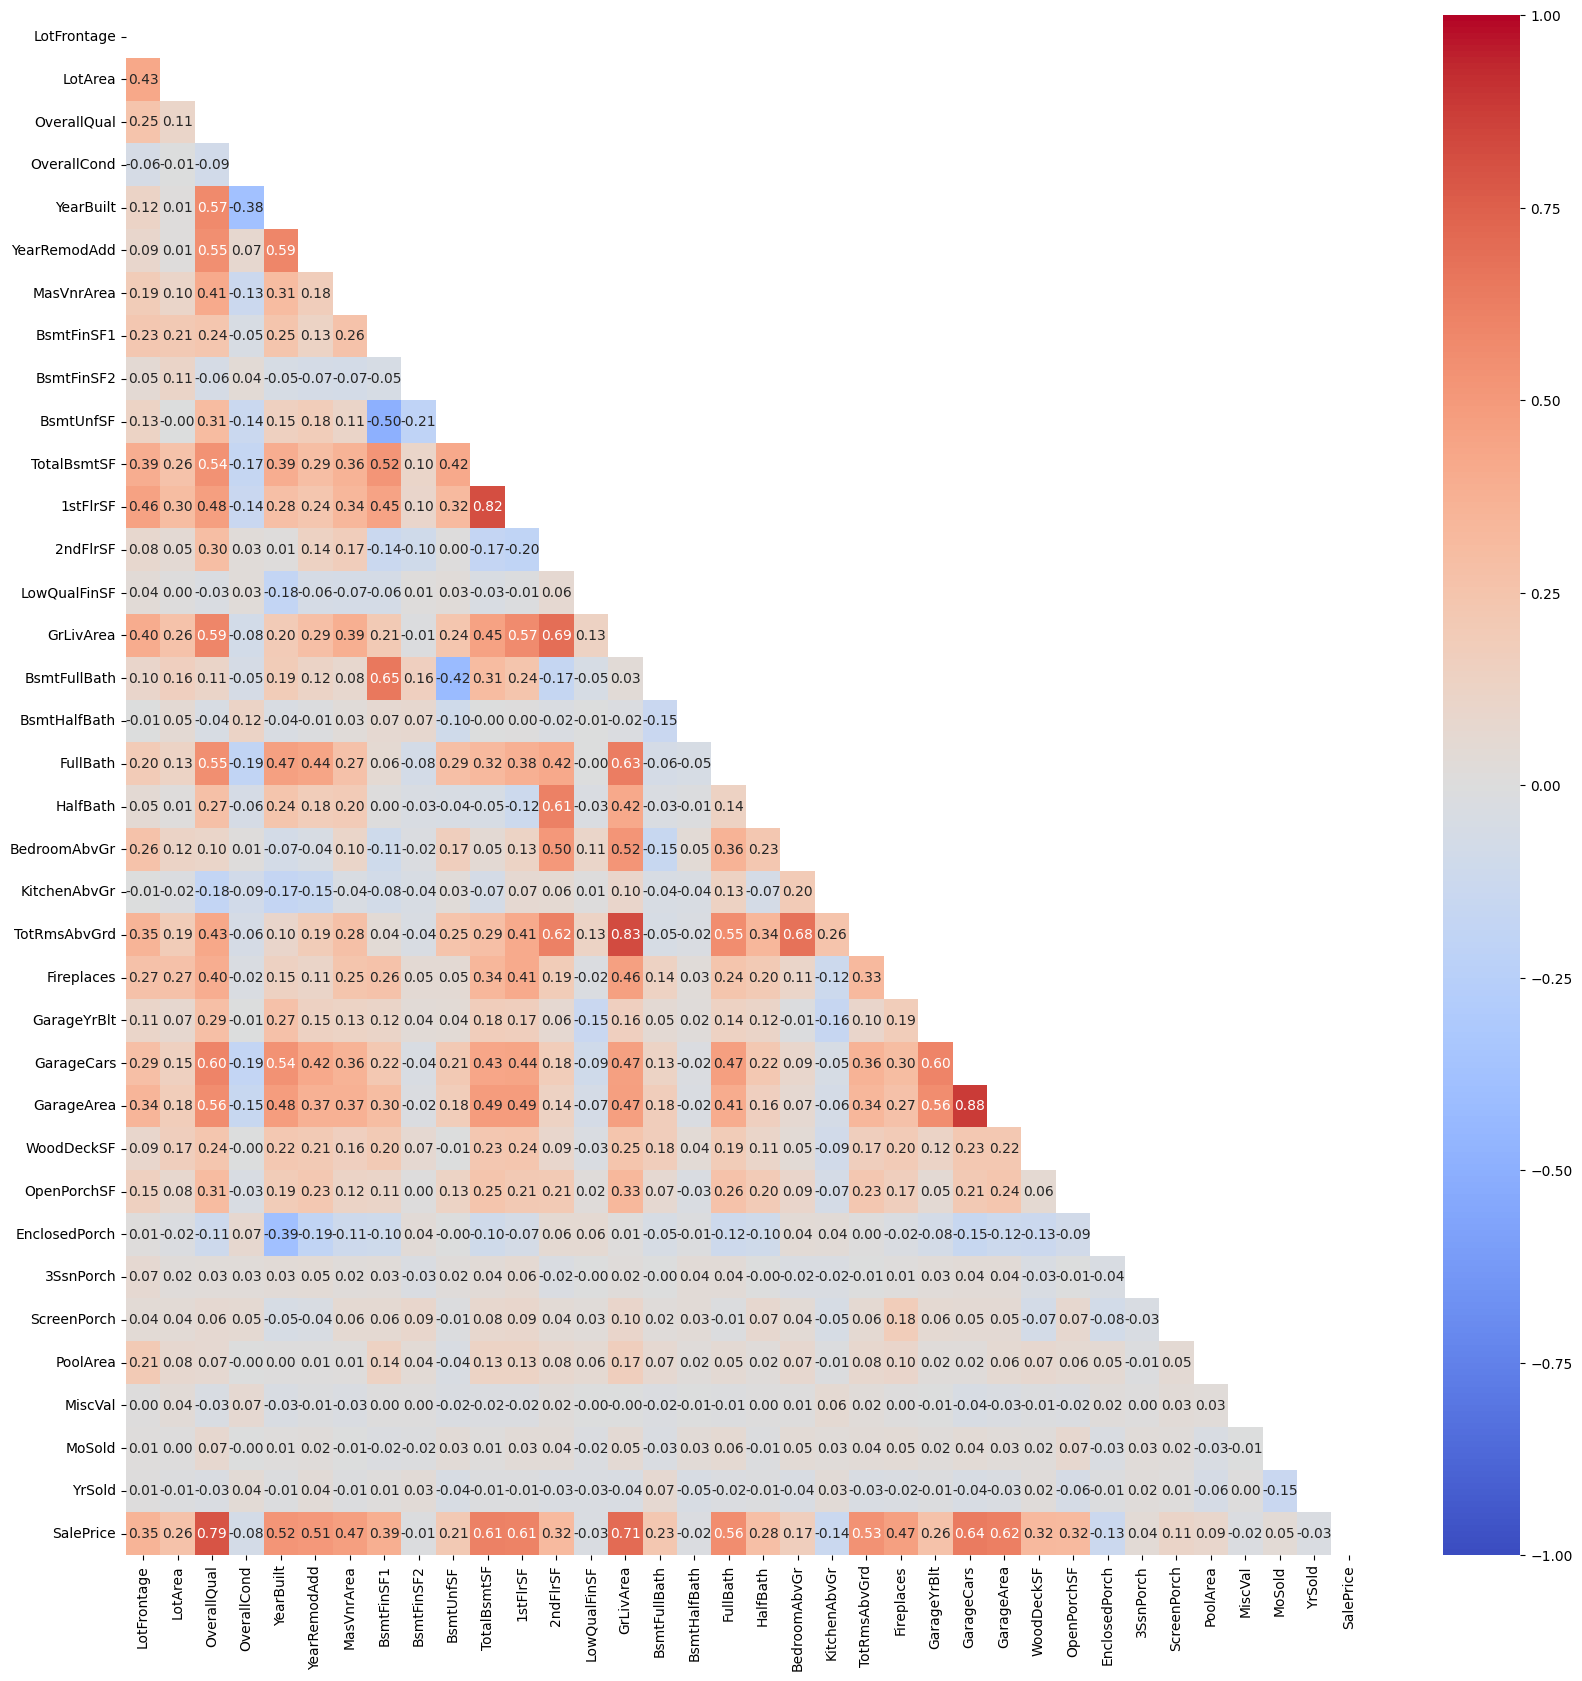

In [33]:
corr = train[num_vars].corr()
#corr = train.loc[(train[continous_num_vars] != 0).any(axis=1), num_vars].corr()
mask = np.triu(corr).astype(bool)
plt.figure(figsize=(20,20))
sns.heatmap(data = corr, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.show()

# Baseline Model

In [34]:
X = train.drop("SalePrice", axis=1)
y = train["SalePrice"]

cat_vars = X.select_dtypes("object").columns

X[cat_vars] = X[cat_vars].fillna("Missing")
X[cat_vars] = X[cat_vars].astype("category") # Catboost don't distinguish between category or object dtype, but XGBoost and LightGBM do

train_pool = Pool(data=X, label=y, cat_features=cat_vars.tolist())

params = {
    "loss_function": "RMSE",
    "eval_metric": "RMSE",
    "custom_metric": ["R2"],
    "random_seed": 42,
    "verbose": 0
}

cv_scores = cv(
    pool = train_pool,
    params = params,
    fold_count = 5,
    shuffle = True,
    partition_random_seed = 42
)

best_iteration = cv_scores["test-RMSE-mean"].idxmin()
print(f"Best Iteration: {best_iteration}")

best_rmse = cv_scores["test-RMSE-mean"].iloc[best_iteration]
best_r2 = cv_scores["test-R2-mean"].iloc[best_iteration]

print(f"Best Validation RMSE: {best_rmse:.4f}")
print(f"Best Validation R²:   {best_r2:.4f}")

Training on fold [0/5]

bestTest = 25576.7993
bestIteration = 949

Training on fold [1/5]

bestTest = 26309.47569
bestIteration = 965

Training on fold [2/5]

bestTest = 20874.78448
bestIteration = 999

Training on fold [3/5]

bestTest = 31700.26059
bestIteration = 950

Training on fold [4/5]

bestTest = 25493.54866
bestIteration = 999

Best Iteration: 999
Best Validation RMSE: 26003.0017
Best Validation R²:   0.8914


# SHAP Baseline Model Study

In [35]:
X = train.drop("SalePrice", axis=1)
y = train["SalePrice"]

cat_vars = X.select_dtypes("object").columns

X[cat_vars] = X[cat_vars].fillna("Missing")
X[cat_vars] = X[cat_vars].astype("category") # Catboost don't distinguish between category or object dtype, but XGBoost and LightGBM do

train_pool = Pool(
    data = X,
    label = y,
    cat_features = cat_vars.tolist()
)

model = CatBoostRegressor(verbose=0, random_state=42)
model.fit(train_pool)
explainer = shap.TreeExplainer(model)
#shap_values = explainer.shap_values(X)
shap_values = explainer(X)
least_important_indices = np.argsort(np.abs(shap_values.values).mean(axis=0))
max_vars = X.columns.shape[0]

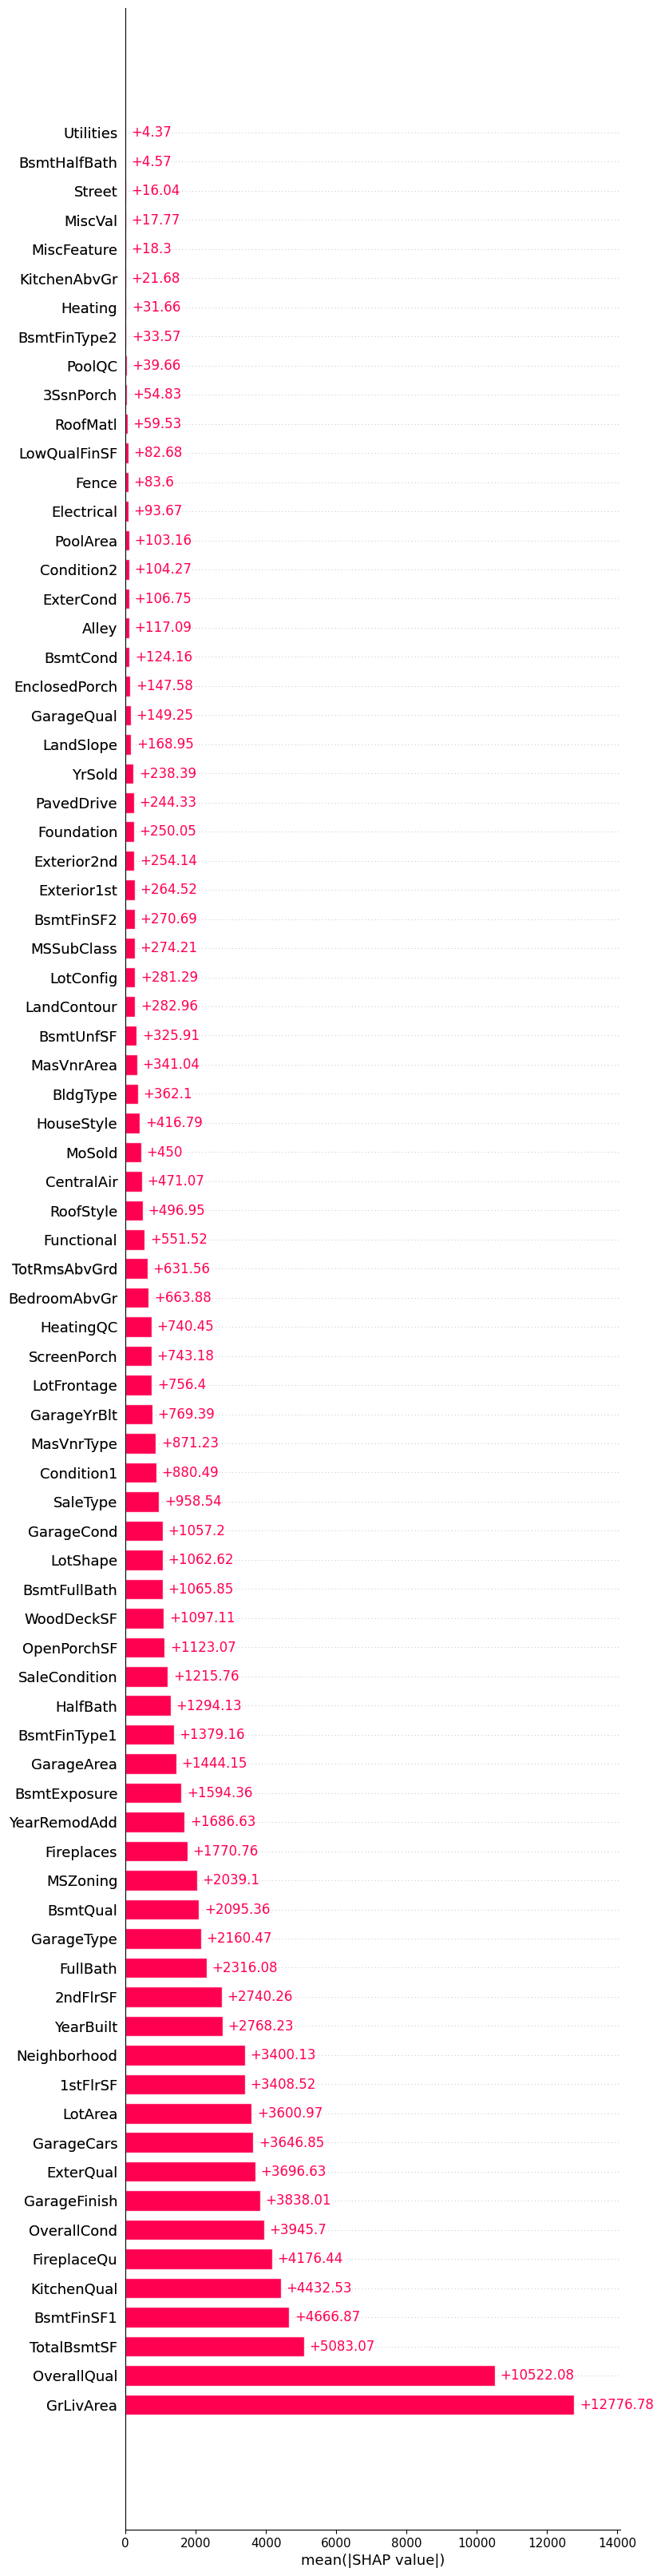

In [36]:
shap.plots.bar(shap_values, max_display=max_vars, order=least_important_indices, show=True)